# Strava as an Infrastructure for Social Aggregation: Network Structure and the Diffusion of Running

**Network analysis, machine learning and graph neural networks on five Strava running clubs (2019)**

---

## Research question

> To what extent does Strava function as an infrastructure for social aggregation, and how do higher-status athletes within its communities diffuse the practice of running to the contacts with whom they share activities?

## Data

The analysis uses the replication package of Franken, Bekhuis & Tolsma (2022): **five Strava running clubs (329 athletes) observed monthly during 2019** (12 waves). For every athlete and month the data report running frequency and volume, other sporting activity, and the *kudos* exchanged with the other members of the club. Kudos are Strava's lightweight form of recognition, and are used here as the observable social tie between athletes. The data are distributed in the **RSiena** format (arrays athlete × athlete × wave).

## Objectives and structure

The research question has two halves, which map onto two blocks of analysis.

| Block | Question | Method | Sections |
|---|---|---|---|
| **Part I: Data** | What does the data contain and how reliable is it? | Cleaning, documentation, exploratory analysis | 1 to 3 |
| **Part II: Aggregation** | Do kudos form real social structure (cohesion, reciprocity, hubs, strong ties)? Do high-status or high-commitment athletes occupy particular positions? | Social network analysis, permutation tests | 4 to 7 |
| **Part III: Diffusion** | Does exposure to contacts help to predict that an athlete will **run more often next month**? | Leakage-free temporal validation; XGBoost; Graph Neural Network (GraphSAGE) with control experiments | 8 to 10 |
| **Synthesis** | What do the results say about the research question, and what are the limits? | n/a | 11 |

## Key definitions used throughout

- **Commitment level** (`level`): running volume and frequency averaged over the year, standardised within the club, combined into one index and split at the club median. It measures *how much* an athlete runs, not skill.
- **Status** (`status`): an athlete is *high status* if the number of club members from whom they received kudos (in-degree) is above the club median. It captures recognition.
- **Strong tie:** two athletes exchange kudos **in the same month** (reciprocal network).
- **Outcome of Part III:** the weekly running-frequency category (`freq_run`, 0 to 7) **increases** from month *t* to month *t+1*.

## How to run this notebook (local machine or AWS / SageMaker)

1. Upload to the same folder as the notebook: the two helper modules `load_strava_clubs.py` and `club_dataframes.py`, and the RSiena `export/` folder (or set `RAW_DATA_S3_PREFIX` in the configuration cell to download it from S3).
2. Use a kernel with **PyTorch** installed (on SageMaker, a PyTorch image or `conda_pytorch_*` kernel). A GPU is optional: the graphs are small and CPU is sufficient. Other missing packages are installed automatically by the first code cell.
3. Run all cells from top to bottom (*Run All*). Every random procedure uses a fixed seed (`SEED = 7`).
4. The most expensive cell is the GNN experiment in section 10. For a fast test run, set `QUICK_RUN = True` in the configuration cell (fewer seeds, permutations and bootstrap replications).

## Reproducibility and rigour

- Random seeds are fixed everywhere.
- All predictive features are built **only from information available at month *t***; this is verified with an automatic *truncation test* (section 8.3), which includes a deliberately leaky negative control.
- Preprocessing statistics (means, standard deviations) are always computed on training rows only, and the test set is always a **single future month** (expanding-window, out-of-time validation).

# 0. Environment and configuration

All imports, paths, AWS settings and experiment switches are collected in this single section so that the rest of the notebook contains no environment-specific code.

In [19]:
import os, sys, io, json, copy, subprocess, importlib.util, warnings
from collections import Counter
from operator import itemgetter
from pathlib import Path

# ---- 1. Install missing packages (PyTorch itself must come with the kernel) ----------
REQUIRED = {"networkx": "networkx", "seaborn": "seaborn", "xgboost": "xgboost",
            "pyarrow": "pyarrow", "boto3": "boto3", "sklearn": "scikit-learn",
            "torch_geometric": "torch-geometric"}
missing = [pip for mod, pip in REQUIRED.items() if importlib.util.find_spec(mod) is None]
if missing:
    print("Installing:", missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
if importlib.util.find_spec("torch") is None:
    raise ImportError("PyTorch is not installed. Use a PyTorch kernel (e.g. conda_pytorch_*) "
                      "or run: pip install torch")

# ---- 2. Imports ----------------------------------------------------------------------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
import xgboost as xgb
import boto3
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.data import Data, Batch
from torch_geometric.nn import SAGEConv
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score, brier_score_loss

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)

# ---- 3. Reproducibility ---------------------------------------------------------------
SEED = 7
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ---- 4. Paths --------------------------------------------------------------------------
EXPORT_DIR = Path(os.environ.get("STRAVA_EXPORT_DIR", "."))   # i dati sono nella stessa cartella del notebook        # RSiena export folder
DATA_DIR = Path("data")                                                  # modelling tables
OUT_DIR = Path(os.environ.get("SM_OUTPUT_DATA_DIR", "outputs"))          # SageMaker output dir
for d in (DATA_DIR, OUT_DIR):
    d.mkdir(parents=True, exist_ok=True)

# ---- 5. AWS settings -------------------------------------------------------------------
BUCKET = "social-media-analysis-panel-ml-all-edges"
REGION = "eu-north-1"
S3_PREFIX = ""                # e.g. "processed/" if the files sit in a sub-folder of the bucket
RAW_DATA_S3_PREFIX = None     # e.g. "raw/export/" to download the RSiena export from S3
UPLOAD_TO_S3 = False          # True: upload the modelling tables (section 8.5) to the bucket

# ---- 6. Experiment switches ------------------------------------------------------------
QUICK_RUN = False             # True: fast smoke test (few seeds / permutations / bootstraps)
RUN_LEVEL_BLIND_ABLATION = True   # True: also run the GNN without own-level features (section 10)
N_PERM      = 500  if QUICK_RUN else 5000    # permutation tests (sections 6 and 7)
N_SEEDS     = 1    if QUICK_RUN else 5       # GNN random initialisations
N_BOOT      = 100  if QUICK_RUN else 1000    # pooled bootstrap (section 10)
N_BOOT_FOLD = 50   if QUICK_RUN else 500     # per-fold bootstrap (section 10)

print("Device:", DEVICE, "| QUICK_RUN:", QUICK_RUN)

Device: cuda | QUICK_RUN: False


# Part I: Data

# 1. Data loading

The raw data are stored in the RSiena format and are read with two helper modules, which must sit in the same folder as the notebook:

- `load_strava_clubs.load_clubs(path)` reads the export folder and returns a dictionary with one entry per club. Each entry contains the athletes (`nodes`), the monthly kudos array (`kudos`, athlete × athlete × 12 waves) and the behavioural matrices (`freq_run`, `time_run`, ..., athlete × 12 waves).
- `club_dataframes.build_frames(clubs)` converts these arrays into **long-format tables**: a panel with one row per athlete and month, and an edge list with one row per kudos tie and month.

The next cell checks that the inputs exist (and optionally downloads them from S3) before loading.

In [20]:
import os, shutil

for f in ("load_strava_clubs.py", "club_dataframes.py"):
    if os.path.exists(f):
        print(f"{f}: già presente nella cartella di lavoro")
    elif os.path.exists(f"export/{f}"):
        shutil.copy(f"export/{f}", f)
        print(f"{f}: copiato da export/")
    else:
        raise FileNotFoundError(f"{f} non trovato né qui né in export/. Cartella attuale: {os.getcwd()}")

print(os.getcwd())
print(os.listdir("."))

load_strava_clubs.py: già presente nella cartella di lavoro
club_dataframes.py: già presente nella cartella di lavoro
/home/sagemaker-user/export
['clubs.csv', 'load_strava_clubs.py', 'club_dataframes.py', 'friendship_nodes.csv', 'nodes.csv', 'friendship_edges.csv', 'kudos_edges.csv', 'Social_media_analysis_complete_official.ipynb', '.ipynb_checkpoints', 'data', 'outputs', '__pycache__', 'behavior_long.csv']


In [21]:
def ensure_raw_data(export_dir, bucket, region, prefix):
    """Make sure the RSiena export folder exists; optionally download it from S3."""
    if export_dir.exists() and any(export_dir.iterdir()):
        return
    if prefix is None:
        raise FileNotFoundError(
            f"RSiena export folder '{export_dir}' not found or empty. Upload it next to the "
            "notebook, set the STRAVA_EXPORT_DIR environment variable, or set RAW_DATA_S3_PREFIX.")
    s3_client = boto3.client("s3", region_name=region)
    n = 0
    for page in s3_client.get_paginator("list_objects_v2").paginate(Bucket=bucket, Prefix=prefix):
        for obj in page.get("Contents", []):
            if obj["Key"].endswith("/"):
                continue
            target = export_dir / Path(obj["Key"]).relative_to(prefix)
            target.parent.mkdir(parents=True, exist_ok=True)
            s3_client.download_file(bucket, obj["Key"], str(target))
            n += 1
    print(f"Downloaded {n} files from s3://{bucket}/{prefix} to {export_dir}")

ensure_raw_data(EXPORT_DIR, BUCKET, REGION, RAW_DATA_S3_PREFIX)

sys.path.insert(0, str(Path.cwd()))
for module in ("load_strava_clubs", "club_dataframes"):
    if importlib.util.find_spec(module) is None:
        raise ModuleNotFoundError(f"Helper module '{module}.py' not found. "
                                  "Place it in the same folder as the notebook.")
from load_strava_clubs import load_clubs
from club_dataframes import build_frames

clubs = load_clubs(str(EXPORT_DIR))
print("Clubs found:", list(clubs.keys()))

Clubs found: [1, 2, 3, 4, 5]


First inspection of the raw structure. For each club the table reports: number of athletes, shape of the kudos array (athlete × athlete × wave), shape of the running-frequency matrix (athlete × wave), and whether the friendship network is aligned.

In [22]:
for k, c in clubs.items():
    print(k, len(c["nodes"]), c["kudos"].shape, c["freq_run"].shape, c["friendship_aligned"])

# Example: the last club (athlete attributes and the first rows of the running-frequency matrix)
example_club = clubs[list(clubs)[-1]]
display(example_club["nodes"].head())
display(pd.DataFrame(example_club["freq_run"]).head())
print("Total running-frequency category per wave (example club):",
      np.nansum(example_club["freq_run"], axis=0))

1 27 (27, 27, 12) (27, 12) False
2 58 (58, 58, 12) (58, 12) False
3 159 (159, 159, 12) (159, 12) False
4 9 (9, 9, 12) (9, 12) False
5 76 (76, 76, 12) (76, 12) False


,club,node,gender,male,female,other,novice,start_year,entry_wave
0,5,1,M,1,0,0,7,2017,1
1,5,2,M,1,0,0,1,<=2011,1
2,5,3,M,1,0,0,3,2013,1
3,5,4,F,0,1,0,6,2016,1
4,5,5,O,0,0,1,8,2018,1


,0,1,2,3,4,5,6,7,8,9,10,11
0,2.0,2.0,2.0,2.0,3.0,2.0,2.0,2.0,2.0,3.0,4.0,4.0
1,2.0,1.0,5.0,1.0,1.0,4.0,2.0,3.0,3.0,3.0,3.0,4.0
2,4.0,3.0,4.0,5.0,6.0,4.0,5.0,4.0,3.0,4.0,4.0,3.0
3,4.0,4.0,4.0,4.0,6.0,6.0,5.0,7.0,6.0,5.0,5.0,6.0
4,4.0,4.0,5.0,2.0,4.0,5.0,4.0,4.0,5.0,5.0,5.0,6.0


Total running-frequency category per wave (example club): [247. 212. 258. 249. 280. 248. 249. 274. 271. 259. 255. 243.]


# 2. Data preparation

The RSiena format is not directly usable for analysis with `pandas`. This section converts the arrays into long-format tables, documents every variable, and builds the athlete-level and tie-level tables used in the rest of the notebook.

## 2.1 From RSiena arrays to panel and edge tables

`build_frames` returns one panel and one edge table per club. The panel has one row for each athlete and month (balanced panel of 12 waves). In the panel, **`NaN` in the running, other-sport and kudos variables means that the athlete has not yet entered the club** (this is verified in section 3.3).

In [23]:
panels, edges = build_frames(clubs)
assert len(panels) == 5 and len(edges) == 5, "the notebook expects the five clubs of the dataset"

club1, club2, club3, club4, club5 = [panels[i] for i in sorted(panels)]
edge1, edge2, edge3, edge4, edge5 = [edges[i] for i in sorted(edges)]

club1.info()
club1.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 324 entries, 0 to 323
Data columns (total 18 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   club        324 non-null    int64  
 1   node        324 non-null    int64  
 2   wave        324 non-null    int64  
 3   freq_run    314 non-null    float64
 4   time_run    314 non-null    float64
 5   freq_other  324 non-null    float64
 6   time_other  324 non-null    float64
 7   winter      324 non-null    float64
 8   kudos_out   314 non-null    float64
 9   kudos_in    314 non-null    float64
 10  gender      324 non-null    object 
 11  male        324 non-null    int64  
 12  female      324 non-null    int64  
 13  other       324 non-null    int64  
 14  novice      324 non-null    int64  
 15  start_year  324 non-null    object 
 16  entry_wave  324 non-null    int64  
 17  in_club     324 non-null    bool   
dtypes: bool(1), float64(7), int64(8), object(2)
memory usage: 43.5+ KB


,club,node,wave,freq_run,time_run,freq_other,time_other,winter,kudos_out,kudos_in,gender,male,female,other,novice,start_year,entry_wave,in_club
0,1,1,1,4.0,4.0,0.0,0.0,1.0,1.0,1.0,M,1,0,0,5,2015,1,True
1,1,1,2,3.0,3.0,1.0,1.0,1.0,1.0,1.0,M,1,0,0,5,2015,1,True
2,1,1,3,3.0,3.0,1.0,1.0,1.0,1.0,1.0,M,1,0,0,5,2015,1,True
3,1,1,4,3.0,3.0,1.0,2.0,0.0,1.0,1.0,M,1,0,0,5,2015,1,True
4,1,1,5,2.0,2.0,1.0,2.0,0.0,1.0,1.0,M,1,0,0,5,2015,1,True


The output above shows the panel of the first club with its variables and data types. The next two tables give the number of athletes per club and the distribution of the Strava-tenure category (`novice`: 1 = first activity in 2011 or earlier, 9 = 2019; it measures *tenure on Strava*, not running experience).

In [24]:
all_pan = pd.concat([club1, club2, club3, club4, club5], ignore_index=True)
display(all_pan.groupby("club")["node"].nunique().rename("athletes").to_frame())
display(all_pan.groupby(["club", "novice"])["node"].nunique().unstack())

,athletes
club,
1,27
2,58
3,159
4,9
5,76


novice,1,2,3,4,5,6,7,8,9
club,,,,,,,,,
1,1.0,2.0,2.0,5.0,5.0,1.0,3.0,7.0,1.0
2,11.0,4.0,5.0,10.0,9.0,3.0,6.0,7.0,3.0
3,12.0,6.0,16.0,5.0,25.0,23.0,32.0,32.0,8.0
4,NaN,NaN,1.0,2.0,NaN,NaN,4.0,1.0,1.0
5,6.0,2.0,7.0,3.0,14.0,10.0,17.0,11.0,6.0


## 2.2 Column renaming and variable documentation

For presentation purposes the variables are given self-explanatory names in `nodes_df`; the analysis below keeps the **original column names** of the replication package so that the results can be traced back to it. The documentation table in the following cell lists every variable of the panel and of the edge table, and checks that no column is left undocumented.

In [25]:
all_pan = all_pan.drop(columns=["Unnamed: 0"], errors="ignore")

# Readable version of the panel (used for documentation only)
nodes_df = all_pan.rename(columns={
    "male": "is_male", "female": "is_female", "other": "is_other",
    "novice": "experience_level",
    "freq_other": "freq_other_category", "time_other": "time_other_category"})

print("Original columns:", list(all_pan.columns))
print("Readable columns:", list(nodes_df.columns))

Original columns: ['club', 'node', 'wave', 'freq_run', 'time_run', 'freq_other', 'time_other', 'winter', 'kudos_out', 'kudos_in', 'gender', 'male', 'female', 'other', 'novice', 'start_year', 'entry_wave', 'in_club']
Readable columns: ['club', 'node', 'wave', 'freq_run', 'time_run', 'freq_other_category', 'time_other_category', 'winter', 'kudos_out', 'kudos_in', 'gender', 'is_male', 'is_female', 'is_other', 'experience_level', 'start_year', 'entry_wave', 'in_club']


In [26]:
# ========================================
#  Variables Documentation
# ========================================
# Documents the variables of the club panel and edge DataFrames.
# Source of the data: replication package of Franken, Bekhuis & Tolsma (2022),
# five Strava running clubs observed monthly in 2019.
#
# By default the column names are the ORIGINAL ones (club, node, wave, freq_run, ...).
# If you apply relabel() from club_dataframes.py, set USE_NEW_NAMES = True.

USE_NEW_NAMES = False

print("\n" + "-" * 70)
print("2. Variables Explanation")
print("-" * 70 + "\n")

# Documentation written with the new, clearer names
panel_variable_docs = {
    # --- identifiers ---
    'club': 'Club ID (1-5); five Strava clubs',
    'node': 'Athlete ID within the club (1, 2, 3, ...); unique only together with club',
    'wave': 'Monthly observation in 2019 (1 = January, ..., 12 = December)',
    # --- behaviour (running) ---
    'run_freq_cat': 'Running frequency, weekly category 0-7 (ceil of monthly runs / 4, capped at 7)',
    'run_hours_cat': 'Running volume, weekly hours category 0-7 (club 5: 0-9; ceil of monthly hours / 4)',
    # --- behaviour (other sports) ---
    'other_freq_cat': 'Frequency of other activities (cycling and other sports), weekly category 0-7',
    'other_hours_cat': 'Volume of other activities (cycling and other sports), weekly hours category 0-7',
    # --- network (kudos) ---
    'kudos_out_ties': 'Number of club members the athlete gave at least one kudos to in that month',
    'kudos_in_ties': 'Number of club members the athlete received at least one kudos from in that month',
    # --- athlete characteristics ---
    'gender': 'Gender label: M = male, F = female, O = other (missing if not available)',
    'male': 'Is male? (1 = Yes, 0 = No)',
    'female': 'Is female? (1 = Yes, 0 = No)',
    'other': 'Other gender? (1 = Yes, 0 = No)',
    'start_year_cat': 'Year of first activity recorded on Strava, coded 1 (2011 or earlier) to 9 (2019); '
                      'lower = longer Strava tenure, NOT running experience',
    'start_year': 'Label of the start-year category (e.g. "2015")',
    # --- membership and time ---
    'entry_wave_est': 'Estimated month of entry into the club (first month with any activity); 1 = present from the start',
    'in_club': 'Is the athlete already in the club in this month? (True/False)',
    'winter_dummy': 'Winter indicator defined by the authors (1 in waves 1-3, 0 otherwise)',
}

edge_variable_docs = {
    'club': 'Club ID (1-5)',
    'wave': 'Monthly observation in 2019 (1 = January, ..., 12 = December)',
    'giver': 'Athlete (node) who gave at least one kudos in that month',
    'receiver': 'Athlete (node) who received at least one kudos in that month',
}

# Original column name -> new name (same mapping as PANEL_LABELS / EDGE_LABELS)
ORIGINAL_TO_NEW = {
    'freq_run': 'run_freq_cat', 'time_run': 'run_hours_cat',
    'freq_other': 'other_freq_cat', 'time_other': 'other_hours_cat',
    'winter': 'winter_dummy', 'kudos_out': 'kudos_out_ties', 'kudos_in': 'kudos_in_ties',
    'novice': 'start_year_cat', 'entry_wave': 'entry_wave_est',
}
EDGE_ORIGINAL_TO_NEW = {'source': 'giver', 'target': 'receiver'}

if not USE_NEW_NAMES:   # show the original column names instead
    new_to_old = {new: old for old, new in ORIGINAL_TO_NEW.items()}
    panel_variable_docs = {new_to_old.get(k, k): v for k, v in panel_variable_docs.items()}
    new_to_old_edges = {new: old for old, new in EDGE_ORIGINAL_TO_NEW.items()}
    edge_variable_docs = {new_to_old_edges.get(k, k): v for k, v in edge_variable_docs.items()}


def print_documentation(title, docs):
    print(title)
    for var, desc in docs.items():
        print(f"  • {var:16} → {desc}")
    print()


def check_documentation(df, docs, name):
    """Warn if a column is not documented, or a documented variable is missing from the data."""
    undocumented = [c for c in df.columns if c not in docs]
    missing = [v for v in docs if v not in df.columns]
    print(f"{name}: {len(undocumented)} undocumented column(s) {undocumented}, "
          f"{len(missing)} documented variable(s) not in the data {missing}")


print_documentation("CLUB PANEL VARIABLES (one row per athlete and month):", panel_variable_docs)
print_documentation("KUDOS EDGE VARIABLES (one row per kudos tie and month):", edge_variable_docs)

print("NOTES:")
print("  • Missing values (NaN) in the running, other-sport and kudos variables mean the athlete")
print("    is not yet in the club.")
print("  • Frequency and hours variables are ordinal weekly categories (0-7), not raw counts.")
print("  • The kudos in/out variables count distinct partners (binary ties), not the number of kudos.")

# Optional check (works if club1 and edge1 are already defined in the notebook)
if 'club1' in globals() and 'edge1' in globals():
    print()
    check_documentation(club1, panel_variable_docs, "club1")
    check_documentation(edge1, edge_variable_docs, "edge1")


----------------------------------------------------------------------
2. Variables Explanation
----------------------------------------------------------------------

CLUB PANEL VARIABLES (one row per athlete and month):
  • club             → Club ID (1-5); five Strava clubs
  • node             → Athlete ID within the club (1, 2, 3, ...); unique only together with club
  • wave             → Monthly observation in 2019 (1 = January, ..., 12 = December)
  • freq_run         → Running frequency, weekly category 0-7 (ceil of monthly runs / 4, capped at 7)
  • time_run         → Running volume, weekly hours category 0-7 (club 5: 0-9; ceil of monthly hours / 4)
  • freq_other       → Frequency of other activities (cycling and other sports), weekly category 0-7
  • time_other       → Volume of other activities (cycling and other sports), weekly hours category 0-7
  • kudos_out        → Number of club members the athlete gave at least one kudos to in that month
  • kudos_in         → Numb

## 2.3 Athlete-level table and aggregated edges

Two derived tables are used by the network analysis:

- **`ath`**: one row per athlete, with yearly averages of running volume (`time_run`) and frequency (`freq_run`), the kudos given/received per month (`kudos_out_mean`, `kudos_in_mean`), and the time-invariant attributes. Running volume and frequency are standardised **within each club** (z-scores, because club 5 uses a wider scale for volume) and averaged into an `intensity` index. Athletes at or above the club median of `intensity` are labelled **`level = "high"`** (high commitment), the others **`"low"`**.
- **`edges_agg`**: the monthly kudos edge list collapsed to one row per (club, giver, receiver) pair, with `weight` = **number of months in which kudos were given**.

In [27]:
ath = (all_pan.groupby(["club", "node"])
              .agg(time_run=("time_run", "mean"),
                   freq_run=("freq_run", "mean"),
                   kudos_out_mean=("kudos_out", "mean"),   # avg. partners given kudos to per month
                   kudos_in_mean=("kudos_in", "mean"),     # avg. partners received kudos from per month
                   kudos_out_max=("kudos_out", "max"),
                   kudos_in_max=("kudos_in", "max"),
                   months_active=("kudos_out", "count"),   # months in the club (non-NaN)
                   gender=("gender", "first"),
                   novice=("novice", "first"),
                   entry_wave=("entry_wave", "first"))
              .reset_index())

# standardise within the club (z-score) and combine volume and frequency
for v in ["time_run", "freq_run"]:
    ath[v + "_z"] = ath.groupby("club")[v].transform(lambda s: (s - s.mean()) / s.std())
ath["intensity"] = ath[["time_run_z", "freq_run_z"]].mean(axis=1)

# high commitment = at or above the median of the athlete's own club
ath["level"] = np.where(
    ath["intensity"] >= ath.groupby("club")["intensity"].transform("median"), "high", "low")
ath.info()

# Edge aggregation: weight = number of months with at least one kudos from source to target
all_edges = pd.concat([edge1, edge2, edge3, edge4, edge5], ignore_index=True)
edges_agg = (all_edges.groupby(["club", "source", "target"])
                      .size().rename("weight").reset_index())
edges_agg.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 329 entries, 0 to 328
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   club            329 non-null    int64  
 1   node            329 non-null    int64  
 2   time_run        329 non-null    float64
 3   freq_run        329 non-null    float64
 4   kudos_out_mean  329 non-null    float64
 5   kudos_in_mean   329 non-null    float64
 6   kudos_out_max   329 non-null    float64
 7   kudos_in_max    329 non-null    float64
 8   months_active   329 non-null    int64  
 9   gender          328 non-null    object 
 10  novice          329 non-null    int64  
 11  entry_wave      329 non-null    int64  
 12  time_run_z      329 non-null    float64
 13  freq_run_z      329 non-null    float64
 14  intensity       329 non-null    float64
 15  level           329 non-null    object 
dtypes: float64(9), int64(5), object(2)
memory usage: 41.3+ KB


,club,source,target,weight
0,1,1,8,12
1,1,1,15,1
2,1,2,8,12
3,1,2,15,2
4,1,2,17,12


# 3. Exploratory data analysis

This section describes the composition of the clubs, the missing-data structure, the distributions and temporal trends of the key variables, and the relationships between them. It also identifies the features of the data that constrain the later analysis (club-specific scales, late entries, small clubs).

## 3.1 Composition of the clubs

In [28]:
# ========================================
#  EDA
# ========================================


# The panel has one row per athlete AND month (n athletes x 12 waves).
# Counting people requires one row per athlete, so we keep a single row for each (club, node).
athletes_ed = all_pan.drop_duplicates(subset=["club", "node"])

# Column names: works both with the original names and after relabel() from club_dataframes.py
# (relabel renames novice -> start_year_cat; the gender columns keep the same names).
GENDER_COLS = {"Men": "male", "Women": "female", "Other gender": "other"}
EXPERIENCE_COL = next(c for c in ("start_year_cat", "novice") if c in athletes_ed.columns)
print(f"Experience column used: {EXPERIENCE_COL}")

print("\n" + "-" * 70)
print("3. EDA PROCESS")
print("-" * 70 + "\n")

print("CLUB DISTRIBUTION AND EDA:\n")
for club in sorted(athletes_ed["club"].unique()):
    club_data = athletes_ed[athletes_ed["club"] == club]
    n_people = len(club_data)

    print(f"CLUB {int(club)}:")
    print(f"  Total people: {n_people}  (monthly observations: {int((all_pan['club'] == club).sum())})")

    counted = 0
    for label, col in GENDER_COLS.items():
        n = int(club_data[col].sum())
        counted += n
        print(f"  {label}: {n}")
    print(f"  Gender not available: {n_people - counted}")

    # EXPERIENCE_COL = year of first activity recorded on Strava (1 = 2011 or earlier ... 9 = 2019)
    # -> it measures Strava tenure, not running ability
    exp_mean = club_data[EXPERIENCE_COL].mean()
    exp_std = club_data[EXPERIENCE_COL].std()

    if pd.isna(exp_mean):
        tenure = "N/A"
    elif exp_mean < 3.5:
        tenure = "LONG STRAVA TENURE"       # on average first activity in 2013 or earlier
    elif exp_mean < 6.5:
        tenure = "MEDIUM STRAVA TENURE"     # on average first activity in 2014-2016
    else:
        tenure = "RECENT STRAVA USERS"      # on average first activity in 2017-2019

    print(f"  Average Strava tenure category: {exp_mean:.1f} (std {exp_std:.1f}) -> {tenure}")
    print()

# Sanity check: people per club must equal the club sizes of the dataset
print("People per club:", athletes_ed.groupby("club")["node"].nunique().to_dict())
print("Total people:", len(athletes_ed))

Experience column used: novice

----------------------------------------------------------------------
3. EDA PROCESS
----------------------------------------------------------------------

CLUB DISTRIBUTION AND EDA:

CLUB 1:
  Total people: 27  (monthly observations: 324)
  Men: 16
  Women: 8
  Other gender: 3
  Gender not available: 0
  Average Strava tenure category: 5.5 (std 2.3) -> MEDIUM STRAVA TENURE

CLUB 2:
  Total people: 58  (monthly observations: 696)
  Men: 42
  Women: 12
  Other gender: 3
  Gender not available: 1
  Average Strava tenure category: 4.5 (std 2.5) -> MEDIUM STRAVA TENURE

CLUB 3:
  Total people: 159  (monthly observations: 1908)
  Men: 112
  Women: 42
  Other gender: 5
  Gender not available: 0
  Average Strava tenure category: 5.7 (std 2.3) -> MEDIUM STRAVA TENURE

CLUB 4:
  Total people: 9  (monthly observations: 108)
  Men: 6
  Women: 2
  Other gender: 1
  Gender not available: 0
  Average Strava tenure category: 6.2 (std 2.0) -> MEDIUM STRAVA TENURE

CLU

## 3.2 Shared objects for the EDA

Fixed colours per club (used in every figure), the subset `valid` of athlete-month observations in which the athlete is already in the club, a table with one row per athlete (time-invariant attributes), and the list of key behavioural variables.

In [29]:
# Colours: one fixed colour per club, reused in every plot
# ----------------------------------------------------------
clubs_list = sorted(all_pan["club"].unique())
CLUB_COLORS = dict(zip(clubs_list, sns.color_palette("tab10", len(clubs_list))))   # keys: 1, 2, ... (numbers)
CLUB_PALETTE = {f"Club {c}": col for c, col in CLUB_COLORS.items()}               # keys: "Club 1", ... (text)

# ----------------------------------------------------------
# `valid`: athlete-month observations where the athlete is already in the club
# (used by blocks 1.1, 1.3, 1.4, 1.5, 1.7)
# ----------------------------------------------------------
valid = all_pan[all_pan["in_club"]].copy()
valid["club_label"] = "Club " + valid["club"].astype(str)

# ----------------------------------------------------------
# `athletes`: one row per athlete, time-invariant attributes only
# (used by blocks 1.2 and 1.6)
# ----------------------------------------------------------
athletes = (all_pan.groupby(["club", "node"])
                   .agg(gender=("gender", "first"),
                        novice=("novice", "first"),
                        entry_wave=("entry_wave", "first"))
                   .reset_index())
athletes["club_label"] = "Club " + athletes["club"].astype(str)

# ----------------------------------------------------------
# Key variables used in the EDA
# ----------------------------------------------------------
key_vars = ["freq_run", "time_run", "freq_other", "time_other", "kudos_in", "kudos_out"]

## 3.3 Panel structure

In [30]:
# Each (club, node) pair is one athlete: node IDs are only unique within a club
rows_per_athlete = all_pan.groupby(["club", "node"]).size()

print("Athletes (club, node pairs):", rows_per_athlete.shape[0])
print("Rows per athlete (12 = balanced panel):", rows_per_athlete.unique())
print("Total athlete-month observations:", len(all_pan))
print("Valid observations (athlete already in the club):", len(valid))
print("\nAthletes per club:")
print(all_pan.groupby("club")["node"].nunique().to_string())

Athletes (club, node pairs): 329
Rows per athlete (12 = balanced panel): [12]
Total athlete-month observations: 3948
Valid observations (athlete already in the club): 3732

Athletes per club:
club
1     27
2     58
3    159
4      9
5     76


## 3.4 Missing data and club entry

Missing values per variable:
freq_run     216
time_run     216
kudos_out    216
kudos_in     216
gender        12

Share of rows where NaN <=> not yet in the club: 1.000  (expected: 1.000)

Athletes by entry wave and club (1 = present from the start):
entry_wave   1   2   3   4   5   6   7   8   9   10  11
club                                                   
1            24   1   0   1   0   0   1   0   0   0   0
2            55   0   0   2   0   0   1   0   0   0   0
3           129   7   3   3   4   2   3   0   4   2   2
4             7   0   1   0   0   0   0   0   0   1   0
5            65   2   1   3   1   0   1   2   0   0   1

Share of athletes entering after January, by club:
club
1    0.111
2    0.052
3    0.189
4    0.222
5    0.145


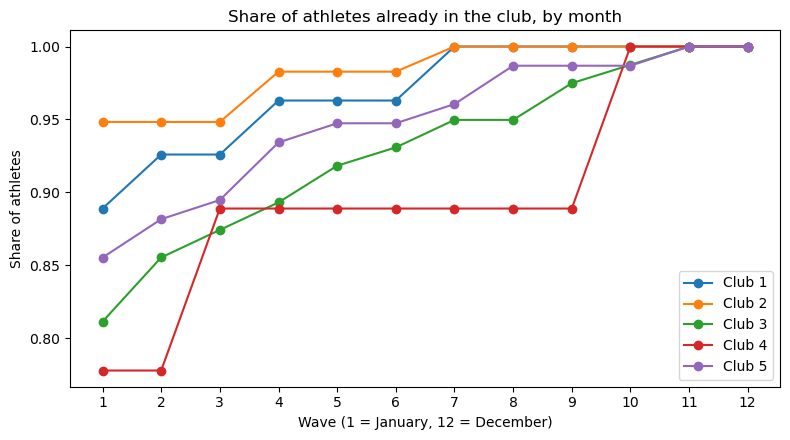

In [31]:
# Which variables contain missing values?
print("Missing values per variable:")
print(all_pan.isna().sum()[lambda s: s > 0].to_string())

# Structural missingness: NaN in run variables should coincide with in_club == False
consistency = (all_pan["in_club"] == all_pan["freq_run"].notna()).mean()
print(f"\nShare of rows where NaN <=> not yet in the club: {consistency:.3f}  (expected: 1.000)")

# Entry wave per athlete (one row per athlete)
print("\nAthletes by entry wave and club (1 = present from the start):")
print(pd.crosstab(athletes["club"], athletes["entry_wave"]))
print("\nShare of athletes entering after January, by club:")
print((athletes["entry_wave"] > 1).groupby(athletes["club"]).mean().round(3).to_string())

# Share of athletes active in each month
active = all_pan.groupby(["wave", "club"])["in_club"].sum().unstack()
share_active = active.div(all_pan.groupby("club")["node"].nunique(), axis=1)

fig, ax = plt.subplots(figsize=(8, 4.5))
for c in share_active.columns:
    ax.plot(share_active.index, share_active[c], marker="o",
            color=CLUB_COLORS[c], label=f"Club {c}")
ax.set_title("Share of athletes already in the club, by month")
ax.set_xlabel("Wave (1 = January, 12 = December)")
ax.set_ylabel("Share of athletes")
ax.set_xticks(range(1, 13))
ax.legend()
plt.tight_layout()
plt.show()

## 3.5 Distribution of key variables

             count  mean   std  min  25%  50%  75%   max
freq_run    3732.0  2.69  1.92  0.0  1.0  2.0  4.0   7.0
time_run    3732.0  2.69  2.00  0.0  1.0  2.0  4.0   9.0
freq_other  3732.0  1.19  1.69  0.0  0.0  1.0  2.0   7.0
time_other  3732.0  1.46  2.03  0.0  0.0  1.0  2.0   7.0
kudos_in    3732.0  5.10  6.72  0.0  0.0  2.0  7.0  34.0
kudos_out   3732.0  5.10  7.58  0.0  0.0  1.0  8.0  60.0

Mean by club:
      freq_run  time_run  freq_other  time_other  kudos_in  kudos_out
club                                                                 
1         2.32      2.51        0.99        1.40      2.73       2.73
2         3.03      3.10        1.62        2.15     11.05      11.05
3         2.27      2.23        1.14        1.27      2.00       2.00
4         1.71      1.94        0.98        2.38      2.23       2.23
5         3.52      3.43        1.05        1.24      7.92       7.92

Maximum of time_run by club:
club
1    7.0
2    7.0
3    7.0
4    5.0
5    9.0


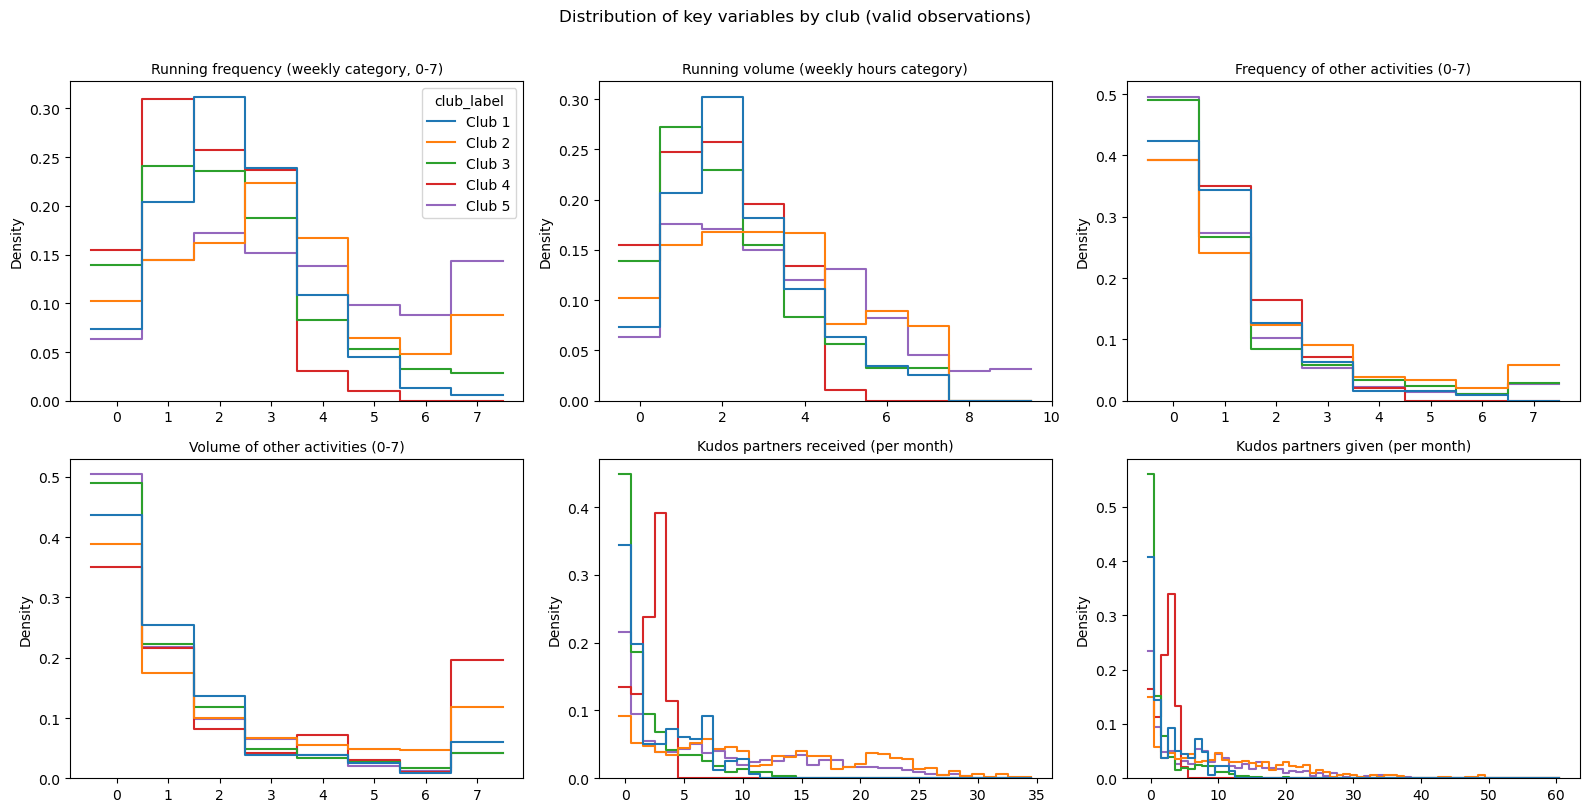

In [32]:
# Summary statistics on valid observations only
print(valid[key_vars].describe().round(2).T)
print("\nMean by club:")
print(valid.groupby("club")[key_vars].mean().round(2))

# Club 5 uses a different scale for running volume (0-9 instead of 0-7)
print("\nMaximum of time_run by club:")
print(valid.groupby("club")["time_run"].max().to_string())

titles = {
    "freq_run": "Running frequency (weekly category, 0-7)",
    "time_run": "Running volume (weekly hours category)",
    "freq_other": "Frequency of other activities (0-7)",
    "time_other": "Volume of other activities (0-7)",
    "kudos_in": "Kudos partners received (per month)",
    "kudos_out": "Kudos partners given (per month)"}

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, v in zip(axes.ravel(), key_vars):
    sns.histplot(data=valid, x=v, hue="club_label", palette=CLUB_PALETTE,
                 discrete=True, stat="density", common_norm=False,
                 element="step", fill=False, ax=ax)
    ax.set_title(titles[v], fontsize=10)
    ax.set_xlabel("")
    if ax is not axes[0, 0]:
        ax.get_legend().remove()
plt.suptitle("Distribution of key variables by club (valid observations)", y=1.01)
plt.tight_layout()
plt.show()

## 3.6 Temporal trends

Total kudos given vs received per wave:
wave           1       2       3       4       5       6       7       8       9       10      11      12
kudos_out  1437.0  1372.0  1424.0  1542.0  1646.0  1483.0  1451.0  1662.0  1785.0  1725.0  1707.0  1786.0
kudos_in   1437.0  1372.0  1424.0  1542.0  1646.0  1483.0  1451.0  1662.0  1785.0  1725.0  1707.0  1786.0


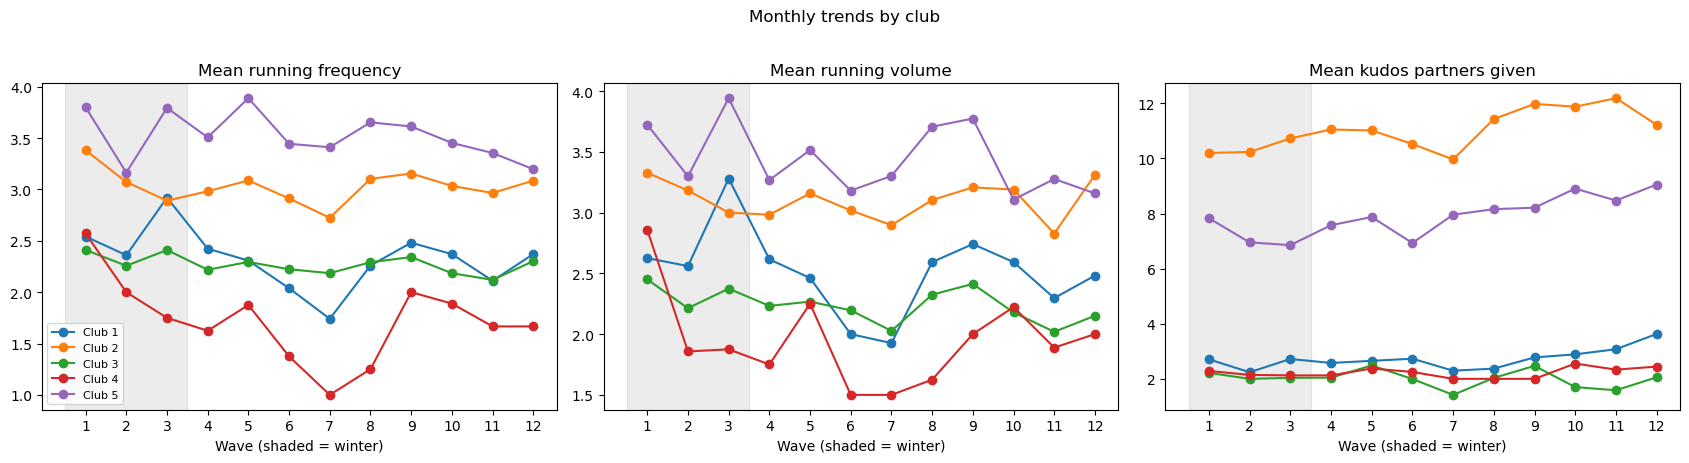

In [33]:
# Consistency check: in a closed network, total kudos given = total kudos received per month
print("Total kudos given vs received per wave:")
print(valid.groupby("wave")[["kudos_out", "kudos_in"]].sum().T)

trend_vars = {
    "freq_run": "Mean running frequency",
    "time_run": "Mean running volume",
    "kudos_out": "Mean kudos partners given"}

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), sharex=True)
for ax, (v, title) in zip(axes, trend_vars.items()):
    monthly = valid.groupby(["wave", "club"])[v].mean().unstack()
    for c in monthly.columns:
        ax.plot(monthly.index, monthly[c], marker="o",
                color=CLUB_COLORS[c], label=f"Club {c}")
    ax.axvspan(0.5, 3.5, color="grey", alpha=0.15)   # winter waves (1-3)
    ax.set_title(title)
    ax.set_xlabel("Wave (shaded = winter)")
    ax.set_xticks(range(1, 13))
axes[0].legend(fontsize=8)
plt.suptitle("Monthly trends by club", y=1.02)
plt.tight_layout()
plt.show()

## 3.7 Within-athlete variation

How much do athletes change from one month to the next? This matters for Part III: if athletes rarely change, there is little behaviour to explain.

freq_run: share of athlete-months with a change = 0.572
freq_run: share of variance between athletes (stable differences) = 0.741

time_run: share of athlete-months with a change = 0.574
time_run: share of variance between athletes (stable differences) = 0.705



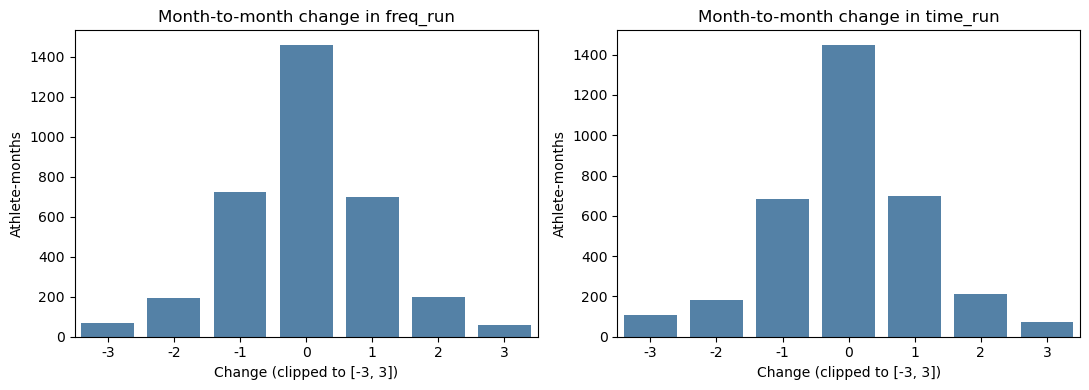

In [34]:
# How much do athletes actually change from one month to the next?
# This matters for any later analysis of diffusion (no change = nothing to explain)
panel = valid.sort_values(["club", "node", "wave"]).copy()

for v in ["freq_run", "time_run"]:
    panel["delta_" + v] = panel.groupby(["club", "node"])[v].diff()
    d = panel["delta_" + v].dropna()
    athlete_mean = panel.groupby(["club", "node"])[v].transform("mean")
    between_share = athlete_mean.var() / panel[v].var()
    print(f"{v}: share of athlete-months with a change = {(d != 0).mean():.3f}")
    print(f"{v}: share of variance between athletes (stable differences) = {between_share:.3f}\n")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, v in zip(axes, ["freq_run", "time_run"]):
    d = panel["delta_" + v].dropna().clip(-3, 3).astype(int)
    sns.countplot(x=d, color="steelblue", ax=ax)
    ax.set_title(f"Month-to-month change in {v}")
    ax.set_xlabel("Change (clipped to [-3, 3])")
    ax.set_ylabel("Athlete-months")
plt.tight_layout()
plt.show()

## 3.8 Athlete characteristics

Gender composition by club:
gender      F      M  Missing      O
club                                
1       0.296  0.593    0.000  0.111
2       0.207  0.724    0.017  0.052
3       0.264  0.704    0.000  0.031
4       0.222  0.667    0.000  0.111
5       0.224  0.671    0.000  0.105


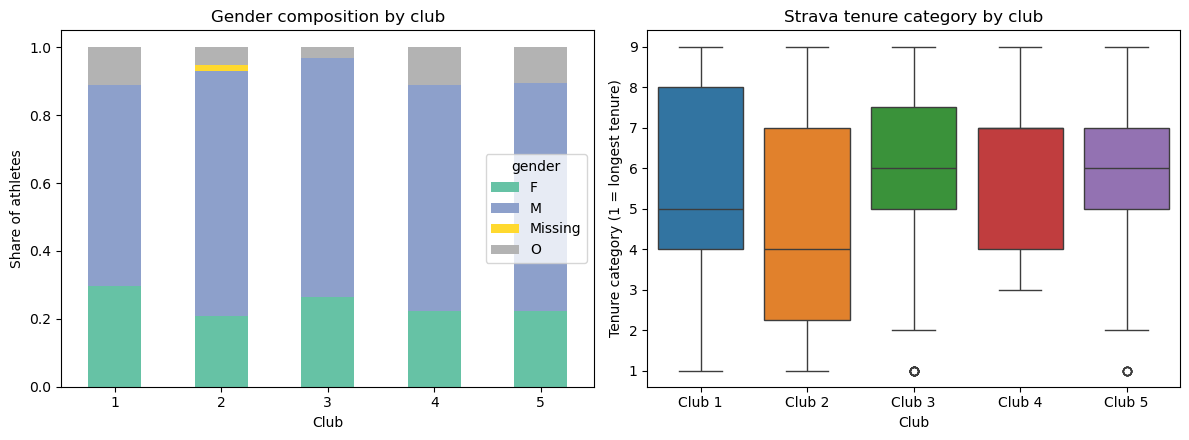

In [35]:
# Gender composition by club (one row per athlete)
gender_share = pd.crosstab(ath["club"], ath["gender"].fillna("Missing"), normalize="index")
print("Gender composition by club:")
print(gender_share.round(3))

# Text labels for clubs, so the colour palette keys match the plotted categories
ath_plot = ath.copy()
ath_plot["club_label"] = "Club " + ath_plot["club"].astype(str)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

gender_share.plot(kind="bar", stacked=True, ax=axes[0], colormap="Set2")
axes[0].set_title("Gender composition by club")
axes[0].set_xlabel("Club")
axes[0].set_ylabel("Share of athletes")
axes[0].tick_params(axis="x", rotation=0)

# NOTE: `novice` measures Strava tenure (1 = 2011 or earlier, 9 = 2019), NOT running experience
sns.boxplot(data=ath_plot, x="club_label", y="novice",
            hue="club_label", palette=CLUB_PALETTE, legend=False, ax=axes[1])
axes[1].set_title("Strava tenure category by club")
axes[1].set_xlabel("Club")
axes[1].set_ylabel("Tenure category (1 = longest tenure)")

plt.tight_layout()
plt.show()

## 3.9 Correlations between key variables

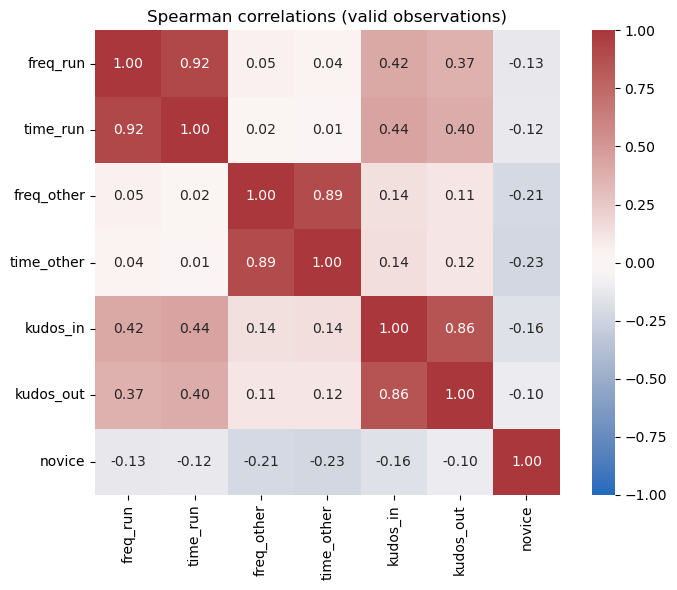

In [36]:
# Spearman correlation: the variables are ordinal categories or counts.
# Descriptive only: athlete-months from the same athlete are not independent.
corr = valid[key_vars + ["novice"]].corr(method="spearman")

plt.figure(figsize=(7.5, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0,
            vmin=-1, vmax=1, square=True)
plt.title("Spearman correlations (valid observations)")
plt.tight_layout()
plt.show()

## 3.10 Pairwise relationships between key variables

The diagonal shows the distribution of each variable by club, while the lower panels show
pairwise scatter plots of athlete-month observations where the athlete is already in the club.
Running frequency and volume are ordinal weekly categories and `novice` measures
Strava tenure (not running experience), so points fall on a grid and overlap heavily.
Club 5 uses a wider scale for running volume (0-9), which explains the higher values of
`time_run` for that club. This plot complements the Spearman correlations in section 3.9.

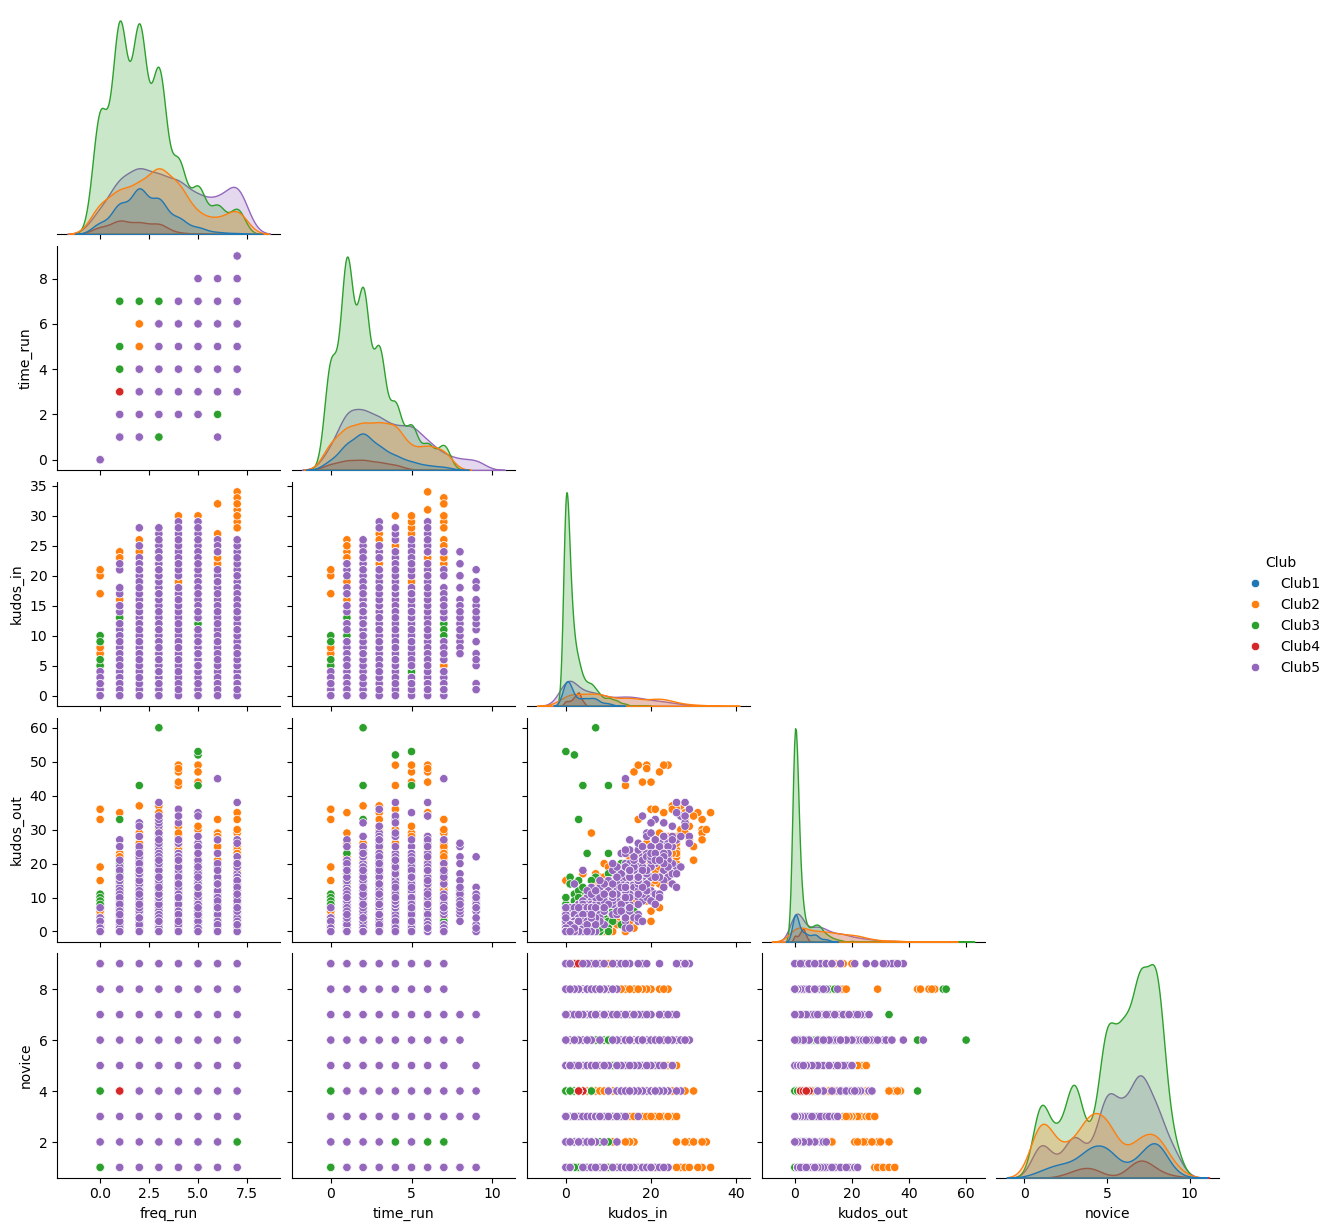

In [37]:
col = ["freq_run", "time_run", "kudos_in", "kudos_out", "novice"]
new_data = all_pan.loc[all_pan["in_club"], col + ["club"]].copy()
new_data["club"] = "Club" + new_data["club"].astype(int).astype(str)

p = sns.pairplot(new_data, vars=col, hue="club", palette="tab10", corner=True)
p.legend.set_title("Club")
plt.show()

# Part II: Social aggregation (network analysis)

# 4. The kudos network

## 4.1 Graph construction

For each club a **directed, weighted graph** is built with `networkx`: nodes are athletes, an arc A → B means that A gave at least one kudos to B in some month, and the arc weight is the **number of months** in which this happened (`weight`, 1 to 12). All club members are added as nodes, including those without any tie, and each node carries its attributes (`level`, `gender`, `novice`, `intensity`, `kudos_in_mean`, `kudos_out_mean`). The graphs are stored in the dictionary `graphs`, indexed by club.

### The three graphs used in the notebook

All graphs are built from the same kudos table (club × month). They differ in the time aggregation and in the symmetry of the tie, and each answers a different question: *who is recognised*, *where is there a real exchange*, and *which information is available at month t*. The names below are used consistently in the rest of the notebook.

| Graph | Direction | Time | Tie (edge) = | Used for |
|---|---|---|---|---|
| **Kudos graph** (`graphs`) | directed, weighted | whole year | A gave at least one kudos to B in some month; weight = number of months (1 to 12) | recognition and status (in-degree), ego network, degree distribution, annual reciprocity, homophily matrix |
| **Reciprocal graph** (`graphs_mut`) | undirected, weighted | whole year | A and B exchanged kudos **in the same month**; weight = number of such months | strong ties: network statistics, local bridges, embeddedness |
| **Monthly snapshot graphs** (`snapshots`) | one directed edge list per (club, month), made symmetric (`BIDIRECTIONAL = True`) | one graph per club and month (waves 1 to 11) | kudos given in that month | input of the GNN, with information only up to month *t* |

Some measures (transitivity, weakly connected components) ignore the direction of the kudos graph; this is stated where they are used. Descriptive labels computed on the whole year (commitment `level`, `status`) belong to Part II and **do not enter the predictive part**, which uses only information available at month *t* (cumulative versions of the same variables).

In [38]:
graphs = {}

for c in ath["club"].unique():
    e = edges_agg[edges_agg["club"] == c]                               # ties of this club
    g = nx.from_pandas_edgelist(e, "source", "target", edge_attr="weight",
                                create_using=nx.DiGraph())              # directed weighted graph
    a = ath[ath["club"] == c].set_index("node")                         # athletes of this club
    g.add_nodes_from(a.index)                                           # include isolated athletes
    nx.set_node_attributes(
        g, a[["level", "gender", "novice", "intensity",
              "kudos_in_mean", "kudos_out_mean"]].to_dict("index"))
    graphs[c] = g

total_nodes = 0
for c, g in graphs.items():
    print(f"Club {c}: nodes = {g.number_of_nodes():4d} | edges = {g.number_of_edges()}")
    total_nodes += g.number_of_nodes()
print(f"Total number of athletes in the panel: {total_nodes}")

Club 1: nodes =   27 | edges = 116
Club 2: nodes =   58 | edges = 1005
Club 3: nodes =  159 | edges = 913
Club 4: nodes =    9 | edges = 29
Club 5: nodes =   76 | edges = 1082
Total number of athletes in the panel: 329


## 4.2 Ego network of the most connected athlete

For each club, the athlete with the highest total degree (in-degree + out-degree in the annual kudos graph; a partner who both gave and received kudos counts twice) is identified as the **hub**. The figure shows the hub's ego network: the hub (red node) and the athletes it gave kudos to (blue nodes), together with all the kudos exchanged among those athletes. It is shown here for one club, and the same plot is produced for each club.

**How to read the figure**
- **Red node:** the hub of the club.
- **Blue nodes:** the hub's direct contacts. Node size and colour carry no information about commitment or status here.
- **Arrows:** kudos given, from the giver to the receiver. Arrows in both directions between two nodes indicate that kudos were exchanged.
- **Layout:** spring layout with a fixed seed, so the plot is reproducible. Distances have no direct meaning.

**What the figure shows**
- **The hub is not the centre of a star.** If the hub were the only link between its contacts, the plot would look like a star with no arrows among the blue nodes. Instead, the contacts are densely connected to each other, with many pairs of opposite arcs (kudos exchanged in both directions).
- **A cohesive group.** The hub belongs to a tightly knit group in which most members know and recognise one another. This corresponds to high closure (transitivity) and, for the hub's ties, high embeddedness: the hub and its contacts share many common partners.
- **A few peripheral contacts.** Some blue nodes have only one or two arrows. They are connected to the group through very few ties.

**Interpretation for the research question**
A highly connected athlete embedded in a dense group is well placed to **reinforce** a behaviour within that group, since the same contacts are exposed through several paths. Such a position is different from a **bridge**, which would connect separate groups and would appear as a hub whose contacts are not linked to each other. The local bridges and embeddedness analysis later in the notebook tests this difference systematically.

**Limitations**
- By default `nx.ego_graph` on a directed graph follows outgoing arcs only, so the figure includes the athletes the hub gave kudos to, but not those who only gave kudos to the hub.
- The hub is selected because it has the highest degree, so a dense neighbourhood is expected, especially in small clubs. The plot is a description of one athlete, not evidence about all hubs.
- Total degree mixes giving and receiving kudos, so the hub is not necessarily the athlete who receives the most recognition.
- Because of the year-long aggregation, the figure does not show whether the ties existed at the same time.

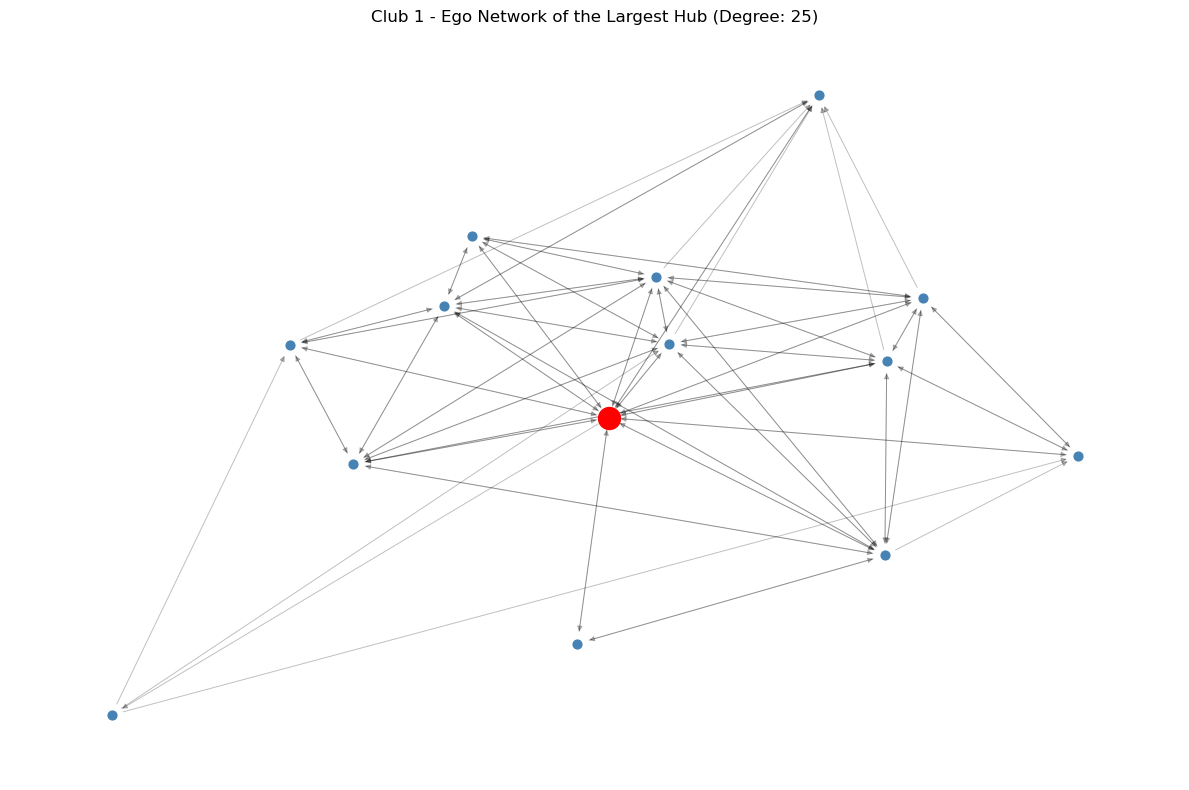

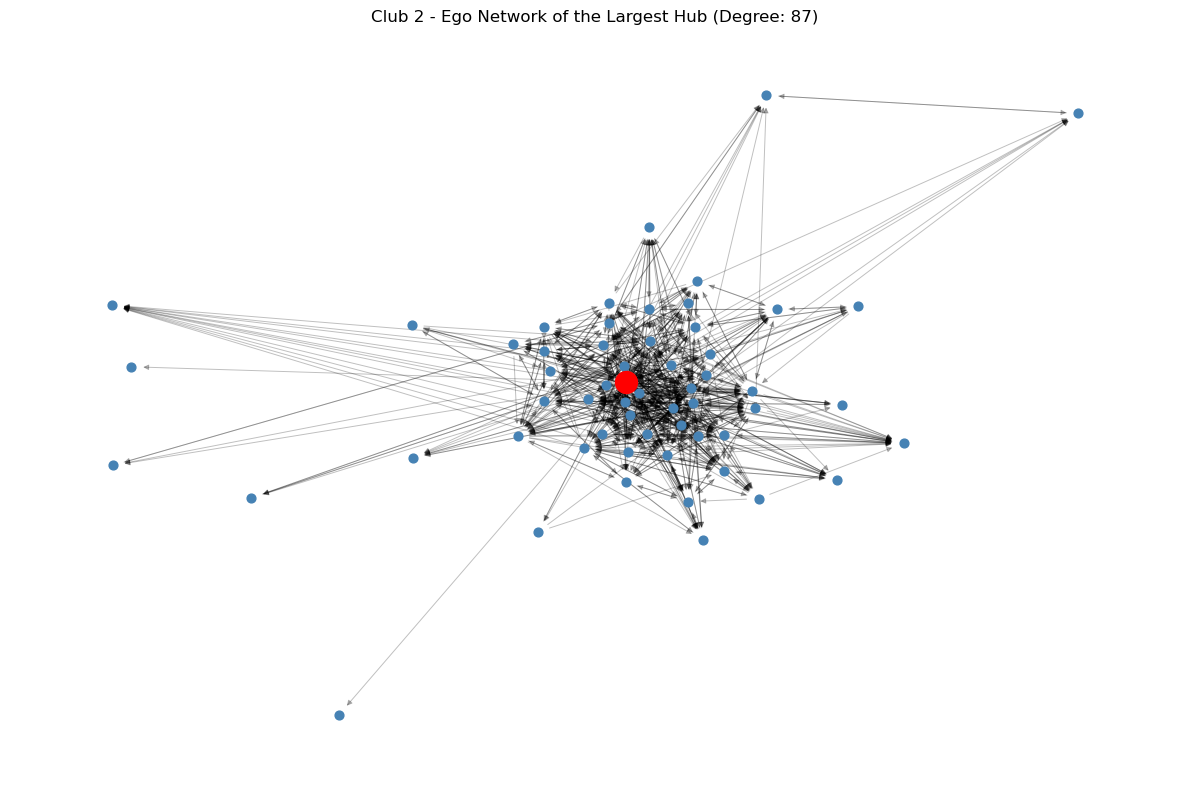

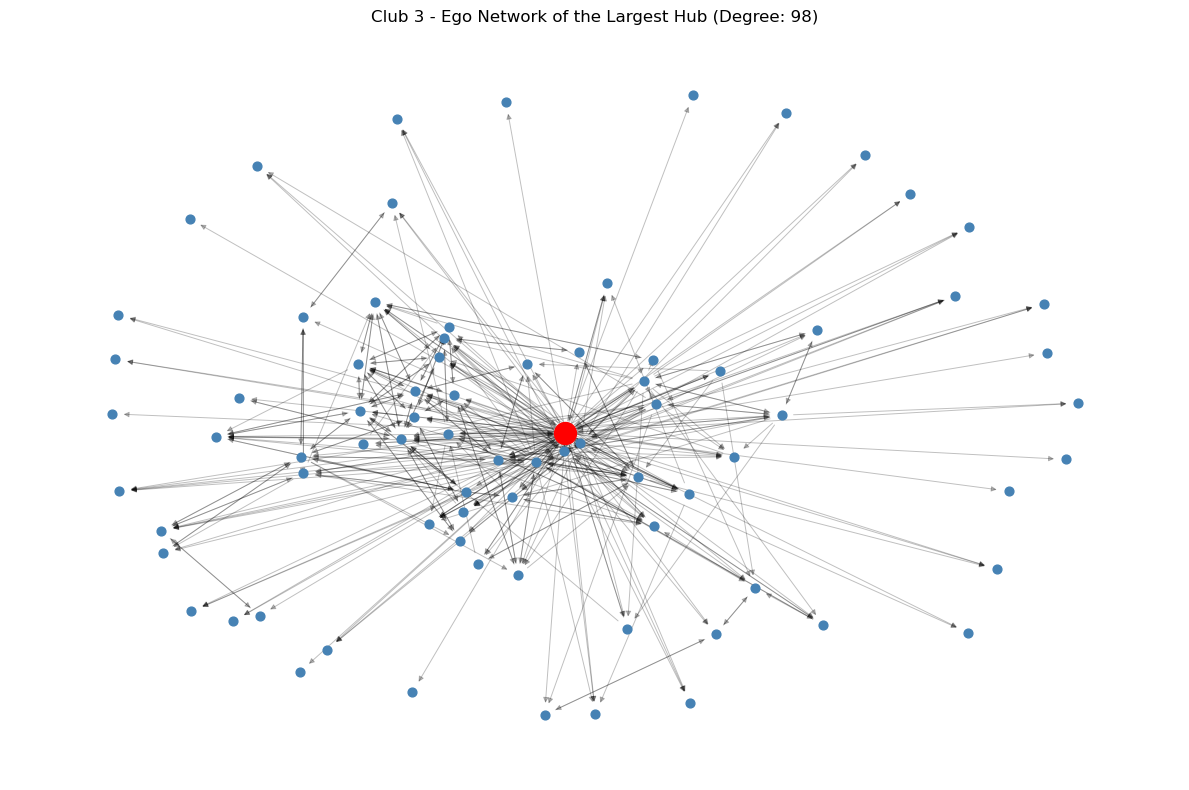

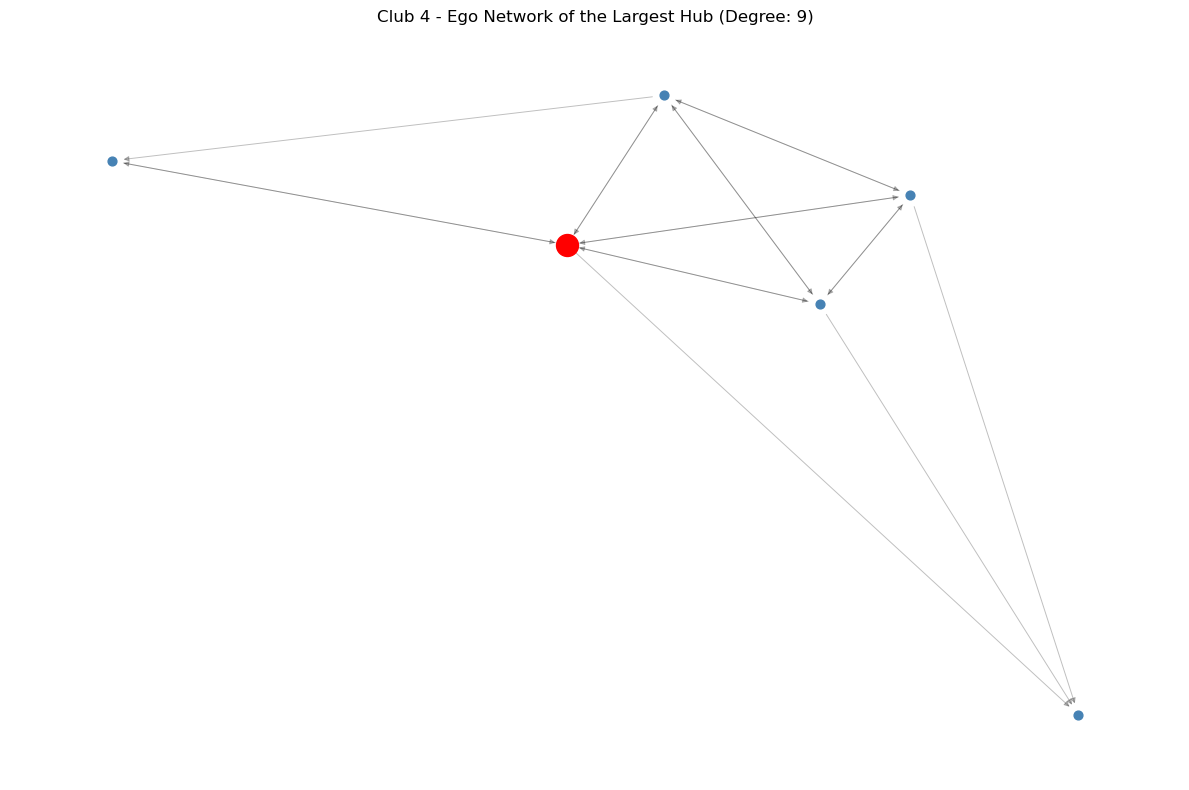

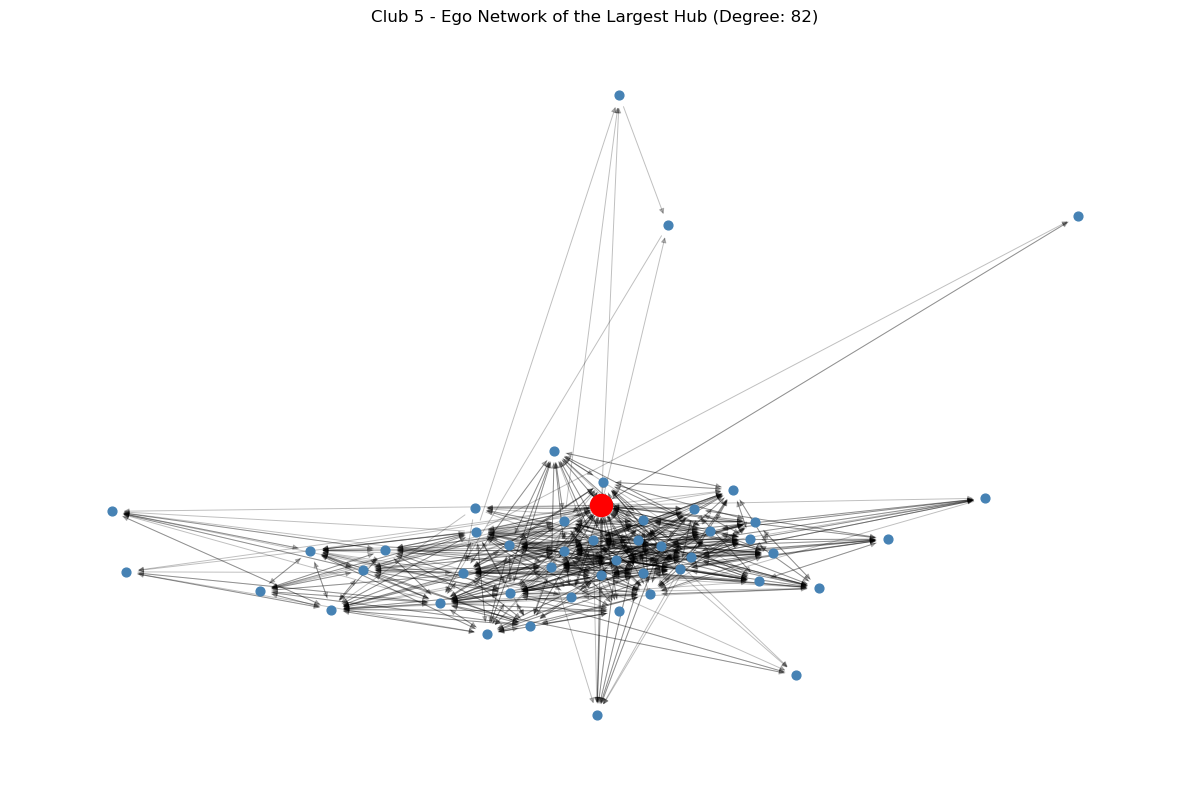

In [39]:
for c in ath["club"].unique():
    node_and_degree = graphs[c].degree()
    seed = 123

    largest_hub, degree = sorted(
        node_and_degree, key=itemgetter(1)
    )[-1]

    hub_ego = nx.ego_graph(graphs[c], largest_hub)

    plt.figure(figsize=(12, 8))

    pos = nx.spring_layout(
        hub_ego,
        seed=seed,
        k=1.5,
        iterations=100
    )

    nx.draw_networkx_edges(
        hub_ego, pos,
        alpha=0.25,
        width=0.7,
        arrows=True,
        arrowsize=8
    )

    nx.draw_networkx_nodes(
        hub_ego, pos,
        node_color="steelblue",
        node_size=40
    )

    nx.draw_networkx_nodes(
        hub_ego, pos,
        nodelist=[largest_hub],
        node_color="red",
        node_size=250
    )

    plt.title(
        f"Club {c} - Ego Network of the Largest Hub "
        f"(Degree: {degree})"
    )
    plt.axis("off")
    plt.tight_layout()
    plt.show()

Each ego network above is drawn with the same fixed seed (`seed = 123`), so the figures are reproducible.

## 4.3 Kudos network by club: commitment level and recognition

For each club, the directed kudos network aggregated over the year is drawn, so that commitment, recognition and the persistence of ties can be seen in the same picture. One figure is produced per club. An arrow from athlete A to athlete B means that A gave at least one kudos to B in some month.

**How to read the figures**

| Element | Encoding |
|---|---|
| Node colour | Commitment level: **red = high**, **blue = low**. Running volume and frequency are averaged over the year, standardised within the club, combined into one index and split at the club median. It measures how much an athlete runs, not skill or expertise. |
| Node size | Average number of distinct club members from whom the athlete received kudos in a month (`kudos_in_mean`). Larger nodes are more recognised athletes. The size is `60 + 150 × kudos_in_mean`, so an athlete who received no kudos still has a visible node. |
| Solid dark arrows | **Persistent ties**: kudos given in at least 3 different months. |
| Dashed light grey arrows | **Occasional ties**: kudos given in fewer than 3 months. |
| Labels | Athlete ID within the club. IDs are unique only inside a club, so the same number in two clubs refers to different people. |
| Layout | Spring layout with a fixed seed, so the figures are reproducible. Athletes who are strongly connected are pulled together. |

**What to look at**
- **Core-periphery structure.** Is there a dense core with a ring of weakly connected or isolated athletes around it?
- **Concentration of recognition.** Are there a few very large nodes, or is recognition spread evenly?
- **Persistence.** What share of the arrows is solid, and do solid arrows link core athletes with each other or core and periphery?
- **Commitment.** Do red and blue nodes mix in the core and in the periphery, or does one colour dominate a region of the plot?


**Results**

- **Club 3** (the largest, 159 athletes) shows a dense central core crowded with the most recognised athletes, surrounded by a wide outer ring of athletes with one or a few ties and a number of isolated athletes. A handful of large nodes concentrate recognition. Most arrows are **dashed** (occasional): the mean tie lasts only 3.9 months in Club 3, against 6.3 to 7.5 months in the other clubs (section 5).
- **Red and blue nodes are mixed** both in the core and in the periphery: commitment level does not visibly separate core from periphery. This is confirmed quantitatively by an assortativity coefficient close to zero in all clubs (section 5) and tested formally in section 6.
- The pattern is consistent with a **core-periphery structure**, but the visual impression is exploratory, and the figures of the small clubs (Club 4, 9 athletes; Club 1, 27 athletes) are not informative on their own.

**Limitations**
- **The layout is only a visual aid.** Distances have no direct meaning, and in large clubs the core is crowded: nodes and labels overlap and hide part of the structure.
- **Colour and size are judged by eye.** The figures are exploratory. Whether athletes with the same commitment connect more than expected by chance is tested separately in the stratified adjacency matrix section.
- **The 3-month threshold is a choice.** It separates persistent from occasional ties, and results should be checked with other values (for example 2 or 4 months).
- **Annual aggregation.** The network pools 12 months, so it does not show when ties formed or whether two athletes were active in the club at the same time.
- **Small clubs.** Club 4 (9 athletes) and Club 1 (27 athletes) are too small for any general conclusion.

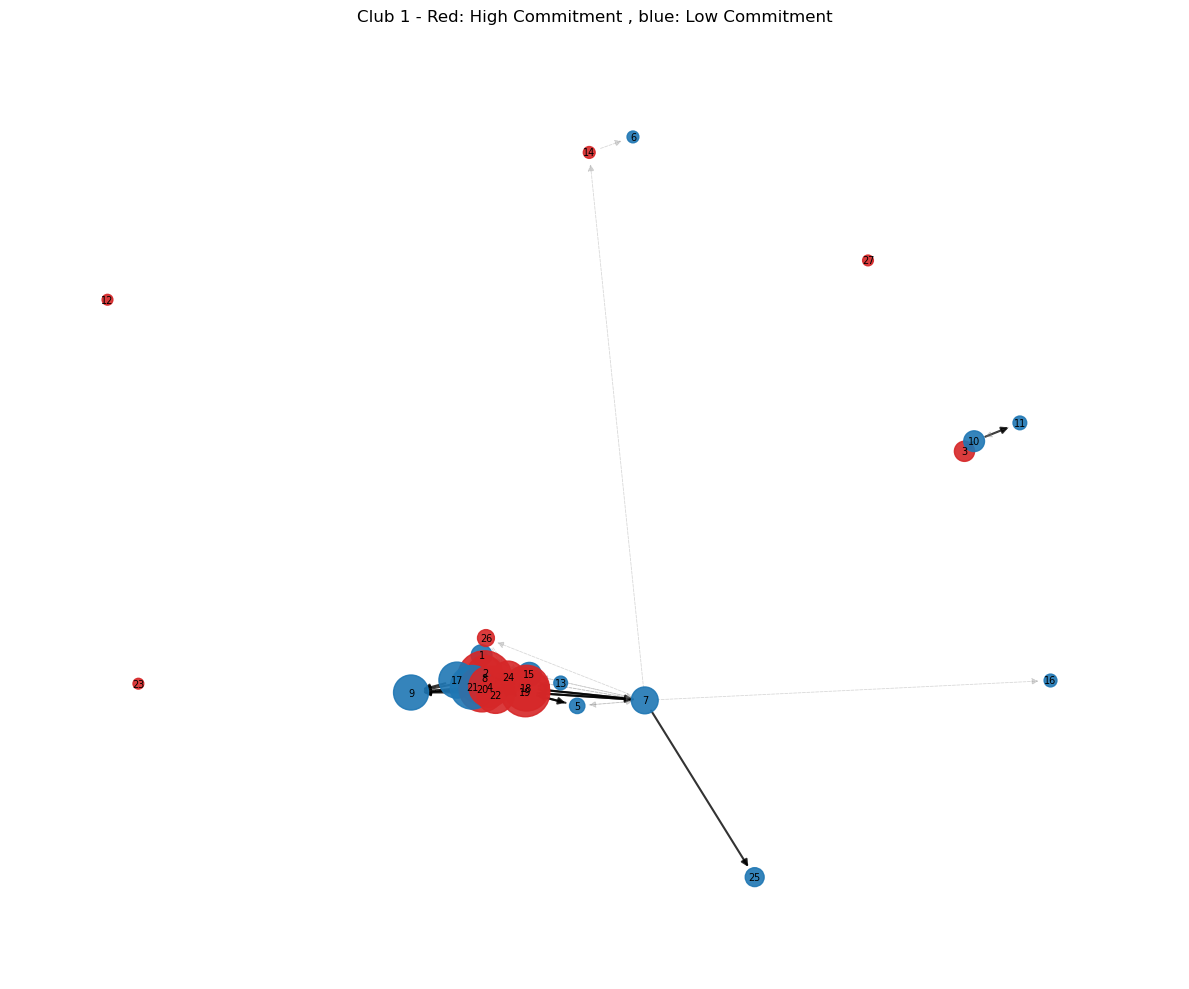

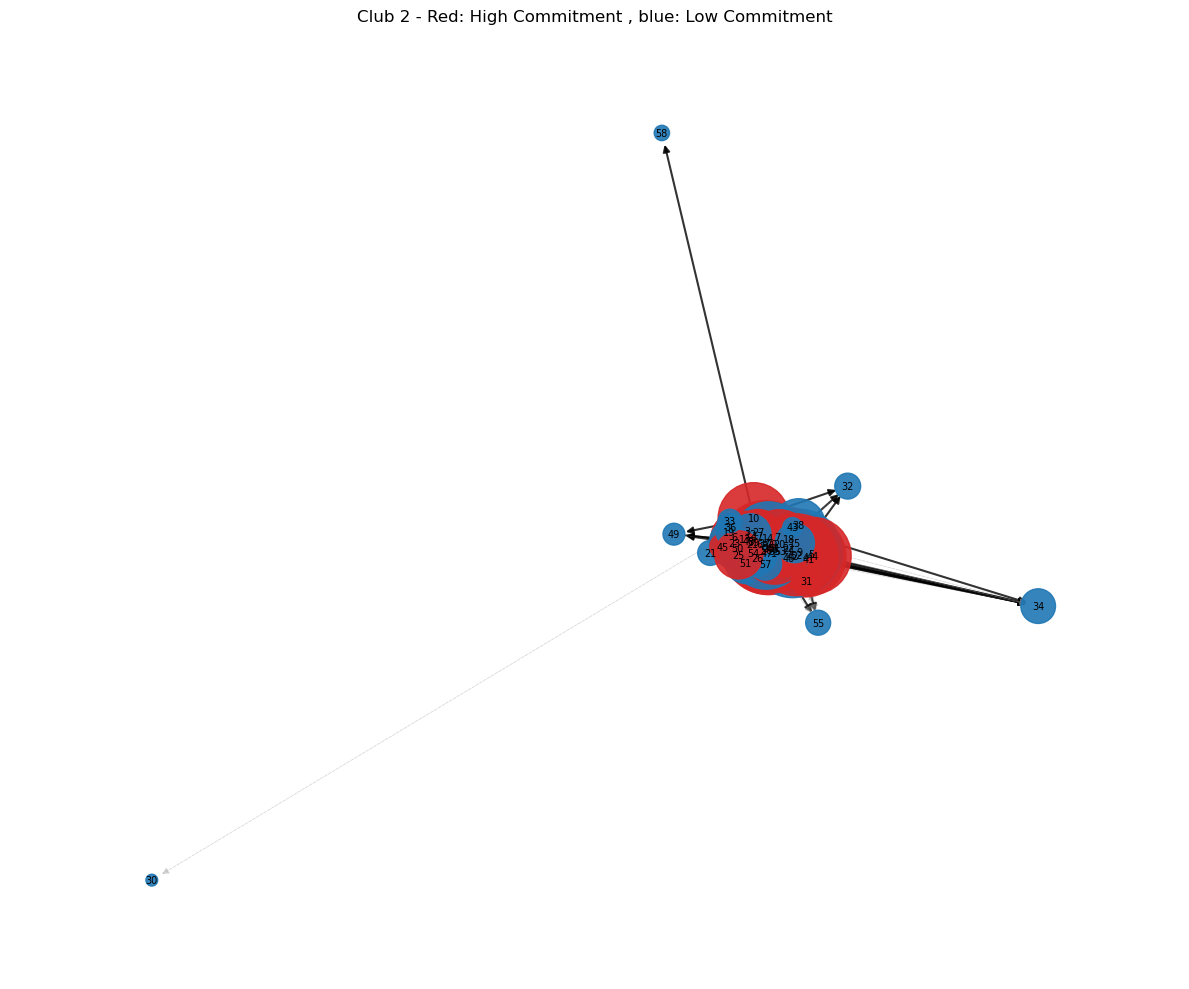

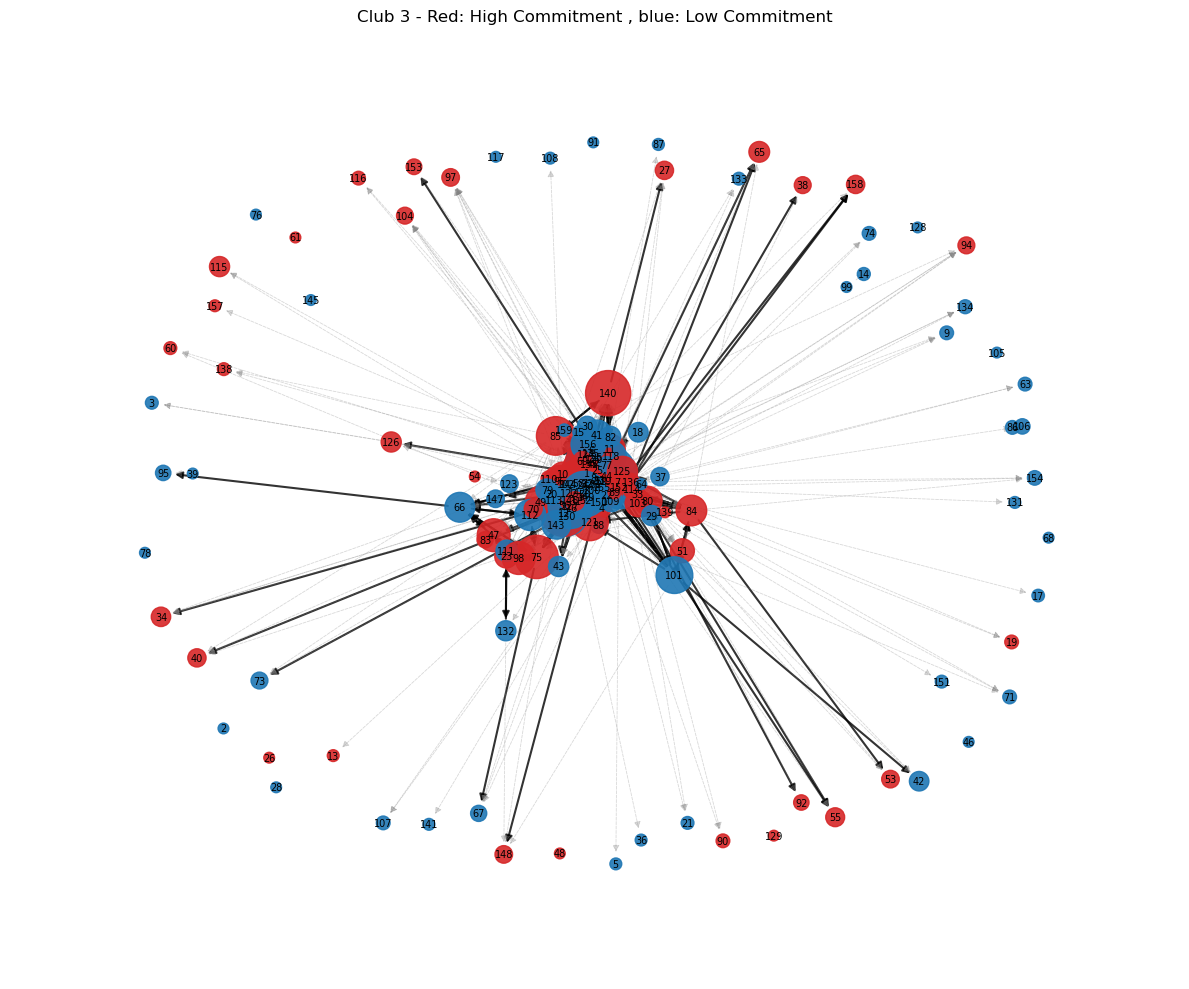

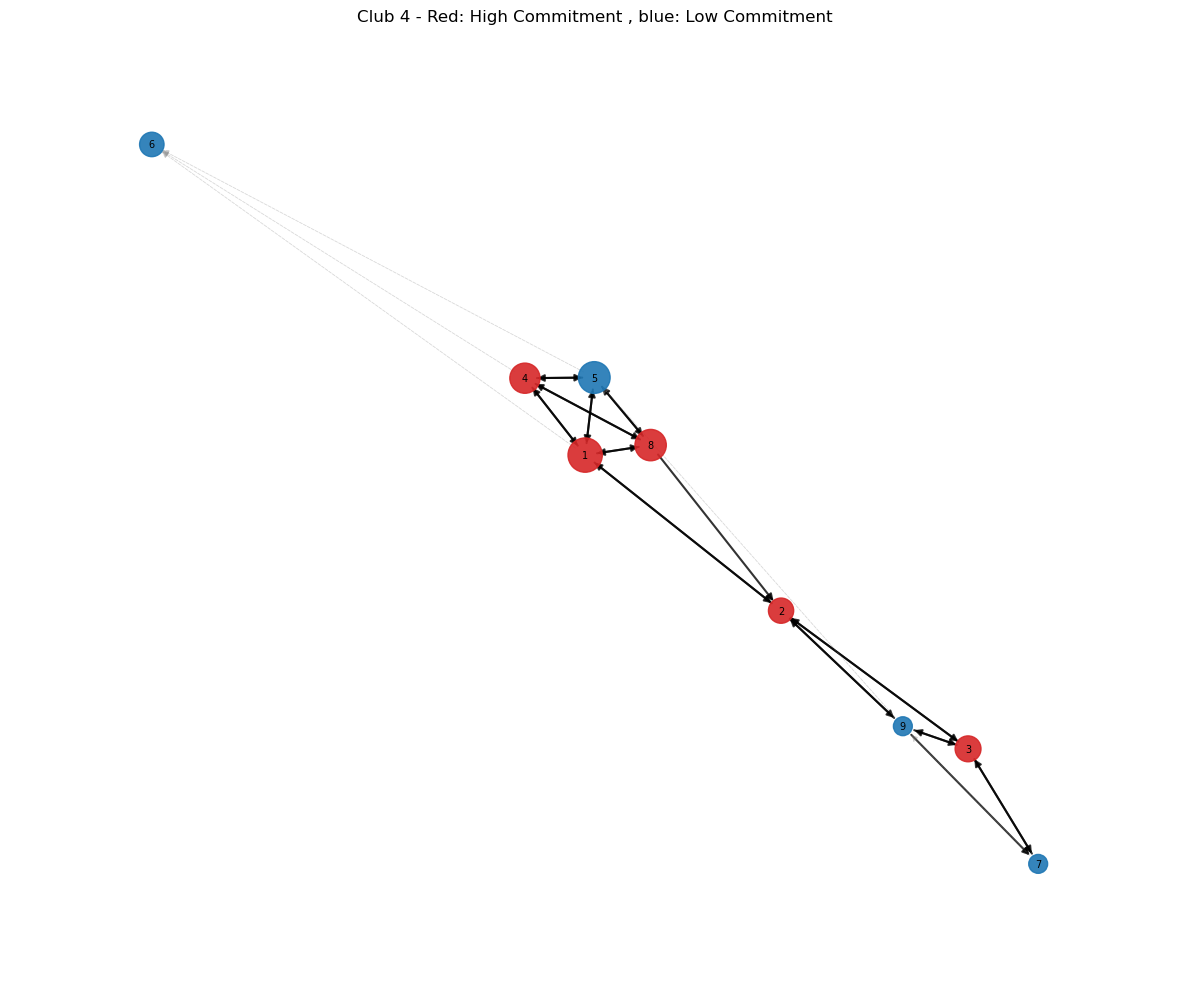

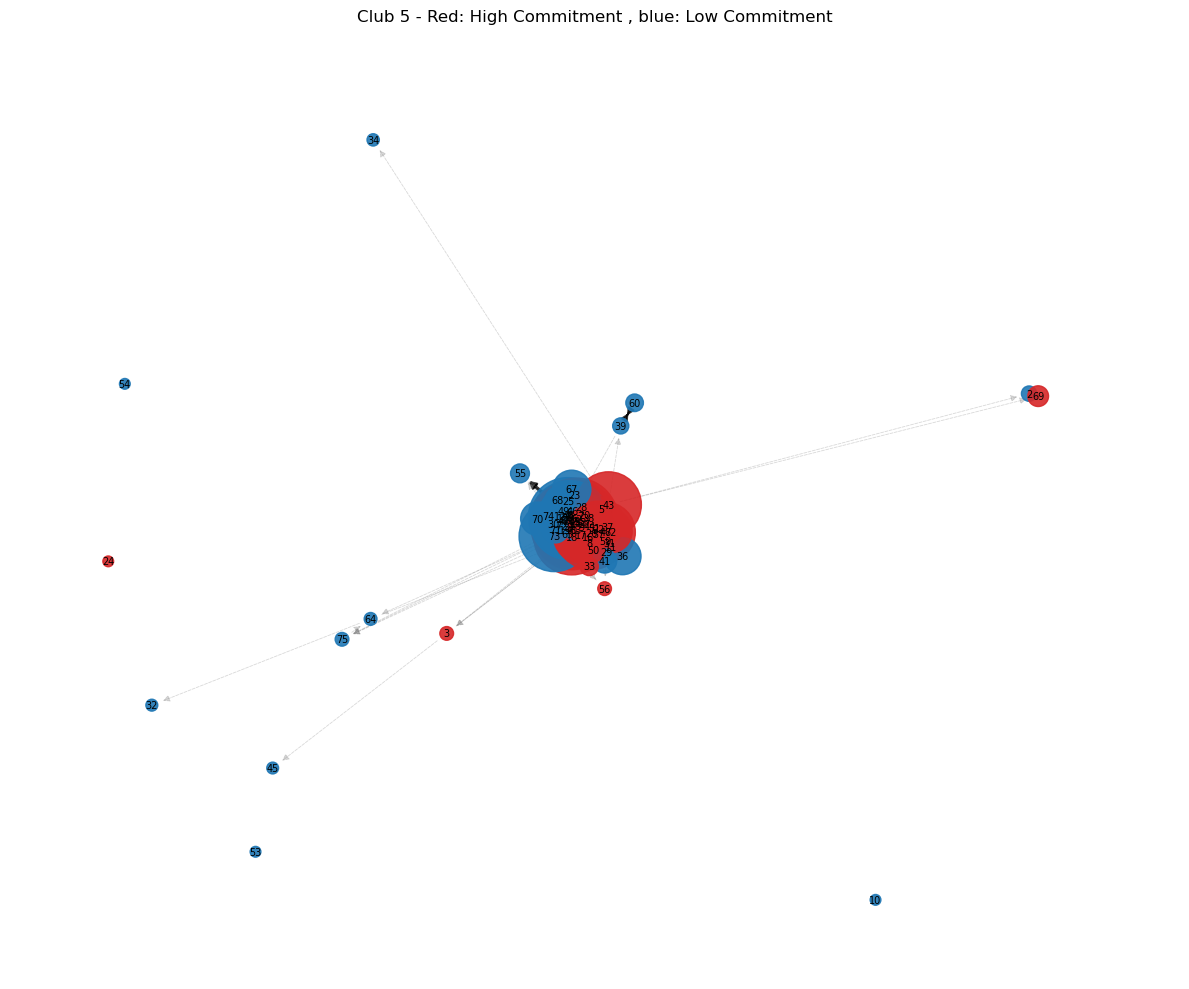

In [40]:
for c in sorted(ath["club"].unique()):
    G = graphs[c]
    pos = nx.spring_layout(G, seed=7)

    # Persistent Edges >= 3 monts 
    elarge = [(u, v) for (u, v, d) in G.edges(data=True) if d["weight"] >= 3]
    esmall = [(u, v) for (u, v, d) in G.edges(data=True) if d["weight"] < 3]

    #  Level of commitment for kudes obtained 
    colors = ["tab:red" if G.nodes[n]["level"] == "high" else "tab:blue" for n in G.nodes]
    sizes = [60 + 150 * G.nodes[n]["kudos_in_mean"] for n in G.nodes]

    plt.figure(figsize=(12, 10))

    # nodes
    nx.draw_networkx_nodes(G, pos, node_size=sizes, node_color=colors, alpha=0.9)

    # edges
    nx.draw_networkx_edges(G, pos, edgelist=elarge, width=1.5, alpha=0.8, arrows=True)
    nx.draw_networkx_edges(G, pos, edgelist=esmall, width=0.6, alpha=0.3,
                           edge_color="gray", style="dashed", arrows=True)

    # Nodes Label
    nx.draw_networkx_labels(G, pos, font_size=7, font_family="sans-serif")

    plt.title(f"Club {c} - Red: High Commitment , blue: Low Commitment")
    ax = plt.gca()
    ax.margins(0.1)
    plt.axis("off")
    plt.tight_layout()
    plt.show()

## 4.4 Degree distribution

Mean total degree (in + out; a partner with whom kudos are exchanged in both directions counts twice) per club, followed by the degree distribution of each club.

In [41]:
for c in graphs:
    mean_deg = 2 * graphs[c].number_of_edges() / graphs[c].number_of_nodes()
    print(f"Club {c}: mean total degree (in + out) = {mean_deg:.3f}")

Club 1: mean total degree (in + out) = 8.593
Club 2: mean total degree (in + out) = 34.655
Club 3: mean total degree (in + out) = 11.484
Club 4: mean total degree (in + out) = 6.444
Club 5: mean total degree (in + out) = 28.474


(Details of the degree analysis, with the example of Club 1. In the paper, the same plot is shown for Club 3.)

The kudos network of each club is a directed graph aggregated over the year: an arc from
athlete A to athlete B means that A gave at least one kudos to B in some month. The figure
below shows, for Club 1, the largest weakly connected component (top panel, direction
ignored) and three views of the degree distribution (bottom panels). Here the degree is the
total degree (in + out), i.e. the number of kudos ties (given plus received) of an athlete during the year; a reciprocated partner counts twice.

- **Degree rank plot.** Degrees are sorted from the highest to the lowest. The curve drops
  quickly: a small group of athletes has a very high degree (up to about 25 ties (in + out), in a
  club of 27 members), followed by a plateau at around 15-19, and a long tail of athletes
  with only a few ties. Three athletes have degree 0, so they are isolated from the kudos
  network.
- **Degree histogram.** It counts how many athletes have each degree. With only 27 athletes
  every bar contains 1 to 3 athletes, so the histogram is irregular and should be read as
  a general shape, not bar by bar.
- **P(k) distribution.** It is the histogram divided by the number of athletes, so it has the
  same shape on a probability scale (for example, 3 athletes out of 27 give P(k) = 0.11).
  Its purpose is to compare clubs of different size.

**Interpretation.** Participation is very unequal: a few highly connected athletes act as
hubs, while many members have few ties or none. This is a core-periphery structure, and it
is consistent with the idea that some athletes receive much more recognition than others.
In the network layout, most athletes are placed in one dense cluster and some peripheral
athletes are linked to the rest by a single arc.

**Limitations.**
- With 27 athletes the distributions are noisy and no formal fit (for example a power law)
  is justified.
- Degree counts kudos ties (in + out) over the whole year, so it does not distinguish a
  one-off kudos from a relationship that lasts several months.
- The layout is only a visual aid: distances in the plot have no direct meaning, and
  overlapping nodes in the dense cluster hide part of the structure.

The same plots for the other clubs follow below. Larger clubs show the same pattern with
more extreme hubs (for example, the highest total degree is about 98 in Club 3 and 87 in
Club 2).

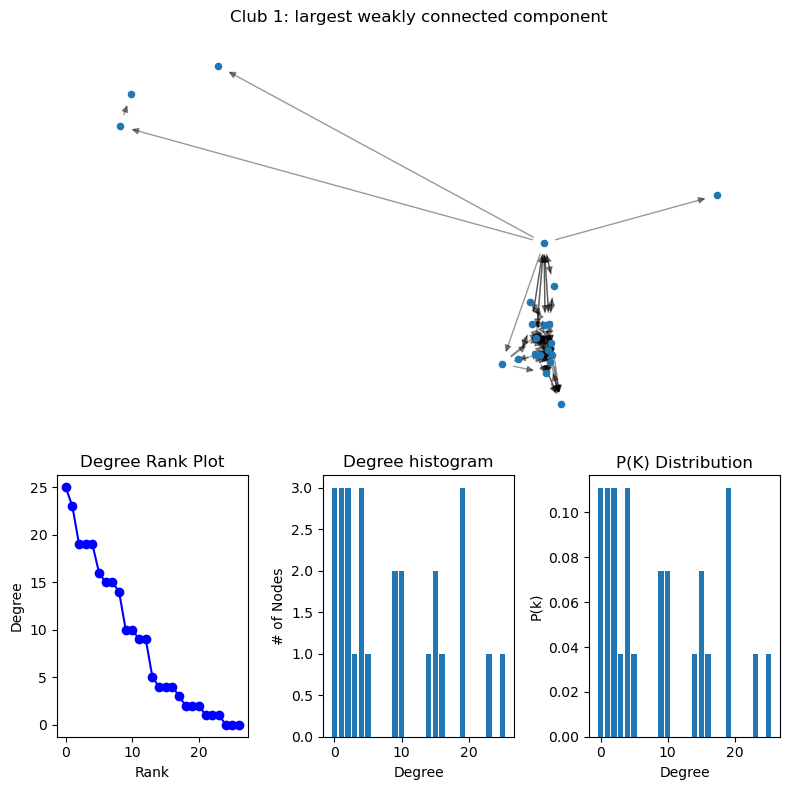

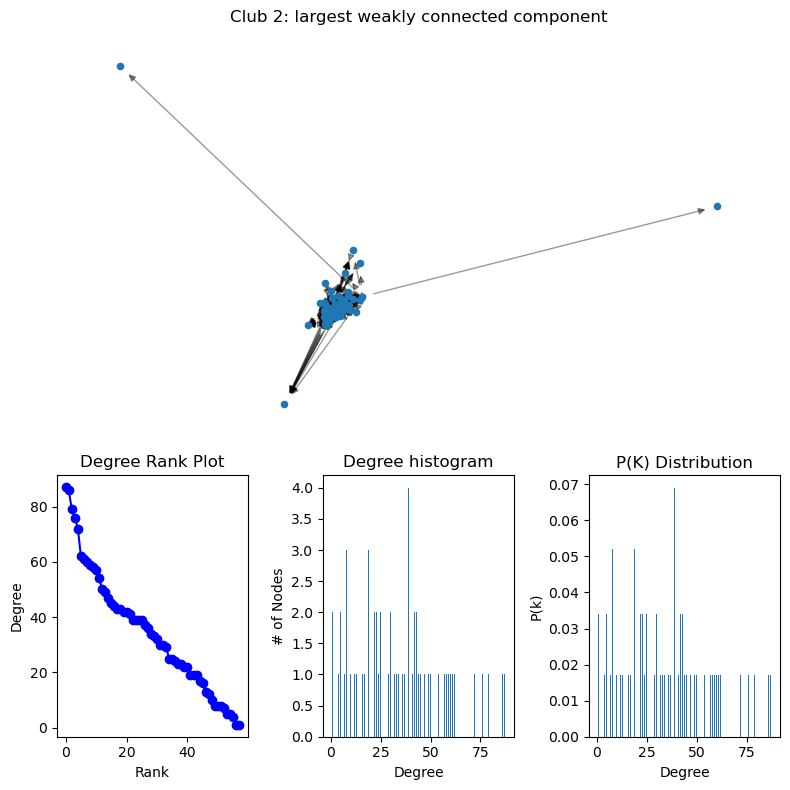

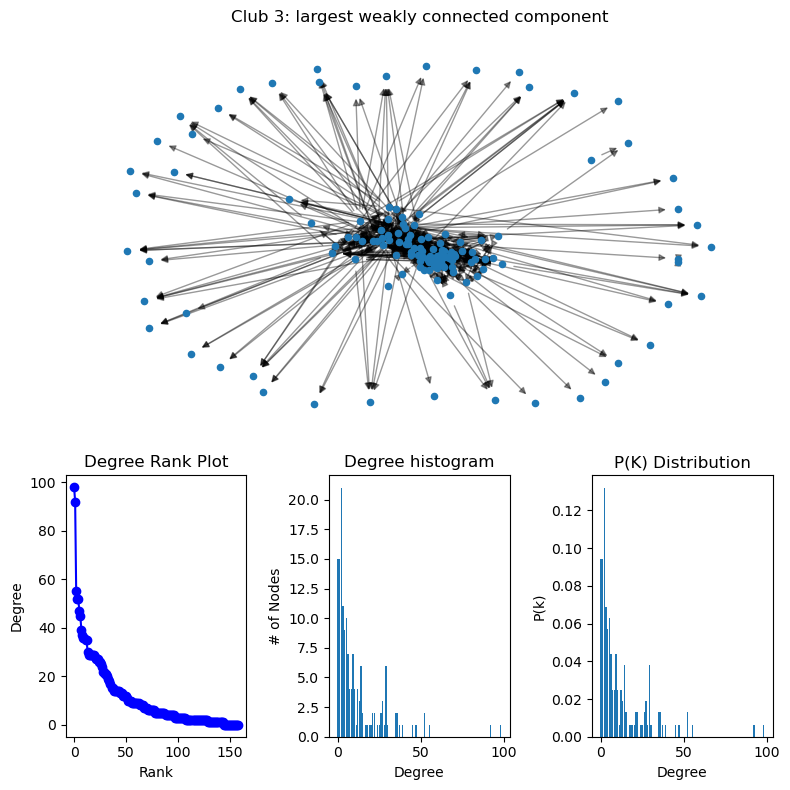

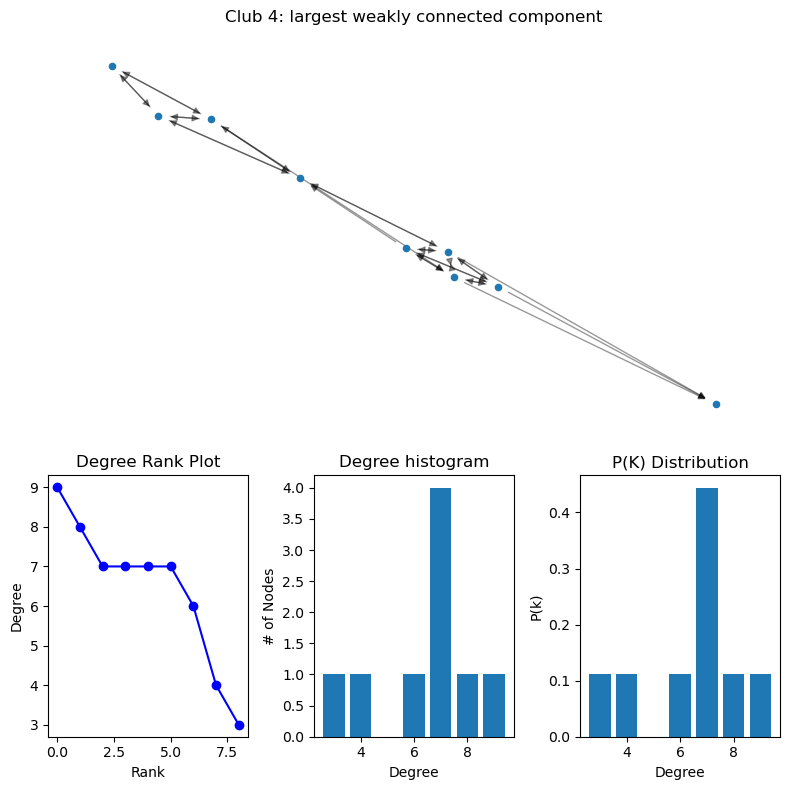

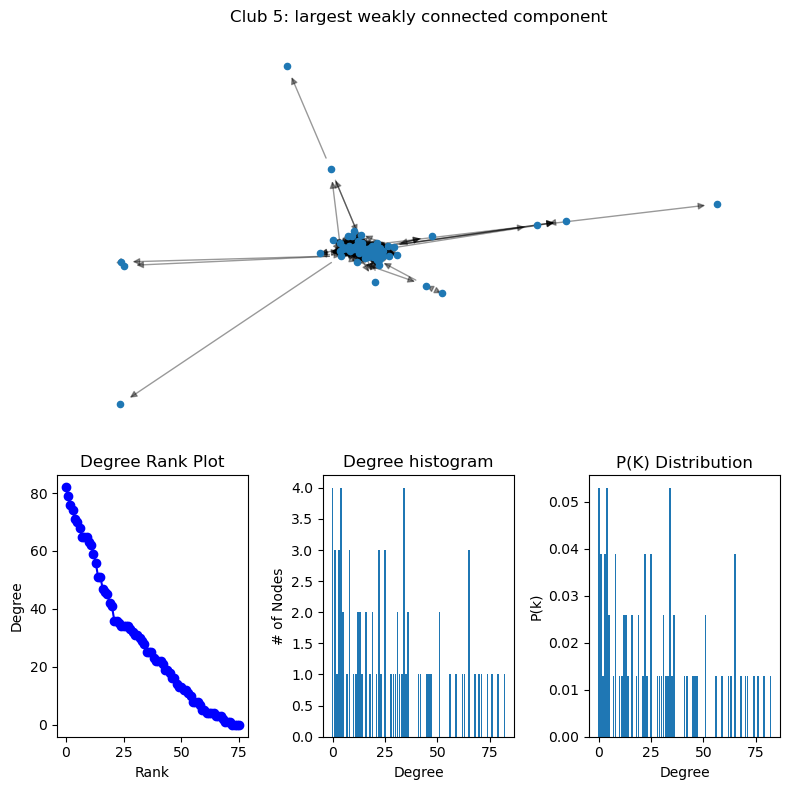

In [42]:
from collections import Counter

for c in ath["club"].unique():
    degree_sequence = sorted((d for n, d in graphs[c].degree()), reverse=True)
    count=Counter(degree_sequence)
    prob_K = {k: round(v / graphs[c].number_of_nodes(), 3) for k, v in count.items()}
    dmax = max(degree_sequence)

    fig = plt.figure(figsize=(8, 8))
# Create a gridspec for adding subplots of different sizes
    axgrid = fig.add_gridspec(5, 6)

    ax0 = fig.add_subplot(axgrid[0:3, :])
    Gcc = graphs[c].subgraph(sorted(nx.weakly_connected_components(graphs[c]), key=len, reverse=True)[0])
    pos = nx.spring_layout(Gcc, seed=10396953) # same layout seed for each Graphs 
    nx.draw_networkx_nodes(Gcc, pos, ax=ax0, node_size=20)
    nx.draw_networkx_edges(Gcc, pos, ax=ax0, alpha=0.4)
    ax0.set_title(f"Club {c}: largest weakly connected component")
    ax0.set_axis_off()

    ax1 = fig.add_subplot(axgrid[3:, :2])
    ax1.plot(degree_sequence, "b-", marker="o")
    ax1.set_title("Degree Rank Plot")
    ax1.set_ylabel("Degree")
    ax1.set_xlabel("Rank")

    ax2 = fig.add_subplot(axgrid[3:, 2:4])
    ax2.bar(*np.unique(degree_sequence, return_counts=True))
    ax2.set_title("Degree histogram")
    ax2.set_xlabel("Degree")
    ax2.set_ylabel("# of Nodes")

    ax3 = fig.add_subplot(axgrid[3:, 4:])
    gradi = sorted(prob_K)                        # sorted degrees (x axis)
    probabilita = [prob_K[k] for k in gradi]      # corresponding P(k) (y axis)
    ax3.bar(gradi, probabilita)
    ax3.set_title("P(K) Distribution")
    ax3.set_xlabel("Degree")
    ax3.set_ylabel("P(k)")

    fig.tight_layout()
    plt.show()

# 5. Network statistics by club

This section summarises the structure of each club with standard network measures. It answers the first half of the research question: *to what extent does Strava work as an infrastructure for social aggregation?* Two networks are compared for every club, because they describe different things:

- **Kudos network** (directed, aggregated over the year): an arc from A to B means that A gave at least one kudos to B in some month. It captures *recognition*, including one-way kudos.
- **Reciprocal network** (undirected): two athletes are linked only if they exchanged kudos **in the same month**. It is the operational definition of a *strong tie* used in this project.

Comparing the two shows how much of the visible activity turns into real exchange.

**Kudos network measures**

| Measure | What it tells us |
|---|---|
| Ties, density, mean degree | Size and fill of the network. Density is the share of possible directed ties that exist and falls mechanically as clubs grow, so mean degree (ties per athlete) is easier to compare across clubs. |
| Mean months per tie | Persistence of relationships. Values close to 1 mean mostly occasional kudos. |
| Reciprocity (annual) | Share of ties that are returned at some point in the year. It is looser than the monthly criterion. |
| Isolated athletes | Members who neither gave nor received any kudos. |
| Largest component (share) | Share of athletes connected, ignoring direction, to the main group. A low value means a fragmented club. |
| Transitivity | Probability that two contacts of an athlete are also connected to each other (closure). It is computed after ignoring the direction of the ties. |
| Assortativity by commitment level | Correlation between the commitment level of the two ends of a tie: positive = similar levels are connected, negative = mixing across levels, 0 = no pattern. |

**Reciprocal network measures**

| Measure | What it tells us |
|---|---|
| Ties, density, mean degree | Number and fill of strong ties. Mean degree is `2 × ties / athletes`. |
| Share of kudos ties inside a mutual pair | Share of all directed kudos ties that belong to a pair exchanging kudos in the same month. Each mutual pair accounts for two directed ties. |
| Isolated athletes, largest component | Part of the club that has no strong tie, and size of the main connected group of strong ties. |
| Transitivity, mean clustering | Closure among strong ties. High values mean tight groups, which links directly to the embeddedness analysis. |
| Mean path length, diameter | Distance between athletes inside the largest connected group of strong ties. Short paths mean that something spreading through strong ties could reach everyone quickly. |

Path length and diameter are computed on the largest component only, because they are undefined when the network is disconnected.


**Results**

1. **Size and density.** Clubs range from 9 to 159 athletes. Mean kudos degree (ties per athlete) is about 17 in Club 2 and 14 in Club 5, against 3 to 6 in Clubs 1, 3 and 4. Density falls with size (0.036 in Club 3, the largest).
2. **Reciprocation.** In four of the five clubs about 79% to 83% of kudos ties belong to a pair that exchanged kudos in the same month, and annual reciprocity is 0.82 to 0.85. **Club 3 differs**: only about 50% of ties belong to a mutual pair (annual reciprocity 0.56), and ties last on average 3.9 months against 6.3 to 7.5 elsewhere.
3. **Core-periphery.** Club 3 has 15 athletes without any kudos tie and **74 of 159 (47%) without any strong tie**; its largest strong-tie component contains only 52% of the athletes. In the other clubs the strong-tie component includes 59% (Club 1) to 93% (Club 2) of the athletes.
4. **Closure and distances.** Strong ties are highly clustered: transitivity of the reciprocal network is 0.54 to 0.72 in four clubs and 0.36 in Club 3. Paths are short (mean 1.7 to 2.0 steps) in all clubs except Club 3 (3.3 steps, diameter 8). In clubs 2, 4 and 5, anything spreading through strong ties could therefore reach most members in few steps.
5. **Commitment.** Assortativity by commitment level lies between -0.02 and 0.09: athletes do not strongly sort by how much they run.

Taken together, the clubs of 9 to 76 athletes behave like **cohesive, reciprocal communities**, whereas the large Club 3 behaves like a looser audience with a dense core and many weakly attached members. This answers the first half of the research question: Strava works as an infrastructure for social aggregation, but to a very different degree depending on the club.

**Limitations**
- **Club size.** Club 4 has 9 athletes and Club 1 has 27, so their statistics are unstable and should not be compared directly with Clubs 3 and 5.
- **Density depends on size.** It decreases as the number of athletes grows, so it should be read together with mean degree.
- **Annual aggregation.** The kudos network pools 12 months, so a tie may have existed in a different period from the ties around it. Closure measures such as transitivity are therefore likely to be overestimated.
- **Isolated athletes** lower the averages. Whenever a mean is reported, the share of isolated athletes and the size of the largest component should be read next to it.
- **Assortativity** can return `nan` when a commitment group is missing or the network is too small.
- **Descriptive only.** These measures describe the structure, but they do not say how behaviour spreads. The diffusion question requires the monthly data.

The reciprocal (strong-tie) network is constructed first: two athletes are linked if each gave kudos to the other **in the same month**, and the edge weight (`months_mutual`) counts the months in which this happened.

In [43]:
e = all_edges[["club", "wave", "source", "target"]].drop_duplicates()
rev = e.rename(columns={"source": "target", "target": "source"})
mutual = e.merge(rev, on=["club", "wave", "source", "target"])
mutual = mutual[mutual["source"] < mutual["target"]]          # each pair once

mut_agg = (mutual.groupby(["club", "source", "target"])
                 .size().rename("months_mutual").reset_index())

graphs_mut = {}
for c in sorted(ath["club"].unique()):
    G = nx.from_pandas_edgelist(mut_agg[mut_agg["club"] == c],
                                "source", "target", edge_attr="months_mutual",
                                create_using=nx.Graph())
    G.add_nodes_from(ath.loc[ath["club"] == c, "node"])        # include isolated athletes
    graphs_mut[c] = G

In [44]:
# ==========================================================
# Network statistics by club

# `graphs_mut` (undirected reciprocal ties, same month).
# ==========================================================
rows = []

for c in sorted(graphs):
    Gd = graphs[c]                 # directed kudos graph
    Gm = graphs_mut[c]             # undirected reciprocal graph
    n = Gd.number_of_nodes()

    # Largest connected components (kudos: weak, i.e. ignoring direction)
    wcc_kudos = max(nx.weakly_connected_components(Gd), key=len)
    cc_mutual = max(nx.connected_components(Gm), key=len)
    core_mutual = Gm.subgraph(cc_mutual)        # a view, not a copy

    rows.append({
        "Club": c,
        "Athletes": n,

        # ---------- Kudos network (directed, aggregated over the year) ----------
        "KUDOS | ties (directed)": Gd.number_of_edges(),
        "KUDOS | density": nx.density(Gd),
        "KUDOS | mean degree (in = out)": Gd.number_of_edges() / n,
        "KUDOS | mean months per tie": np.mean([d["weight"] for _, _, d in Gd.edges(data=True)]),
        "KUDOS | reciprocity (annual)": nx.reciprocity(Gd),
        "KUDOS | isolated athletes": nx.number_of_isolates(Gd),
        "KUDOS | largest component (share)": len(wcc_kudos) / n,
        "KUDOS | transitivity": nx.transitivity(Gd.to_undirected()),
        "KUDOS | assortativity by commitment level": nx.attribute_assortativity_coefficient(Gd, "level"),

        # ---------- Reciprocal network (undirected, same-month exchange) ----------
        "MUTUAL | ties": Gm.number_of_edges(),
        "MUTUAL | density": nx.density(Gm),
        "MUTUAL | mean degree": 2 * Gm.number_of_edges() / n,
        "MUTUAL | share of kudos ties inside a mutual pair": 2 * Gm.number_of_edges() / Gd.number_of_edges(),
        "MUTUAL | isolated athletes": nx.number_of_isolates(Gm),
        "MUTUAL | largest component (share)": len(cc_mutual) / n,
        "MUTUAL | transitivity": nx.transitivity(Gm),
        "MUTUAL | mean clustering": nx.average_clustering(Gm),
        "MUTUAL | mean path length (largest component)":
            nx.average_shortest_path_length(core_mutual) if len(cc_mutual) > 1 else np.nan,
        "MUTUAL | diameter (largest component)":
            nx.diameter(core_mutual) if len(cc_mutual) > 1 else np.nan,
    })

# One column per club, one row per statistic
net_stats = pd.DataFrame(rows).set_index("Club").T
del rows                                        # temporary list, no longer needed

print(net_stats.round(3).to_string())

Club                                                     1         2        3       4         5
Athletes                                            27.000    58.000  159.000   9.000    76.000
KUDOS | ties (directed)                            116.000  1005.000  913.000  29.000  1082.000
KUDOS | density                                      0.165     0.304    0.036   0.403     0.190
KUDOS | mean degree (in = out)                       4.296    17.328    5.742   3.222    14.237
KUDOS | mean months per tie                          7.379     7.517    3.876   7.448     6.335
KUDOS | reciprocity (annual)                         0.845     0.816    0.556   0.828     0.826
KUDOS | isolated athletes                            3.000     0.000   15.000   0.000     4.000
KUDOS | largest component (share)                    0.778     1.000    0.893   1.000     0.947
KUDOS | transitivity                                 0.562     0.580    0.230   0.588     0.540
KUDOS | assortativity by commitment leve

# 6. Homophily: adjacency matrix stratified by commitment level

The previous heatmaps ordered athletes by ID, which carries no meaning. Here the weighted adjacency matrix of each club is **reordered by commitment level** to check whether athletes exchange kudos mainly with athletes who have a similar level of commitment (homophily), or across levels.

**Matrix construction**
- **Rows and columns:** athletes of one club. Rows are the sources (athletes who give kudos) and columns are the targets (athletes who receive kudos).
- **Cell value:** number of months (0-12) in which the source gave at least one kudos to the target. The colour scale is fixed to 0-12 in all clubs, so colours are comparable.
- **Order:** high-commitment athletes first, then low-commitment athletes. Inside each group, athletes are sorted by the kudos they receive (weighted in-degree), so the most recognised athletes are placed in the top-left corner of each block.
- **Red lines** separate the two groups and define four blocks: high → high, high → low, low → high and low → low.
- **Commitment level** is defined in the athlete table: running volume and frequency are averaged over the year, standardised within the club, combined into one index and split at the club median. It measures how much an athlete runs, not skill or expertise.

**Quantitative measures**

A visual impression is not enough to claim that groups are separated, so two measures are computed on the binary network (a tie exists or not):

1. **Density within groups vs. between groups.** Density is the share of possible ties that exist. *Within* counts ties between athletes of the same group, *between* counts ties across the two groups. The **difference** (within − between) is positive when athletes tend to connect with similar athletes.
2. **Assortativity coefficient (Newman).** Correlation between the commitment level of the source and the target of a tie. It ranges from −1 (ties only across levels) to +1 (ties only within levels), and 0 means no pattern.

**Permutation test**

To check whether the observed values could arise by chance, the high/low labels are shuffled randomly among the athletes of the same club 5,000 times in the full run (`N_PERM`). The network is kept fixed, so only the assignment of athletes to groups changes. For each shuffle both measures are recomputed, and the p-value is the share of shuffles that produce a value at least as extreme as the observed one (two-sided, with the +1 correction, so it can never be exactly zero).

**How to read the results**
- Difference and assortativity close to 0 with a high p-value: commitment does not organise the exchange of kudos.
- Positive values with a low p-value: homophily, so athletes with similar commitment recognise each other more than expected by chance. This would point to groups with similar behaviour.
- Negative values with a low p-value: kudos flow preferentially across levels.


**Results**

The table printed by the next cell reports, for each club, the density of ties within groups and between groups, their difference, the assortativity coefficient and the permutation p-values (reference run, 5,000 shuffles).

- Within-group density is **higher than between-group density in all five clubs** (differences between 0.009 and 0.119), but the difference is statistically distinguishable from chance only in Clubs 2, 3 and 5 (p = 0.013, 0.001, 0.001); in Clubs 1 and 4 (27 and 9 athletes) the tests have little power (p = 0.243 and 0.377).
- The assortativity coefficient is positive and significant only in **Club 5** (0.094, p = 0.003); elsewhere it is close to zero.
- The pattern is therefore **consistent but weak**: athletes with similar commitment recognise each other slightly more than expected by chance, but commitment does not organise the network.

**Limitations**
- **Small clubs.** Club 4 has 9 athletes and Club 1 has 27, so the tests have little power and the results should not be over-interpreted.
- **Isolated athletes** (almost half of Club 3) are counted in the possible ties, which lowers all densities. Differences between groups are therefore more reliable than absolute values.
- **Binary measures.** The tests ignore how many months a tie lasted, while the colours of the heatmap show it.
- **Ties are not independent**, because they share the same athletes. The permutation test takes this into account by keeping the network fixed.
- **The group split is a choice.** Splitting at the median discards information. Terciles or a continuous measure of commitment would be a useful robustness check.
- **Association, not diffusion.** Homophily can come from athletes choosing similar partners (selection) or from athletes becoming similar through contact (influence). The annual network cannot separate the two, which requires the monthly data.

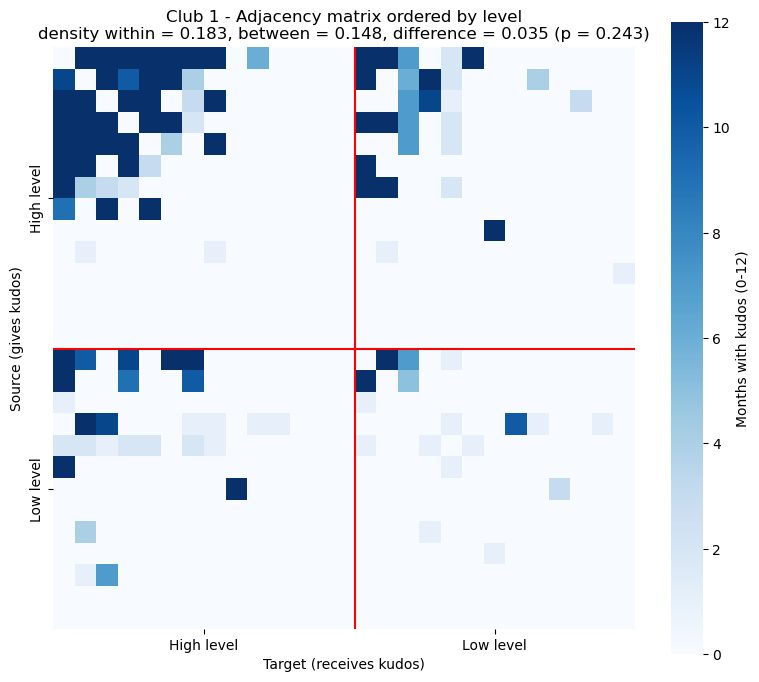

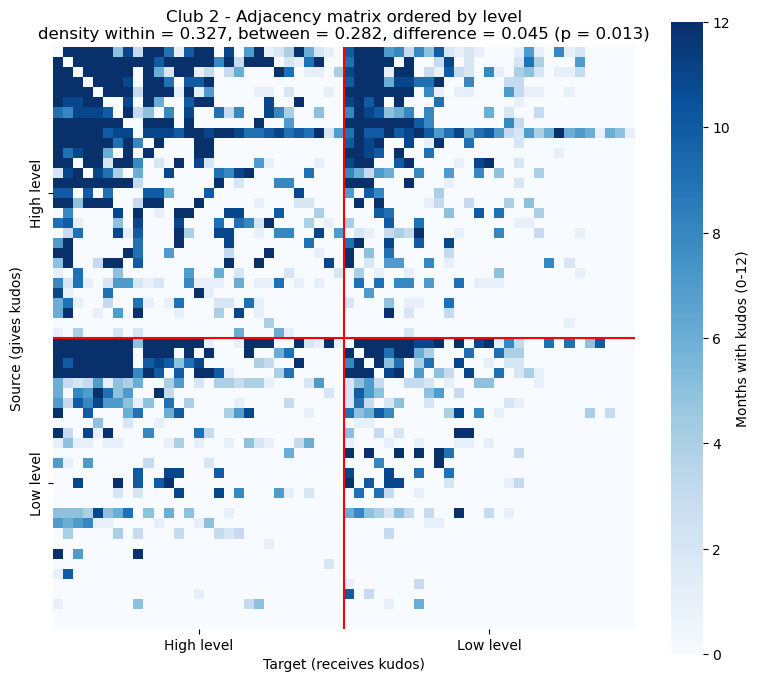

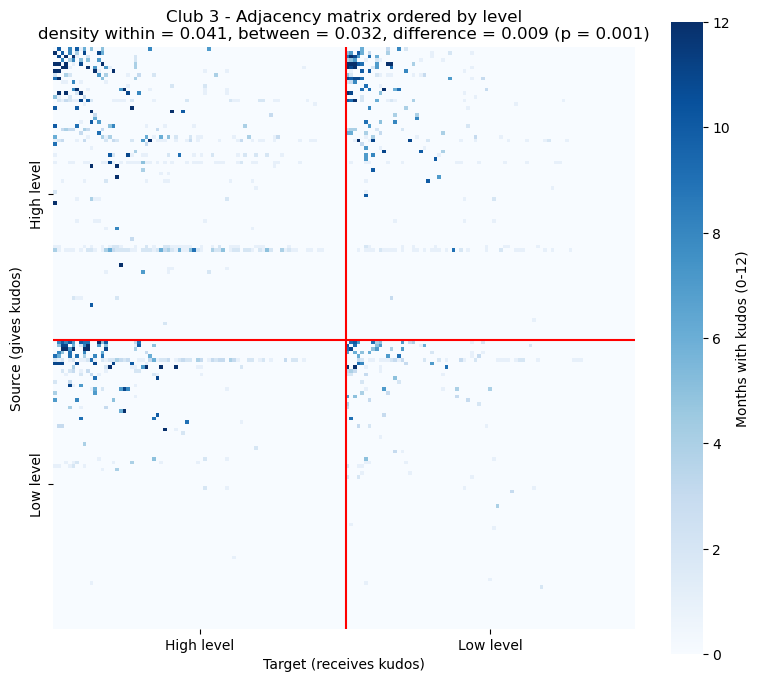

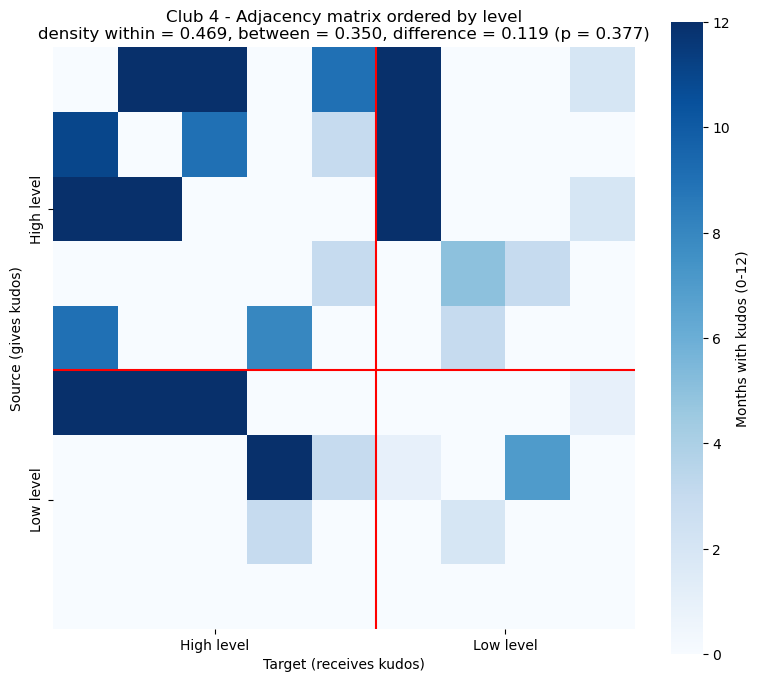

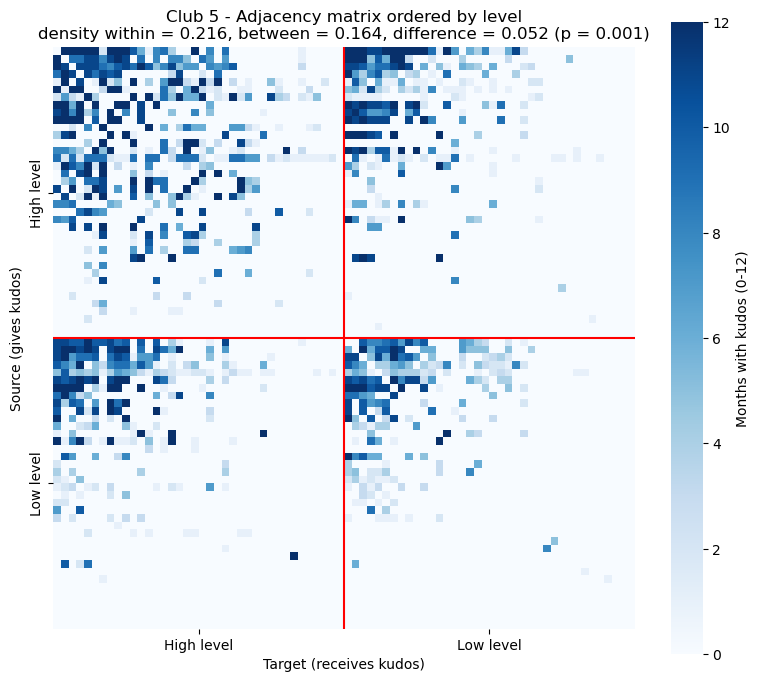

Homophily by level (permutation test, 5000 shuffles within each club)
      Athletes  High  Density within  Density between  Difference  p (difference)  Assortativity  p (assortativity)
Club                                                                                                               
1           27    14           0.183            0.148       0.035           0.243          0.011              0.929
2           58    29           0.327            0.282       0.045           0.013          0.004              0.915
3          159    80           0.041            0.032       0.009           0.001          0.048              0.212
4            9     5           0.469            0.350       0.119           0.377         -0.020              0.994
5           76    38           0.216            0.164       0.052           0.001          0.094              0.003


In [45]:
# ==========================================================
# Adjacency matrix stratified by group + homophily test

# ==========================================================
GROUP = "level"        # "level" = commitment (recommended); "status" = in-degree above club median
rng = np.random.default_rng(7)
res = []               # temporary list, deleted at the end

for c in sorted(graphs):
    G = graphs[c]

    # --- Group of each athlete (True = high) ---
    if GROUP == "level":
        lab = {n: G.nodes[n]["level"] == "high" for n in G.nodes}
    else:
        indeg = dict(G.in_degree())
        med = np.median(list(indeg.values()))
        lab = {n: indeg[n] > med for n in G.nodes}

    # --- Order: high group first; inside each group, most recognised athletes first ---
    order = sorted(G.nodes, key=lambda n: (not lab[n], -G.in_degree(n, weight="weight")))
    g = np.array([lab[n] for n in order], dtype=int)      # 1 = high, same order as the matrix
    N, n_high = len(order), int(g.sum())

    if n_high < 2 or N - n_high < 2:
        print(f"Club {c}: a group has fewer than 2 athletes, skipped")
        continue

    A = nx.to_numpy_array(G, nodelist=order, weight="weight")   # rows = source, columns = target
    src, tgt = np.nonzero(A)                                    # every kudos tie (binary)

    # --- Test statistics on binary ties ---
    def stats(lbl):
        same = lbl[src] == lbl[tgt]
        n1 = lbl.sum()
        n0 = N - n1
        d_within = same.sum() / (n1 * (n1 - 1) + n0 * (n0 - 1))   # ties inside groups / possible
        d_between = (~same).sum() / (2 * n1 * n0)                 # ties between groups / possible
        e = np.bincount(lbl[src] * 2 + lbl[tgt], minlength=4).reshape(2, 2) / len(src)
        ab = (e.sum(1) * e.sum(0)).sum()
        r = (np.trace(e) - ab) / (1 - ab) if ab < 1 else np.nan   # Newman's assortativity
        return d_within, d_between, d_within - d_between, r

    obs = stats(g)

    # --- Permutation test: shuffle group labels among athletes of the same club ---
    perm = np.array([stats(rng.permutation(g)) for _ in range(N_PERM)])
    p_diff = (np.sum(np.abs(perm[:, 2]) >= abs(obs[2])) + 1) / (N_PERM + 1)
    p_r = (np.sum(np.abs(perm[:, 3]) >= abs(obs[3])) + 1) / (N_PERM + 1)

    res.append({"Club": c, "Athletes": N, "High": n_high,
                "Density within": obs[0], "Density between": obs[1],
                "Difference": obs[2], "p (difference)": p_diff,
                "Assortativity": obs[3], "p (assortativity)": p_r})

    # --- Heatmap ---
    fig, ax = plt.subplots(figsize=(8, 7))
    sns.heatmap(A, cmap="Blues", vmin=0, vmax=12, square=True,
                xticklabels=False, yticklabels=False,
                cbar_kws={"label": "Months with kudos (0-12)"}, ax=ax)
    ax.axhline(n_high, color="red", lw=1.5)
    ax.axvline(n_high, color="red", lw=1.5)

    ticks = [n_high / 2, n_high + (N - n_high) / 2]
    names = [f"High {GROUP}", f"Low {GROUP}"]
    ax.set_xticks(ticks)
    ax.set_xticklabels(names)
    ax.set_yticks(ticks)
    ax.set_yticklabels(names, rotation=90, va="center")
    ax.set_xlabel("Target (receives kudos)")
    ax.set_ylabel("Source (gives kudos)")
    ax.set_title(f"Club {c} - Adjacency matrix ordered by {GROUP}\n"
                 f"density within = {obs[0]:.3f}, between = {obs[1]:.3f}, "
                 f"difference = {obs[2]:.3f} (p = {p_diff:.3f})")
    plt.tight_layout()
    plt.show()

homophily_tbl = pd.DataFrame(res).set_index("Club")
del res
print(f"Homophily by {GROUP} (permutation test, {N_PERM} shuffles within each club)")
print(homophily_tbl.round(3).to_string())

# 7. Brokerage and embeddedness of strong ties

The second half of the research question concerns **higher-status athletes** and the contacts they share activities with. Two structural positions matter for the spread of a behaviour:

- A **local bridge** is a strong tie whose two ends have **no common contact**. It connects otherwise separate parts of the club and is the typical channel through which something *new* reaches a group.
- **Embeddedness** is the number of common contacts of the two ends of a tie. The standardised **overlap** is `common / (deg(u) - 1 + deg(v) - 1 - common)`. Highly embedded ties sit inside dense groups, where the same contacts expose an athlete through several paths and behaviours are *reinforced*.

Both measures are computed on the **reciprocal network** (strong ties), and athletes are compared along two dimensions: **status** (in-degree in the annual kudos network above the club median) and **commitment level**.

## 7.1 Local bridges

SUMMARY PER CLUB
 club  nodes  Edges  isolated node  local_bridges  bridges_ratio
    1     27     48              9              2          0.042
    2     58    399              4              5          0.013
    3    159    227             74             44          0.194
    4      9     12              1              1          0.083
    5     76    436             10              5          0.011

SHARE OF LOCAL BRIDGES PER ATHLETE (average), by level of commitment
level   high    low
club               
1      0.123  0.222
2      0.042  0.095
3      0.429  0.419
4      0.117  0.000
5      0.083  0.139

SHARE OF LOCAL BRIDGES PER ATHLETE (average), by status
status   high    low
club                
1       0.009  0.600
2       0.001  0.123
3       0.274  0.885
4       0.194  0.000
5       0.003  0.241


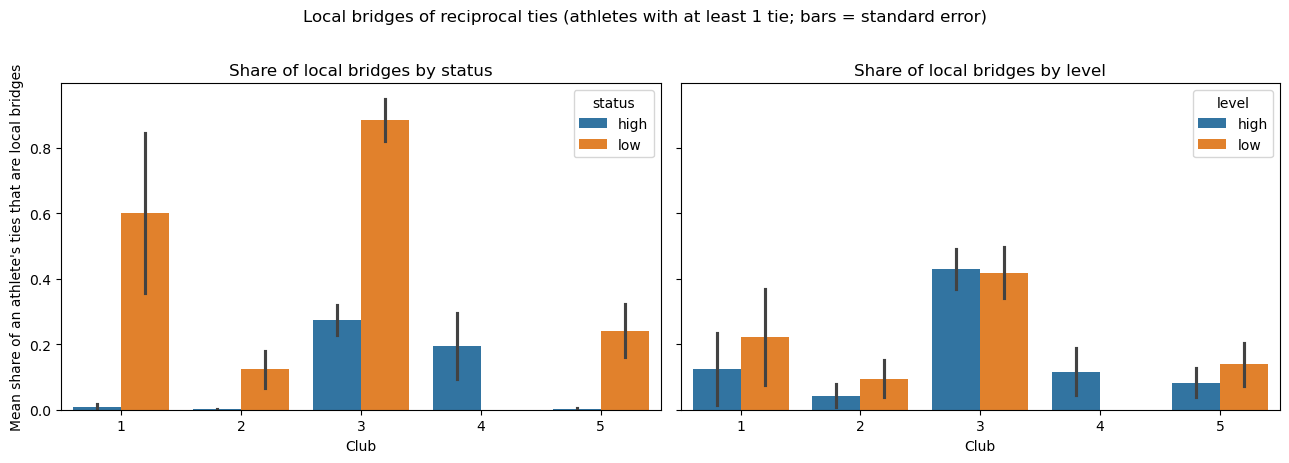

In [46]:
edge_rows, node_rows, club_rows = [], [], []

for c, G in graphs_mut.items():
    # span: Distance between u and v if the edge is removed (inf = true bridge)
    span = {frozenset((u, v)): s for u, v, s in nx.local_bridges(G, with_span=True)}# U and V they are the athlets that there are connected.

    for u, v, d in G.edges(data=True):
        common = len(list(nx.common_neighbors(G, u, v)))        # embeddedness
        denom = (G.degree(u) - 1) + (G.degree(v) - 1) - common

        edge_rows.append({
            "club": c, "u": u, "v": v,
            "months_mutual": d["months_mutual"],
            "embeddedness": common,                              # n. common Contact 
            "overlap": common / denom if denom > 0 else 0.0,     # standardized overlap
            "local_bridge": frozenset((u, v)) in span,
            "span": span.get(frozenset((u, v)), 2)})             # 2 = edge under a triangle # Span the shortest path if the edge is removed.

    for n in G.nodes:
        deg = G.degree(n)
        nb = len([nbr for nbr in G[n] if frozenset((n, nbr)) in span])
        node_rows.append({
            "club": c, "node": n, "degree": deg,
            "n_bridges": nb,
            "bridge_share": nb / deg if deg > 0 else np.nan,
            "in_deg": graphs[c].in_degree(n)})                  # Direct graph status 

    club_rows.append({
        "club": c, "nodes": G.number_of_nodes(), "Edges": G.number_of_edges(),
        "isolated node": nx.number_of_isolates(G),
        "local_bridges": len(span),
        "bridges_ratio": len(span) / G.number_of_edges() if G.number_of_edges() else np.nan})

edges_lb = pd.DataFrame(edge_rows)
nodes_lb = pd.DataFrame(node_rows)
club_sum = pd.DataFrame(club_rows)

# status = in-degree above the median of the athlete's own club
nodes_lb = nodes_lb.merge(ath[["club", "node", "level", "intensity"]], on=["club", "node"], how="left")
med = nodes_lb.groupby("club")["in_deg"].transform("median")
nodes_lb["status"] = np.where(nodes_lb["in_deg"] > med, "high", "low")

print("SUMMARY PER CLUB")
print(club_sum.round(3).to_string(index=False))

print("\nSHARE OF LOCAL BRIDGES PER ATHLETE (average), by level of commitment")
print(nodes_lb[nodes_lb["degree"] > 0].groupby(["club", "level"])["bridge_share"].mean().unstack().round(3))

print("\nSHARE OF LOCAL BRIDGES PER ATHLETE (average), by status")
print(nodes_lb[nodes_lb["degree"] > 0].groupby(["club", "status"])["bridge_share"].mean().unstack().round(3))




# Local bridges by status and by commitment level
# Unit: athlete. Athletes without reciprocal ties (degree = 0) have no share and are excluded
plot_data = nodes_lb[nodes_lb["degree"] > 0]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, g in zip(axes, ["status", "level"]):
    sns.barplot(data=plot_data, x="club", y="bridge_share", hue=g,
                hue_order=["high", "low"], errorbar="se", ax=ax)
    ax.set_title(f"Share of local bridges by {g}")
    ax.set_xlabel("Club")
    ax.set_ylabel("Mean share of an athlete's ties that are local bridges")
plt.suptitle("Local bridges of reciprocal ties (athletes with at least 1 tie; bars = standard error)",
             y=1.02)
plt.tight_layout()
plt.show()

## 7.2 Do high-status athletes have fewer bridging ties?

A permutation test compares the mean share of bridging ties of high- and low-status (and high- and low-commitment) athletes. The group labels are shuffled **within each club**, so differences in club size or structure cannot drive the result. Athletes without strong ties are excluded.

This comparison includes athletes with at least one strong tie. Because an athlete with a single tie has a bridging share of 1 by construction, it is repeated in section 7.2b without them and with the labels shuffled within club and degree.

In [47]:
def perm_test(df, col, stat="bridge_share", n_perm=N_PERM, seed=7):
    d = df[df["degree"] > 0].dropna(subset=[col, stat])
    vals = d[stat].to_numpy()
    lab = (d[col] == "high").to_numpy()
    idx = [np.where(d["club"].to_numpy() == c)[0] for c in d["club"].unique()]
    rng = np.random.default_rng(seed)

    obs = vals[lab].mean() - vals[~lab].mean()
    hits = 0
    for _ in range(n_perm):
        l = lab.copy()
        for i in idx:
            l[i] = rng.permutation(lab[i])
        if abs(vals[l].mean() - vals[~l].mean()) >= abs(obs):
            hits += 1
    return obs, (hits + 1) / (n_perm + 1)

for col in ["level", "status"]:
    obs, p = perm_test(nodes_lb, col)
    print(f"{col}: difference high - low in the share of bridging ties = {obs:.3f}, p = {p:.3f}")

level: difference high - low in the share of bridging ties = -0.024, p = 0.609
status: difference high - low in the share of bridging ties = -0.232, p = 0.000


## 7.2b Robustness: bridging share controlling for the number of ties

An athlete with a single tie has a bridging share of 1 by construction, because that tie has no common contact. The comparison is therefore repeated excluding athletes with fewer than two ties, first shuffling the labels within club and then within club and degree.

In [48]:
# A degree-1 athlete has one tie, and that tie has no common contact by construction,
# so bridge_share = 1 mechanically. We therefore (i) drop degree-1 athletes and
# (ii) shuffle labels only among athletes of the same club AND the same degree.

def perm_test_strat(df, col, stat="bridge_share", strata_cols=("club", "degree"),
                    n_perm=N_PERM, seed=7):
    d = df.dropna(subset=[col, stat]).reset_index(drop=True)
    y = d[stat].to_numpy()
    lab = (d[col] == "high").to_numpy()
    strata = [idx for idx in d.groupby(list(strata_cols)).indices.values() if len(idx) > 1]
    rng = np.random.default_rng(seed)

    obs = y[lab].mean() - y[~lab].mean()
    hits = 0
    for _ in range(n_perm):
        l = lab.copy()
        for idx in strata:
            l[idx] = rng.permutation(lab[idx])
        if abs(y[l].mean() - y[~l].mean()) >= abs(obs):
            hits += 1
    return obs, (hits + 1) / (n_perm + 1)

nb = nodes_lb[nodes_lb["degree"] >= 2].copy()        # exclude degree 0 AND degree 1

print("Athletes by degree 1 vs >=2 and status (diagnostic):")
print(nodes_lb[nodes_lb["degree"] > 0]
      .assign(deg1=lambda x: x["degree"] == 1)
      .groupby(["status", "deg1"]).size().unstack())

print("\n=== BRIDGING SHARE, degree >= 2 ===")
rows = []
for col in ["status", "level"]:
    # A) shuffle within club only (same design as 7.2, but without degree-1 athletes)
    obs_a, p_a = perm_test_strat(nb, col, strata_cols=("club",))
    # B) shuffle within club AND degree (fully controls for the number of ties)
    obs_b, p_b = perm_test_strat(nb, col, strata_cols=("club", "degree"))
    rows.append({"grouping": col, "n": len(nb),
                 "D (club only)": obs_a, "p (club only)": p_a,
                 "D (club + degree)": obs_b, "p (club + degree)": p_b})

res_bridge = pd.DataFrame(rows).round(3)
print(res_bridge.to_string(index=False))

# Per-club check: does the sign hold in each club?
print("\nMean bridging share by club and status (degree >= 2):")
print(nb.groupby(["club", "status"])["bridge_share"].mean().unstack().round(3))

Athletes by degree 1 vs >=2 and status (diagnostic):
deg1    False  True 
status              
high      140      2
low        62     27

=== BRIDGING SHARE, degree >= 2 ===
grouping   n  D (club only)  p (club only)  D (club + degree)  p (club + degree)
  status 202          0.034          0.984              0.034              0.631
   level 202          0.046          0.162              0.046              0.126

Mean bridging share by club and status (degree >= 2):
status   high    low
club                
1       0.009  0.000
2       0.001  0.022
3       0.250  0.655
4       0.194  0.000
5       0.003  0.000


## 7.3 Embeddedness of strong ties

The next cell compares the overlap of ties and of athletes by status and commitment. It ends with a stricter permutation test: labels are shuffled among athletes of the **same club and the same degree**, so that a difference cannot be explained simply by the number of ties an athlete has.


=== TIE LEVEL: mean overlap by pair type of status ===
pair_status  high-high  low-low  mixed
club                                  
1                0.463    0.000  0.132
2                0.469    0.316  0.261
3                0.217    0.000  0.063
4                0.333    0.750  0.667
5                0.413    0.274  0.225

=== TIE LEVEL: share of ties with NO common contact, by pair type of status ===
pair_status  high-high  low-low  mixed
club                                  
1                0.000    1.000  0.200
2                0.000    0.105  0.006
3                0.116    1.000  0.720
4                0.500    0.000  0.000
5                0.000    0.250  0.026

=== ATHLETE LEVEL: mean overlap of own ties, by status (degree >= 2) ===
status   high    low
club                
1       0.408  0.165
2       0.404  0.233
3       0.167  0.066
4       0.537  0.700
5       0.376  0.198
Number of athletes:
status  high  low
club             
1         13    2
2         25   26
3   

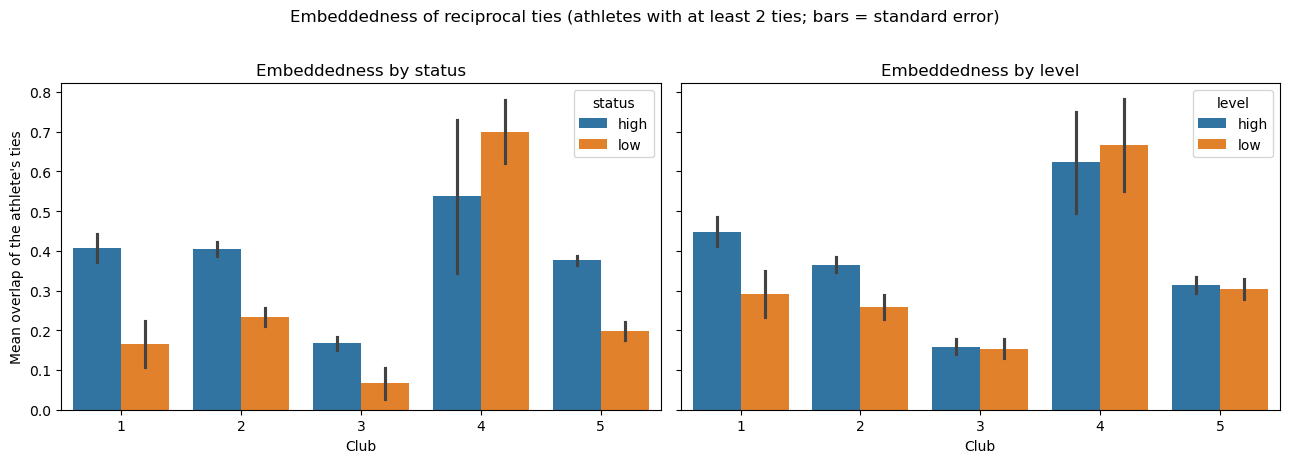

In [49]:
# ==========================================================
# Embeddedness by commitment level and status
# Uses the existing `edges_lb` and `nodes_lb`. New objects: emb_ties, emb_nodes
# ==========================================================

# ----------------------------------------------------------
#  Tie level: attach level and status of both ends of each reciprocal tie
# ----------------------------------------------------------
attr = nodes_lb[["club", "node", "level", "status"]]
emb_ties = (edges_lb
            .merge(attr.rename(columns={"node": "u", "level": "level_u", "status": "status_u"}),
                   on=["club", "u"])
            .merge(attr.rename(columns={"node": "v", "level": "level_v", "status": "status_v"}),
                   on=["club", "v"]))

# Tie type: both high, both low, or mixed
for g in ["level", "status"]:
    emb_ties["pair_" + g] = np.where(emb_ties[g + "_u"] != emb_ties[g + "_v"], "mixed",
                                     emb_ties[g + "_u"] + "-" + emb_ties[g + "_v"])

# ----------------------------------------------------------
#  Athlete level: mean embeddedness of each athlete's own ties
# ----------------------------------------------------------
both_ends = pd.concat([
    emb_ties[["club", "u", "overlap", "embeddedness"]].rename(columns={"u": "node"}),
    emb_ties[["club", "v", "overlap", "embeddedness"]].rename(columns={"v": "node"})])

emb_nodes = (both_ends.groupby(["club", "node"])
                      .agg(mean_overlap=("overlap", "mean"),
                           mean_common=("embeddedness", "mean"))
                      .reset_index()
                      .merge(nodes_lb[["club", "node", "degree", "level", "status"]],
                             on=["club", "node"]))

# Athletes with a single tie are excluded: that tie has zero common contacts by construction
emb_nodes = emb_nodes[emb_nodes["degree"] >= 2].copy()

# ----------------------------------------------------------
#  Descriptive tables
# ----------------------------------------------------------
for g in ["status", "level"]:
    print(f"\n=== TIE LEVEL: mean overlap by pair type of {g} ===")
    print(emb_ties.groupby(["club", "pair_" + g])["overlap"].mean().unstack().round(3))

    print(f"\n=== TIE LEVEL: share of ties with NO common contact, by pair type of {g} ===")
    print(emb_ties.assign(open_tie=emb_ties["embeddedness"] == 0)
                  .groupby(["club", "pair_" + g])["open_tie"].mean().unstack().round(3))

    print(f"\n=== ATHLETE LEVEL: mean overlap of own ties, by {g} (degree >= 2) ===")
    print(emb_nodes.groupby(["club", g])["mean_overlap"].mean().unstack().round(3))
    print("Number of athletes:")
    print(emb_nodes.groupby(["club", g]).size().unstack())

# ----------------------------------------------------------
#  Permutation test: shuffle labels among athletes of the SAME club AND SAME degree,
#    so that the difference cannot be explained by the number of ties
# ----------------------------------------------------------
def perm_test_degree(df, col, n_perm=N_PERM, seed=7):
    d = df.reset_index(drop=True)
    y = d["mean_overlap"].to_numpy()
    lab = (d[col] == "high").to_numpy()
    strata = [idx for idx in d.groupby(["club", "degree"]).indices.values() if len(idx) > 1]
    rng = np.random.default_rng(seed)

    obs = y[lab].mean() - y[~lab].mean()
    hits = 0
    for _ in range(n_perm):
        l = lab.copy()
        for idx in strata:
            l[idx] = rng.permutation(lab[idx])
        if abs(y[l].mean() - y[~l].mean()) >= abs(obs):
            hits += 1
    return obs, (hits + 1) / (n_perm + 1)

print("\n=== PERMUTATION TEST (labels shuffled within club and degree) ===")
for g in ["level", "status"]:
    obs, p = perm_test_degree(emb_nodes, g)
    print(f"{g}: mean overlap high - low = {obs:.3f}, p = {p:.3f}")

# ----------------------------------------------------------
#  Figure: mean overlap by club, split by status and by level
# ----------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, g in zip(axes, ["status", "level"]):
    sns.barplot(data=emb_nodes, x="club", y="mean_overlap", hue=g,
                hue_order=["high", "low"], errorbar="se", ax=ax)
    ax.set_title(f"Embeddedness by {g}")
    ax.set_xlabel("Club")
    ax.set_ylabel("Mean overlap of the athlete's ties")
plt.suptitle("Embeddedness of reciprocal ties (athletes with at least 2 ties; bars = standard error)",
             y=1.02)
plt.tight_layout()
plt.show()

## 7.4 Results and interpretation

**Local bridges (reference run).** Strong ties are rarely bridges in Clubs 2 and 5 (1.3% and 1.1% of ties), more often in Clubs 1 and 4 (4.2% and 8.3%), and most often in Club 3 (19.4%, 44 of 227 ties), consistent with its fragmented core-periphery structure. In the comparison that includes all athletes with at least one strong tie, high-status athletes have a much lower share of bridging ties than low-status athletes (difference -0.23, p < 0.001). This result is not reliable: an athlete with a single tie has by definition a bridging share of 1, and 27 of the 29 athletes with a single tie are low-status. After excluding athletes with fewer than two ties (n = 202) and shuffling the labels within club and degree (section 7.2b), the difference is +0.034 for status (p = 0.63) and +0.046 for commitment level (p = 0.13). Once the number of ties is controlled, there is no evidence that high-status athletes have fewer bridging ties.

**Embeddedness.** At the athlete level, high-status athletes have a higher mean overlap than low-status athletes in Clubs 1, 2, 3 and 5 (for example 0.41 against 0.17 in Club 1), which would suggest that recognised athletes sit inside dense groups. However, once labels are shuffled among athletes **with the same degree**, the difference is not distinguishable from chance (status: +0.058, p = 0.73; commitment: +0.039, p = 0.88).

**Reading for the research question.** Once the number of ties is controlled, high-status athletes are not located in a different structural position from other athletes: neither the share of bridging ties nor the mean overlap differs (p = 0.63 and p = 0.73). The raw differences come from degree, because high status is correlated with having many ties and athletes with few ties mechanically have a high share of bridges. The comparison has limited power, since the low-status group with at least two ties is small (62 athletes, 7 of them in Club 3).

**Limitations.** Small clubs (9 and 27 athletes) have very few athletes per group; ties are aggregated over the year for status but monthly for strong ties; and all these measures are *structural*: they describe positions, not whether behaviour actually spreads. This is the object of Part III.

# Part III: Diffusion (predictive modelling)

# 8. Problem definition and leakage-free design

Parts I and II describe *who is connected to whom*. Part III asks whether these connections matter for behaviour. The question is operationalised as a **forecasting problem**:

> For an athlete who is in the club in months *t* and *t+1* and is not already at the maximum of the scale, can we predict whether the weekly running frequency (`freq_run`) **increases** from month *t* to month *t+1*, and does knowledge of the athlete's contacts at month *t* improve the prediction?

If recognised athletes spread running to their contacts, then the behaviour and status of the contacts at month *t* should carry information about the athlete's change in month *t+1*, beyond the athlete's own history.

**Design principles**

- **Out-of-time validation (expanding window).** The test set is always one future month. The model for test month *t* is trained only on transitions whose outcome is already known at *t* (waves up to *t-1*). Test months are 6 to 11.
- **No leakage.** Every feature uses only information up to month *t*. Annual variables (`level`, `status`, `in_deg`), which use the whole year, are deliberately excluded and replaced by cumulative versions.
- **Metrics suited to an unbalanced outcome.** About 30% of athlete-months show an increase, so accuracy is not informative. The main metric is **PR-AUC** (average precision), compared with the base rate (the score of a useless model); we also report **ROC-AUC**, the **Brier score** (probability calibration) and the **lift in the top decile**.
- **Baselines and controls** (section 10) separate the contribution of the athlete's own history, of the contacts, and of the network structure.

## 8.1 Constants and feature construction

In [50]:
CEILING   = 7                # maximum of freq_run: athletes already there cannot increase
MIN_TRAIN = 5                # first fold trains on transitions t = 1..5
LAST_T    = 11               # last transition: wave 11 -> wave 12
KEYS      = ["club", "node"] # node IDs are unique only inside a club

BEHAV = ["freq_run", "time_run", "freq_other", "time_other", "kudos_in", "kudos_out"]

`build_panel` is a **function** rather than a block of statements because it is used twice: on the full data, and (in section 8.3) on data truncated at an earlier month to verify that no future information enters the features. It builds the following groups of variables:

- **Outcome.** `shift(-1)` brings the next month's `freq_run` into each row (within each athlete, hence the grouping by `club` and `node`). A row is `eligible` if the athlete is in the club both at *t* and *t+1* and not at the ceiling of the scale. `y` is 1 if `freq_run` increased and 0 otherwise, and `NaN` for non-eligible rows so that they cannot enter a model by mistake.
- **Lags.** `shift(1)` and `shift(2)` bring in the values of the two previous months.
- **Cumulative variables.** Mean from the entry into the club up to month *t* (cumulative sum divided by the number of months in the club). They replace the annual `level` and `in_deg`, which use the whole year.
- **Percentiles.** `rank(pct=True)` within club and month gives the position of the athlete among club mates in that month. It uses only data of that month, so nothing is estimated on the training set, and it removes the problem of different scales across clubs.
- **Calendar.** The month as sine and cosine, because the month as a number would not extrapolate to unseen months.
- **Contacts (exposure variables for the diffusion question).** From the edge list, the athlete-contact pairs of month *t* (kudos given and received) are built; the contacts' behaviour at *t* and *t-1* is read from the panel; for each athlete the following are computed: number of contacts, how much they run, how much they changed, the share running more than the athlete, and the share of contacts with recognition above the club median.

In [51]:
def build_panel(pan, edges):
    d = pan.sort_values(KEYS + ["wave"]).reset_index(drop=True).copy()
    by = lambda col: d.groupby(KEYS)[col]          # operations inside each athlete

    # ---- 1. Target: does freq_run increase from wave t to t+1? ----
    d["freq_run_next"] = by("freq_run").shift(-1)  # value of the NEXT month (outcome only)
    d["eligible"] = (d["freq_run"].notna() & d["freq_run_next"].notna()
                     & (d["freq_run"] < CEILING))
    d["y"] = np.where(d["eligible"], (d["freq_run_next"] > d["freq_run"]).astype(int), np.nan)

    # ---- 2. Lags: the same variables one and two months earlier ----
    for v in BEHAV:
        d[v + "_lag1"] = by(v).shift(1)
        d[v + "_lag2"] = by(v).shift(2)
    d["freq_run_delta"] = d["freq_run"] - d["freq_run_lag1"]

    # ---- 3. Cumulative variables: only data up to wave t ----
    in_club = d["freq_run"].notna().astype(int)
    n_in = in_club.groupby([d["club"], d["node"]]).cumsum()
    d["months_in_club"] = n_in.where(in_club == 1)
    for v, name in [("freq_run", "run_cum_freq"), ("time_run", "run_cum_time"),
                    ("kudos_in", "kudos_in_cum")]:
        s = d[v].fillna(0).groupby([d["club"], d["node"]]).cumsum()
        d[name] = s / n_in.replace(0, np.nan)      # running mean since club entry

    # ---- 4. Percentiles inside club AND month (replace level and status) ----
    d["recog_pct"] = d.groupby(["club", "wave"])["kudos_in_cum"].rank(pct=True)
    d["run_pct"]   = d.groupby(["club", "wave"])["run_cum_freq"].rank(pct=True)

    # ---- 5. Calendar ----
    d["wave_sin"] = np.sin(2 * np.pi * d["wave"] / 12)
    d["wave_cos"] = np.cos(2 * np.pi * d["wave"] / 12)

    # ---- 6. Contacts: athletes exchanging kudos with the athlete in wave t ----
    gave = edges.rename(columns={"source": "node", "target": "alter"})[["club", "wave", "node", "alter"]]
    recv = edges.rename(columns={"target": "node", "source": "alter"})[["club", "wave", "node", "alter"]]
    pairs = pd.concat([gave, recv]).drop_duplicates()      # each ego-alter pair once per wave

    alt = d[["club", "node", "wave", "freq_run", "freq_run_lag1", "recog_pct"]].rename(
        columns={"node": "alter", "freq_run": "alt_run",
                 "freq_run_lag1": "alt_run_prev", "recog_pct": "alt_recog"})
    ego = d[["club", "node", "wave", "freq_run"]].rename(columns={"freq_run": "ego_run"})

    pairs = (pairs.merge(alt, on=["club", "alter", "wave"], how="left")
                  .merge(ego, on=["club", "node", "wave"], how="left"))
    pairs["alt_delta"] = pairs["alt_run"] - pairs["alt_run_prev"]        # contact's recent change
    pairs["alt_above"] = (pairs["alt_run"] > pairs["ego_run"]).astype(float)
    pairs["alt_high"]  = (pairs["alt_recog"] > 0.5).astype(float)        # contact above club median

    contacts = (pairs.groupby(["club", "node", "wave"])
                     .agg(contacts_n=("alter", "size"),
                          contacts_run_mean=("alt_run", "mean"),
                          contacts_delta_mean=("alt_delta", "mean"),
                          contacts_above_share=("alt_above", "mean"),
                          contacts_high_share=("alt_high", "mean"))
                     .reset_index())
    d = d.merge(contacts, on=["club", "node", "wave"], how="left")
    d["contacts_n"] = d["contacts_n"].fillna(0)
    return d

## 8.2 Feature whitelist and modelling table

`FEATURES` is a **whitelist**: the models only see these columns. `freq_run_next`, `eligible` and `y` contain the outcome and are not in the list, so they cannot enter a model by distraction. The athlete table `ath` and the annual columns (`level`, `status`, `in_deg`) are neither in the list nor in the modelling table `panel_ml`. The printed numbers are the number of eligible rows and the share of increases (the positive class), which determine the choice of metrics.

In [52]:
FEATURES = (BEHAV
            + [v + "_lag1" for v in BEHAV] + [v + "_lag2" for v in BEHAV]
            + ["freq_run_delta", "run_cum_freq", "run_cum_time", "kudos_in_cum",
               "run_pct", "recog_pct", "months_in_club",
               "contacts_n", "contacts_run_mean", "contacts_delta_mean",
               "contacts_above_share", "contacts_high_share",
               "winter", "wave_sin", "wave_cos", "male", "female", "novice", "club"])

panel_ml = build_panel(all_pan, all_edges)

print("Rows:", len(panel_ml), "| eligible:", int(panel_ml["eligible"].sum()),
      "| share of increases:", round(panel_ml["y"].mean(), 3))

Rows: 3948 | eligible: 3186 | share of increases: 0.301


### Temporal folds

For test month *t*, training uses the rows with `wave <= t-1`: a row of wave *t-1* has its outcome at month *t*, which at prediction time is already known, as in a real forecast. The test set is the single wave *t*.

- Folds are only **row indices**, not copies of the data.
- **Inner validation:** the last training transition (wave *t-1*) is used as validation set to choose the number of trees / epochs (early stopping). The test month is never used for this.
- `check_folds` verifies four rules: training outcomes are known before the test month; the test set is a single month; no row is in both sets; the validation month follows the inner training months. A violation stops the notebook.

The table below reports fold sizes and the share of increases: if this share changes substantially across folds, a seasonal effect should be declared.

In [53]:
def make_folds(d):
    folds, ok = [], d["eligible"]
    for t in range(MIN_TRAIN + 1, LAST_T + 1):                # test months 6..11
        train = d[ok & (d["wave"] <= t - 1)]                  # transitions whose outcome is already known
        test  = d[ok & (d["wave"] == t)]                      # features at t, outcome at t+1
        folds.append({"test_t": t,
                      "train": train.index, "test": test.index,
                      "inner_train": train[train["wave"] <= t - 2].index,   # for tuning
                      "inner_val":   train[train["wave"] == t - 1].index})  # last training transition
    return folds

def check_folds(d, folds):
    for f in folds:
        tr, te = d.loc[f["train"]], d.loc[f["test"]]
        assert tr["wave"].max() + 1 <= f["test_t"]            # train outcomes are known before the test month
        assert te["wave"].nunique() == 1 and te["wave"].iloc[0] == f["test_t"]
        assert not set(zip(tr.club, tr.node, tr.wave)) & set(zip(te.club, te.node, te.wave))
        assert d.loc[f["inner_val"], "wave"].min() > d.loc[f["inner_train"], "wave"].max()
    print("All fold checks passed")

folds = make_folds(panel_ml)
check_folds(panel_ml, folds)

summary = []
for f in folds:
    tr, te = panel_ml.loc[f["train"]], panel_ml.loc[f["test"]]
    summary.append({"test transition": f"wave {f['test_t']} -> {f['test_t'] + 1}",
                    "train rows": len(tr), "test rows": len(te),
                    "share increases (train)": round(tr["y"].mean(), 3),
                    "share increases (test)": round(te["y"].mean(), 3)})
print(pd.DataFrame(summary).to_string(index=False))

All fold checks passed
test transition  train rows  test rows  share increases (train)  share increases (test)
    wave 6 -> 7        1383        290                    0.289                   0.297
    wave 7 -> 8        1673        298                    0.290                   0.386
    wave 8 -> 9        1971        295                    0.305                   0.325
   wave 9 -> 10        2266        300                    0.308                   0.283
  wave 10 -> 11        2566        309                    0.305                   0.259
  wave 11 -> 12        2875        311                    0.300                   0.315


## 8.3 Leakage control: the truncation test

If features are built correctly, rebuilding the table **as if the data ended at month T** must give exactly the same values for months up to T. The test cuts the data at waves 6 and 9 and compares. As a **negative control** a deliberately leaky variable (the annual mean of `freq_run`) is added: the test must detect it.

Expected output: *OK, no leakage* for the real features, and *LEAKAGE in ['freq_run_year_mean']* for the control.

In [54]:
def truncation_test(pan, edges, features, builder=build_panel, cut_waves=(6, 9)):
    keys = ["club", "node", "wave"]
    features = [f for f in features if f not in keys]         # keys are used as index
    full = builder(pan, edges)
    for T in cut_waves:
        # rebuild the table as if the data ended at wave T
        part = builder(pan[pan["wave"] <= T], edges[edges["wave"] <= T])
        a = full[full["wave"] <= T].set_index(keys)[features].sort_index()
        b = part.set_index(keys)[features].sort_index()
        bad = ((a.isna() != b.isna()).any() | ((a - b).abs().max() > 1e-9))
        bad = bad[bad].index.tolist()
        print(f"Data cut after wave {T}:", "OK, no leakage" if not bad else f"LEAKAGE in {bad}")

truncation_test(all_pan, all_edges, FEATURES)

# Negative control: a deliberately leaky variable (annual mean) must be detected
def build_leaky(pan, edges):
    d = build_panel(pan, edges)
    d["freq_run_year_mean"] = d.groupby(KEYS)["freq_run"].transform("mean")
    return d

truncation_test(all_pan, all_edges, FEATURES + ["freq_run_year_mean"], builder=build_leaky)

Data cut after wave 6: OK, no leakage
Data cut after wave 9: OK, no leakage
Data cut after wave 6: LEAKAGE in ['freq_run_year_mean']
Data cut after wave 9: LEAKAGE in ['freq_run_year_mean']


## 8.4 Preprocessing: log transformation and standardisation within each fold

For every time fold, the input variables are transformed in two steps: a log transformation of the count variables, followed by standardisation. Both steps are repeated at each fold using only the training data of that fold.

**Step 1: log transformation of the counts**
`kudos_in` and `kudos_out` count the distinct partners an athlete exchanged kudos with in a month. They have long tails (a few athletes have many partners, most have few), so a handful of extreme values would dominate the scale. `log1p(x) = log(1 + x)` compresses these values and handles zeros correctly, because `log1p(0) = 0`. The ordinal variables `freq_run` and `time_run` are not transformed, since their scale is short (0-7) and the distances between categories should be preserved.

**Step 2: standardisation**
Each variable is centred and scaled with `(x - mean) / sd`, so that all inputs are on a comparable scale. This matters for neural networks, which learn poorly when inputs have very different magnitudes. Tree-based models such as XGBoost do not need it.

**Order of the operations**
The log transformation is applied first, on the raw counts. After standardisation, values below the mean become negative, and the logarithm of a value below −1 is undefined. `log1p` has no parameters to estimate from the data, so it can be applied to training and test sets without leakage.

**Why the statistics come from the training set only**
The mean and standard deviation are computed on the training rows of each fold and then applied unchanged to the test rows. If they were computed on the whole dataset, information from the test months would enter the training process. This would be a mild form of data leakage. The test set is treated as new data arriving after training, as it would be in a real prediction. Because the training set grows from one fold to the next, the statistics are recomputed at every fold.

**Other design choices**
- The transformations work on a **copy** of the selected columns, so the original `panel_ml` table is never modified.
- `std().replace(0, 1)` prevents a division by zero if a variable is constant in the training set.
- The cell below applies the procedure to four variables (`SCALE`) to show it. XGBoost does not need it; the GNN pipeline (section 10) applies the same logic to all of its inputs inside `make_fold_graphs`.

In [55]:
SCALE    = ["freq_run", "time_run", "kudos_in", "kudos_out"]
LOG_VARS_DEMO = ["kudos_in", "kudos_out"]          # count variables with long tails

def standardise_fold(f):
    """log1p on the counts, then standardise with statistics from the TRAINING rows only."""
    train = panel_ml.loc[f["train"], SCALE].copy()
    test  = panel_ml.loc[f["test"],  SCALE].copy()
    train[LOG_VARS_DEMO] = np.log1p(train[LOG_VARS_DEMO])
    test[LOG_VARS_DEMO]  = np.log1p(test[LOG_VARS_DEMO])
    mu, sd = train.mean(), train.std().replace(0, 1)
    return (train - mu) / sd, (test - mu) / sd, mu, sd

for f in folds:
    X_train, X_test, mu, sd = standardise_fold(f)

print(f"Training statistics of the last fold (test month {f['test_t']}):")
print(pd.DataFrame({"mean": mu, "sd": sd}).round(3))
print("\nStandardised training means (should be ~0):", X_train.mean().round(6).to_dict())

Training statistics of the last fold (test month 11):
            mean     sd
freq_run   2.412  1.602
time_run   2.453  1.751
kudos_in   1.196  1.053
kudos_out  1.115  1.114

Standardised training means (should be ~0): {'freq_run': -0.0, 'time_run': -0.0, 'kudos_in': 0.0, 'kudos_out': -0.0}


## 8.5 Persisting the modelling tables

The modelling tables are saved locally (`data/`) and, if `UPLOAD_TO_S3 = True`, uploaded to the S3 bucket. This allows section 10 to be re-run on its own on another machine (it reads the tables from S3 when they are not in memory).

In [56]:
panel_ml.to_parquet(DATA_DIR / "panel_ml.parquet")
all_edges.to_parquet(DATA_DIR / "all_edges.parquet")
with open(DATA_DIR / "meta.json", "w") as fh:
    json.dump({"FEATURES": FEATURES, "LAST_T": LAST_T, "MIN_TRAIN": MIN_TRAIN}, fh)
print("Saved:", sorted(p.name for p in DATA_DIR.iterdir()))

if UPLOAD_TO_S3:
    s3_client = boto3.client("s3", region_name=REGION)
    for name in ("panel_ml.parquet", "all_edges.parquet", "meta.json"):
        s3_client.upload_file(str(DATA_DIR / name), BUCKET, f"{S3_PREFIX}{name}")
    print(f"Uploaded to s3://{BUCKET}/{S3_PREFIX}")

Saved: ['all_edges.parquet', 'meta.json', 'panel_ml.parquet']


# 9. Machine-learning approach: gradient-boosted trees (XGBoost)

The first model is a **tabular** gradient-boosted classifier trained on all `FEATURES`, including the **explicit exposure variables** that summarise the athlete's contacts (`contacts_*`). The procedure for each fold is:

1. **Step A:** train on the inner-training months with early stopping on the inner-validation month (metric: PR-AUC) to choose the number of trees.
2. **Step B:** train a **new** model on all training rows with that number of trees, and predict the test month.

Hyper-parameters are conservative (shallow trees, strong regularisation) because the data are small (about 3,200 eligible athlete-months).

## 9.1 Metrics helper and training

In [57]:
def top_decile_lift(y, p):
    """Share of increases among the 10% highest-scored rows, relative to the overall share."""
    y, p = np.asarray(y), np.asarray(p)
    k = max(1, int(round(len(y) * 0.10)))
    return y[np.argsort(-p)[:k]].mean() / y.mean()

Param = dict(n_estimators=500, learning_rate=0.05, max_depth=3,
             min_child_weight=5, subsample=0.8, colsample_bytree=0.8,
             reg_lambda=5.0, eval_metric="aucpr", random_state=SEED, n_jobs=-1)

In [58]:
preds_xgb = []
lc_rows = []

for f in folds:
    inner_train = panel_ml.loc[f["inner_train"]]
    inner_val   = panel_ml.loc[f["inner_val"]]
    train       = panel_ml.loc[f["train"]]
    test        = panel_ml.loc[f["test"]]

    xgb_model_1 = xgb.XGBClassifier(**Param, early_stopping_rounds=30)
    xgb_model_1.fit(inner_train[FEATURES], inner_train["y"].astype(int),
                    eval_set=[(inner_val[FEATURES], inner_val["y"].astype(int))],
                    verbose=False)
    best_n = xgb_model_1.best_iteration + 1
    print("Trees selected by early stopping:", best_n)

    model = xgb.XGBClassifier(**{**Param, "n_estimators": best_n})
    model.fit(train[FEATURES], train["y"].astype(int), verbose=False)

    p = model.predict_proba(test[FEATURES])[:, 1]
    p_tr = model.predict_proba(train[FEATURES])[:, 1]

    preds_xgb.append(pd.DataFrame({"idx": test.index, "y": test["y"].astype(int).values,
                                   "p": p, "fold": f["test_t"], "n_trees": best_n}))
    lc_rows.append({"test_t": f["test_t"], "n_train": len(train),
                    "pr_auc_train": average_precision_score(train["y"].astype(int), p_tr),
                    "pr_auc_test": average_precision_score(test["y"].astype(int), p),
                    "base_rate": test["y"].mean()})

preds_xgb = pd.concat(preds_xgb, ignore_index=True)

Trees selected by early stopping: 1
Trees selected by early stopping: 22
Trees selected by early stopping: 29
Trees selected by early stopping: 7
Trees selected by early stopping: 32
Trees selected by early stopping: 66


## 9.2 Pooled out-of-time metrics

In [59]:
print("Base rate (a useless model scores this PR-AUC):", round(preds_xgb["y"].mean(), 3))
print("PR-AUC :", round(average_precision_score(preds_xgb["y"], preds_xgb["p"]), 3))
print("ROC-AUC:", round(roc_auc_score(preds_xgb["y"], preds_xgb["p"]), 3))
print("Brier  :", round(brier_score_loss(preds_xgb["y"], preds_xgb["p"]), 3), "(reference about 0.21)")
print("Lift top 10%:", round(top_decile_lift(preds_xgb["y"], preds_xgb["p"]), 2))

print("\nPR-AUC by test month:")
print(pd.Series({k: average_precision_score(g["y"], g["p"]) for k, g in preds_xgb.groupby("fold")}).round(3))
print("Trees selected per fold:", preds_xgb.groupby("fold")["n_trees"].first().to_dict())

Base rate (a useless model scores this PR-AUC): 0.311
PR-AUC : 0.44
ROC-AUC: 0.646
Brier  : 0.203 (reference about 0.21)
Lift top 10%: 1.66

PR-AUC by test month:
6     0.351
7     0.539
8     0.528
9     0.376
10    0.512
11    0.444
dtype: float64
Trees selected per fold: {6: 1, 7: 22, 8: 29, 9: 7, 10: 32, 11: 66}


**Results (reference run).** Pooled over the six test months, XGBoost reaches PR-AUC **0.437** against a base rate of **0.311**, ROC-AUC **0.638**, Brier score **0.204** and a top-decile lift of **1.72**. The signal is real but modest: the model identifies increases better than chance, and its probabilities are slightly better calibrated than the constant prediction (Brier reference about 0.21), but it is far from a precise forecast.

## 9.3 Learning curve (walk-forward)

Training and test PR-AUC as the training window expands. A large and persistent gap would indicate overfitting; a test curve close to the base rate would indicate no generalisable signal.

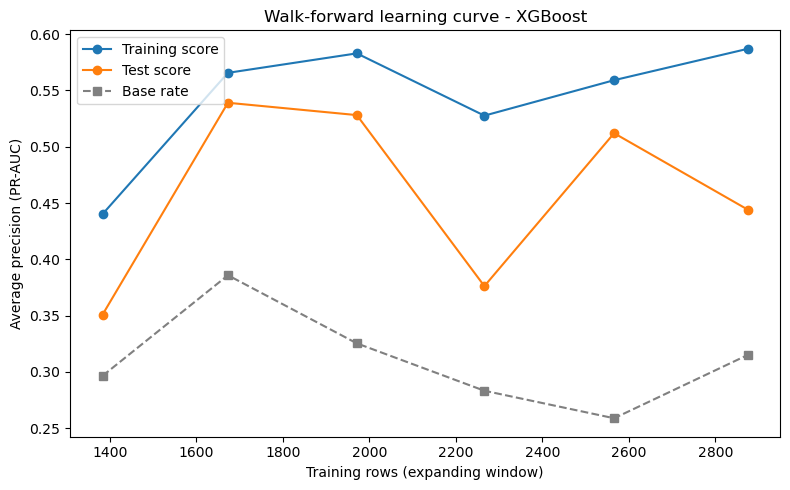

In [60]:
lc_xgb = pd.DataFrame(lc_rows)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(lc_xgb["n_train"], lc_xgb["pr_auc_train"], marker="o", label="Training score")
ax.plot(lc_xgb["n_train"], lc_xgb["pr_auc_test"], marker="o", label="Test score")
ax.plot(lc_xgb["n_train"], lc_xgb["base_rate"], marker="s", linestyle="--", color="grey", label="Base rate")
ax.set_xlabel("Training rows (expanding window)")
ax.set_ylabel("Average precision (PR-AUC)")
ax.set_title("Walk-forward learning curve - XGBoost")
ax.legend()
plt.tight_layout()
plt.show()

# 10. Deep-learning approach: Graph Neural Network (GraphSAGE)

XGBoost receives the contacts only through hand-made summaries (`contacts_*`). A **Graph Neural Network** instead receives the **network itself**: each (club, month) is a graph whose nodes are athletes and whose edges are the kudos exchanged in that month, and the model learns how to combine an athlete's features with those of the contacts (*message passing*).

**Architecture.** A two-layer **GraphSAGE** network (`SAGEConv`, mean aggregation) with ReLU and dropout, followed by a linear layer that outputs the probability that the athlete's running frequency increases next month. GraphSAGE keeps the athlete's **own** features separate from the aggregated features of the contacts, so the contribution of the contacts can be isolated.

**Inputs.** Node features are the individual features in `FEATURES` (the `contacts_*` summaries and the club identifier are excluded, because the graph provides that information), plus three **missing-value flags** for the running-frequency variables. Log transformation and standardisation use statistics from the training rows of each fold only. Edges are made bidirectional: this is a modelling choice that lets messages flow both ways along a kudos tie, at the cost of ignoring who gave to whom. A directed variant is a natural sensitivity check.

**Control experiments.** To know whether the *contacts* matter, the same architecture is trained with three different edge sets:

| Edge mode | Meaning | What it tests |
|---|---|---|
| `real` | actual kudos graph of the month | full model |
| `none` | no edges (each athlete is alone) | contribution of the athlete's own features only |
| `shuffled` (called *rewired* in the paper) | edges randomly rewired and kept symmetric (like the real graph), approximately keeping each athlete's number of ties | whether *who* the contacts are matters, beyond *how many* contacts one has |

**Reference models** on the same test rows: a logistic regression on the athlete's own features (`logit`), a constant prediction equal to the training base rate (`base`), and the XGBoost model of section 9 (`xgboost`, added to the comparison).

**Level-blind ablation.** The experiment is repeated after removing the features that encode the athlete's **own running-frequency level** (`freq_run`, its lags and change, the cumulative mean and its percentile). This tests how much of the predictive signal comes from the current level of the athlete (for example, mean reversion) rather than from other information.

**Training protocol (per fold).** *Step A:* early stopping on the inner-validation month decides the number of epochs. *Step B:* a **new** model is trained on all training months for that number of epochs and evaluated on the test month. Each configuration is repeated with several random seeds, and predictions are averaged over seeds.

## 10.1 Input data

In the normal top-to-bottom run, `panel_ml`, `all_edges` and `folds` are already in memory from Part III. If this section is run **on its own** (for example in a new SageMaker session), the tables are read from S3, and the cells that define the constants and `make_folds` (sections 8.1 and 8.2) must be executed first.

In [61]:
if "panel_ml" not in globals():
    s3_client = boto3.client("s3", region_name=REGION)
    needed = ["panel_ml.parquet", "all_edges.parquet", "meta.json"]
    try:
        for name in needed:
            s3_client.head_object(Bucket=BUCKET, Key=f"{S3_PREFIX}{name}")
    except Exception as err:
        raise FileNotFoundError(f"Cannot read s3://{BUCKET}/{S3_PREFIX}{{{', '.join(needed)}}}: {err}")

    def read_parquet_s3(name):
        body = s3_client.get_object(Bucket=BUCKET, Key=f"{S3_PREFIX}{name}")["Body"].read()
        return pd.read_parquet(io.BytesIO(body))

    panel_ml = read_parquet_s3("panel_ml.parquet")
    all_edges = read_parquet_s3("all_edges.parquet")
    meta = json.loads(s3_client.get_object(Bucket=BUCKET, Key=f"{S3_PREFIX}meta.json")["Body"].read())
    FEATURES, LAST_T, MIN_TRAIN = meta["FEATURES"], meta["LAST_T"], meta["MIN_TRAIN"]
    folds = make_folds(panel_ml)
    print("Loaded from S3.")
else:
    print("Using the tables already in memory.")

print("panel_ml:", panel_ml.shape, "| all_edges:", all_edges.shape, "| temporal folds:", len(folds))

Using the tables already in memory.
panel_ml: (3948, 47) | all_edges: (19020, 4) | temporal folds: 6


## 10.2 Feature sets and hyper-parameters

In [62]:
GNN_BASE_FEATURES = [c for c in FEATURES if not c.startswith("contacts_") and c != "club"]

LEVEL_COLS = ["freq_run", "freq_run_lag1", "freq_run_lag2",
              "freq_run_delta", "run_cum_freq", "run_pct"]       # own running-frequency level
assert all(c in FEATURES for c in LEVEL_COLS), "typo in LEVEL_COLS"

MISSING_FLAGS = ["freq_run", "freq_run_lag1", "freq_run_lag2"]
BIDIRECTIONAL = True

def set_feature_set(level_blind):
    """Define the GNN input columns (module-level globals used by the functions below)."""
    global GNN_FEATURES, LOG_VARS, LOG_IDX
    GNN_FEATURES = [c for c in GNN_BASE_FEATURES if not (level_blind and c in LEVEL_COLS)]
    LOG_VARS = [c for c in GNN_FEATURES if c.startswith("kudos")]
    LOG_IDX = [GNN_FEATURES.index(c) for c in LOG_VARS]

# Hyper-parameters (one place)
CFG = dict(hidden=32, dropout=0.3, aggr="mean", n_layers=2,
           lr=0.005, wd=1e-4, max_epochs=200, patience=25, min_epochs=20,
           use_pos_weight=False)          # False keeps probabilities calibrated (comparable Brier score)
EDGE_MODES = ["real", "none", "shuffled"]

set_feature_set(level_blind=False)
print("Individual features:", len(GNN_FEATURES), "+", len(MISSING_FLAGS), "missing flags")

Individual features: 31 + 3 missing flags


## 10.3 One graph per club and month

`build_snapshots` creates, **once**, a raw snapshot for every (club, wave): node features (with `NaN` where missing), missing flags, the kudos edges of that month only, the outcome and the row position in `panel_ml`. Nothing fold-dependent is stored here, so no information can leak between folds. Wave 12 is excluded because it has no next month.

In [63]:
def build_snapshots():
    edges_by_month = {k: g for k, g in all_edges.groupby(["club", "wave"])}
    snaps = {}
    for (c, t), g in panel_ml.groupby(["club", "wave"]):
        if t > LAST_T:
            continue                                          # wave 12 has no next month, hence no target
        g = g.sort_values("node")                             # fixed athlete order inside the graph
        pos = {int(n): i for i, n in enumerate(g["node"])}    # athlete ID -> row position 0..N-1

        e = edges_by_month.get((c, t))                        # kudos of THIS month only
        if e is None or len(e) == 0:
            ei = np.empty((2, 0), dtype=np.int64)
        else:
            src, tgt = e["source"].astype(int).map(pos), e["target"].astype(int).map(pos)
            assert src.notna().all() and tgt.notna().all(), f"edge to unknown athlete (club {c}, wave {t})"
            ei = np.vstack([src.to_numpy(), tgt.to_numpy()]).astype(np.int64)
            if BIDIRECTIONAL:
                ei = np.hstack([ei, ei[::-1]])
            ei = np.unique(ei, axis=1)                        # drop duplicated edges

        snaps[(c, t)] = {
            "x_raw":      g[GNN_FEATURES].to_numpy(dtype=float),          # [N, F] raw values, with NaN
            "flags":      g[MISSING_FLAGS].notna().to_numpy(dtype=float), # [N, 3] 1 = value present
            "edge_index": ei,                                             # [2, E] positions inside this graph
            "y":          g["y"].to_numpy(dtype=float),                   # NaN where the athlete is not eligible
            "row_idx":    g.index.to_numpy(),                             # row of panel_ml for each node
        }
    return snaps

snapshots = build_snapshots()
print("Snapshots:", len(snapshots))

Snapshots: 55


## 10.4 Fold-specific graphs

For every fold, `make_fold_graphs` standardises the features with statistics computed **only on the training rows** (`fit_on="train"`, or `"inner_train"` for the tuning step), applies `log1p` to the kudos counts first, replaces missing values by the training mean (0 after standardisation) and appends the missing flags. Training graphs are those of waves up to *t-1*, test graphs those of wave *t*; graphs after the test month are never used. Sanity checks stop the code on any inconsistency (leftover `NaN`, edge indices out of range, mask counts different from the fold sizes, wrong waves).

In [64]:
def make_fold_graphs(f, fit_on="train"):
    # statistics from the training rows of this fold
    tr = panel_ml.loc[f[fit_on], GNN_FEATURES].to_numpy(dtype=float)
    
    tr[:, LOG_IDX] = np.log1p(tr[:, LOG_IDX])
    mu = np.nan_to_num(np.nanmean(tr, axis=0))
    sd = np.nanstd(tr, axis=0, ddof=1)
    sd = np.where(np.isfinite(sd) & (sd > 0), sd, 1.0)

    ids = {k: f[k].to_numpy() for k in ["train", "inner_train", "inner_val", "test"]}
    out = {"train": [], "test": []}

    for (c, t), s in snapshots.items():
        if t > f["test_t"]:
            continue                                      # never use graphs after the test month
        rows = s["row_idx"]

        x = s["x_raw"].copy()
        x[:, LOG_IDX] = np.log1p(x[:, LOG_IDX])
        x = (x - mu) / sd
        x = np.nan_to_num(x, nan=0.0)                     # missing -> training mean (0 after standardisation)
        x = np.hstack([x, s["flags"]])

        data = Data(x=torch.tensor(x, dtype=torch.float32),
                    edge_index=torch.tensor(s["edge_index"], dtype=torch.long),
                    y=torch.tensor(np.nan_to_num(s["y"], nan=0.0), dtype=torch.float32))
        data.row_idx = torch.tensor(rows, dtype=torch.long)   # do NOT rename to row_index: PyG would treat it as an edge index
        data.club, data.wave = int(c), int(t)

        if t < f["test_t"]:                               # training graphs: waves up to t_test - 1
            data.train_mask       = torch.tensor(np.isin(rows, ids["train"]), dtype=torch.bool)
            data.inner_train_mask = torch.tensor(np.isin(rows, ids["inner_train"]), dtype=torch.bool)
            data.inner_val_mask   = torch.tensor(np.isin(rows, ids["inner_val"]), dtype=torch.bool)
            out["train"].append(data)
        else:                                             # test graphs: wave t_test only
            data.test_mask = torch.tensor(np.isin(rows, ids["test"]), dtype=torch.bool)
            out["test"].append(data)

    # ---- sanity checks ----
    for d in out["train"] + out["test"]:
        assert not torch.isnan(d.x).any(), "NaN left in x"
        assert d.edge_index.numel() == 0 or int(d.edge_index.max()) < d.x.shape[0]
    assert sum(int(d.train_mask.sum()) for d in out["train"]) == len(f["train"])
    assert sum(int(d.test_mask.sum()) for d in out["test"]) == len(f["test"])
    assert max(d.wave for d in out["train"]) < f["test_t"] and {d.wave for d in out["test"]} == {f["test_t"]}
    return out

## 10.5 Model, training and prediction functions

In [65]:
#  model: SAGEConv keeps the athlete's own features separate from the contacts' 
class SAGENet(nn.Module):
    def __init__(self, in_channels, hidden=32, dropout=0.3, aggr="mean", n_layers=2):
        super().__init__()
        dims = [in_channels] + [hidden] * n_layers
        self.convs = nn.ModuleList(
            [SAGEConv(dims[i], dims[i + 1], aggr=aggr) for i in range(n_layers)])
        self.lin = nn.Linear(hidden, 1)
        self.dropout = dropout

    def forward(self, x, edge_index):
        for conv in self.convs:
            x = F.relu(conv(x, edge_index))
            x = F.dropout(x, p=self.dropout, training=self.training)
        return self.lin(x).squeeze(-1)

In [66]:
# edge nodes 
def to_batch(graphs, mode, seed):
    """Copy the graphs, change their edges according to `mode`, and merge them into one batch."""
    gen = torch.Generator().manual_seed(int(seed))
    out = []
    for d in graphs:
        d2 = d.clone()
        if mode == "none":                                   # control: the athlete sees no contact at all
            d2.edge_index = torch.empty((2, 0), dtype=torch.long)
        elif mode == "shuffled" and d.edge_index.shape[1] > 0:
            ei = d.edge_index
            # Rewire each tie ONCE and symmetrise again, so that the control has the same structure
            # as the real graph (BIDIRECTIONAL graphs are symmetric). Shuffling the targets of the
            # already-symmetric edge list would break the symmetry and produce a directed graph.
            und = ei[:, ei[0] < ei[1]] if BIDIRECTIONAL else ei
            perm = torch.randperm(und.shape[1], generator=gen)
            und = torch.stack([und[0], und[1][perm]])         # targets reshuffled: degrees preserved up to self-loops/duplicates
            und = und[:, und[0] != und[1]]                    # drop self-loops created by the shuffle
            if BIDIRECTIONAL and und.shape[1] > 0:
                und = torch.unique(torch.cat([und, und.flip(0)], dim=1), dim=1)
            d2.edge_index = und
        out.append(d2)
    return Batch.from_data_list(out).to(DEVICE)

In [67]:
def fit(batch, fit_mask_name, val_mask_name=None, n_epochs=None, seed=0, pos_weight=None):
    """Train a NEW model. With val_mask_name: early stopping on PR-AUC, returns the best epoch.
    Without it: trains exactly n_epochs."""
    torch.manual_seed(seed)
    np.random.seed(seed)
    model = SAGENet(batch.x.shape[1], CFG["hidden"], CFG["dropout"], CFG["aggr"], CFG["n_layers"]).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=CFG["lr"], weight_decay=CFG["wd"])
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

    y = batch.y.view(-1)
    fit_mask = getattr(batch, fit_mask_name)
    if val_mask_name is not None:
        val_mask = getattr(batch, val_mask_name)
        y_val = y[val_mask].cpu().numpy().astype(int)

    best, best_epoch, wait = -1.0, 1, 0
    for epoch in range(1, (n_epochs or CFG["max_epochs"]) + 1):
        model.train()
        opt.zero_grad()
        loss = loss_fn(model(batch.x, batch.edge_index)[fit_mask], y[fit_mask])
        loss.backward()
        opt.step()

        if val_mask_name is not None:
            model.eval()
            with torch.no_grad():
                p = torch.sigmoid(model(batch.x, batch.edge_index))[val_mask].cpu().numpy()
            score = average_precision_score(y_val, p)
            if score > best:
                best, best_epoch, wait = score, epoch, 0
            else:
                wait += 1
                if wait >= CFG["patience"]:
                    break
    return model, best_epoch

In [68]:
@torch.no_grad()
def predict_test(model, batch):
    model.eval()
    m = batch.test_mask
    p = torch.sigmoid(model(batch.x, batch.edge_index))[m].cpu().numpy()
    return (batch.row_idx[m].cpu().numpy(),
            batch.y.view(-1)[m].cpu().numpy().astype(int), p)

## 10.6 Running the experiment

`run_experiment` loops over the six temporal folds. For each fold it (i) fits the **reference models** (logistic regression on the athlete's own features, and the constant base-rate model), and (ii) trains the **GNN with each edge mode and each seed** following the two-step protocol. The driver cell then runs the experiment for the full feature set (`level`) and, if `RUN_LEVEL_BLIND_ABLATION` is `True`, for the level-blind feature set (`level_blind`). The XGBoost predictions of section 9 are added to the `level` results so that all models are compared on **exactly the same test rows**.

This is the most expensive cell of the notebook.

In [69]:
def run_experiment(run_label):
    all_rows = []
    print("Variant:", run_label, "| features:", len(GNN_FEATURES), "+", len(MISSING_FLAGS), "flags")
    for f in folds:
        # Two preprocessing fits: step A uses only inner-training rows, step B the full training rows
        gA = make_fold_graphs(f, fit_on="inner_train")
        gB = make_fold_graphs(f, fit_on="train")

        # ---- non-graph references on the step-B features ----
        bt = Batch.from_data_list(gB["train"])
        be = Batch.from_data_list(gB["test"])
        X_tr, y_tr = bt.x[bt.train_mask].numpy(), bt.y.view(-1)[bt.train_mask].numpy().astype(int)
        X_te, y_te = be.x[be.test_mask].numpy(), be.y.view(-1)[be.test_mask].numpy().astype(int)
        rows_te = be.row_idx[be.test_mask].numpy()

        lr_model = LogisticRegression(max_iter=2000).fit(X_tr, y_tr)    # athlete features only, no graph
        refs = {"logit": lr_model.predict_proba(X_te)[:, 1],
                "base": np.full(len(y_te), y_tr.mean())}                # constant = training base rate
        for name, p in refs.items():
            all_rows.append(pd.DataFrame({"model": name, "idx": rows_te, "y": y_te, "p": p,
                                          "fold": f["test_t"], "seed": 0, "n_epochs": 0}))

        # ---- GNN with real / no / shuffled edges ----
        for mode in EDGE_MODES:
            for seed in range(N_SEEDS):
                # Step A: number of epochs from early stopping on the inner validation month
                trainA = to_batch(gA["train"], mode, seed)
                pw = None
                if CFG["use_pos_weight"]:
                    yy = trainA.y.view(-1)[trainA.inner_train_mask]
                    pw = ((len(yy) - yy.sum()) / yy.sum()).reshape(1)
                _, best_epoch = fit(trainA, "inner_train_mask", "inner_val_mask", seed=seed, pos_weight=pw)
                best_epoch = max(best_epoch, CFG["min_epochs"])        # early stopping on one month is noisy: floor

                # Step B: NEW model on the full training set with that number of epochs
                trainB = to_batch(gB["train"], mode, seed)
                testB = to_batch(gB["test"], mode, seed + 1000)
                pw = None
                if CFG["use_pos_weight"]:
                    yy = trainB.y.view(-1)[trainB.train_mask]
                    pw = ((len(yy) - yy.sum()) / yy.sum()).reshape(1)
                model, _ = fit(trainB, "train_mask", None, n_epochs=best_epoch, seed=seed, pos_weight=pw)
                rows, y_, p_ = predict_test(model, testB)
                all_rows.append(pd.DataFrame({"model": f"gnn_{mode}", "idx": rows, "y": y_, "p": p_,
                                              "fold": f["test_t"], "seed": seed, "n_epochs": best_epoch}))
        print(f"  fold {f['test_t']} done")
    return pd.concat(all_rows, ignore_index=True)

results_store = {}      # one entry per feature variant: "level", "level_blind"

for level_blind in ([False, True] if RUN_LEVEL_BLIND_ABLATION else [False]):
    label = "level_blind" if level_blind else "level"
    set_feature_set(level_blind)
    snapshots = build_snapshots()
    res_df = run_experiment(label)

    if not level_blind:                       # add XGBoost (section 9) on the same test rows
        xgb_rows = preds_xgb.rename(columns={"idx": "idx"})[["idx", "y", "p", "fold"]].assign(
            model="xgboost", seed=0, n_epochs=0)
        gnn_idx = set(res_df.loc[res_df["model"] == "gnn_real", "idx"])
        assert gnn_idx == set(xgb_rows["idx"]), "XGBoost and GNN must be evaluated on the same rows"
        res_df = pd.concat([res_df, xgb_rows], ignore_index=True)

    results_store[label] = res_df
    print("Stored:", label, "| rows:", len(res_df))

Variant: level | features: 31 + 3 flags
  fold 6 done
  fold 7 done
  fold 8 done
  fold 9 done
  fold 10 done
  fold 11 done
Stored: level | rows: 32454
Variant: level_blind | features: 25 + 3 flags
  fold 6 done
  fold 7 done
  fold 8 done
  fold 9 done
  fold 10 done
  fold 11 done
Stored: level_blind | rows: 30651


## 10.7 Pooled out-of-time metrics and paired bootstrap

For each model, predictions are averaged over seeds, giving one probability per test athlete-month; metrics are then computed on the six test months **pooled**. To judge whether differences between models are real, an **athlete-level paired bootstrap** is used: athletes are resampled with replacement (all their test months together), and **every model is re-evaluated on the same resample**. A 95% interval for a *difference* that excludes zero indicates a real difference.

In [70]:
VARIANT = "level"          # which stored run to analyse: "level" or "level_blind"
preds = results_store[VARIANT]

# Average over seeds, then one row per test athlete-month and one column per model
avg = preds.groupby(["model", "idx"], as_index=False).agg(y=("y", "first"), p=("p", "mean"), fold=("fold", "first"))
T = avg.pivot(index="idx", columns="model", values="p")
meta_rows = avg.drop_duplicates("idx").set_index("idx")[["y", "fold"]]
T = T.join(meta_rows)
T["athlete"] = (panel_ml.loc[T.index, "club"].astype(str) + "_" + panel_ml.loc[T.index, "node"].astype(str)).values
MODELS = [c for c in T.columns if c not in ("y", "fold", "athlete")]

# ---- point estimates ----
y_all = T["y"].to_numpy().astype(int)
rows = []
for m in MODELS:
    p = T[m].to_numpy()
    sp = preds[preds["model"] == m]
    seed_roc = [roc_auc_score(g["y"], g["p"]) for _, g in sp.groupby("seed")] if sp["seed"].nunique() > 1 else [np.nan]
    rows.append({"model": m,
                 "ROC-AUC": roc_auc_score(y_all, p) if np.ptp(p) > 0 else 0.5,
                 "PR-AUC": average_precision_score(y_all, p),
                 "Brier": brier_score_loss(y_all, p),
                 "Lift top10%": top_decile_lift(y_all, p),
                 "ROC single seed (mean)": np.mean(seed_roc),
                 "ROC single seed (sd)": np.std(seed_roc)})
table = pd.DataFrame(rows).set_index("model").round(4)
print(f"POOLED TEST RESULTS ({VARIANT}) | base rate = {y_all.mean():.3f}")
print(table.to_string())

POOLED TEST RESULTS (level) | base rate = 0.311
              ROC-AUC  PR-AUC   Brier  Lift top10%  ROC single seed (mean)  ROC single seed (sd)
model                                                                                           
base           0.4797  0.3001  0.2146       1.0374                     NaN                   NaN
gnn_none       0.6274  0.4035  0.2069       1.5204                  0.6187                0.0116
gnn_real       0.6083  0.4086  0.2111       1.4846                  0.5985                0.0073
gnn_shuffled   0.6071  0.4055  0.2103       1.5204                  0.5969                0.0100
logit          0.6455  0.4385  0.2072       1.5919                     NaN                   NaN
xgboost        0.6456  0.4405  0.2029       1.6635                     NaN                   NaN


In [71]:
# ---- paired bootstrap: resample ATHLETES, recompute every model on the same resample ----
rng = np.random.default_rng(7)
groups = T.reset_index(drop=True).groupby("athlete").indices
athletes = np.array(list(groups.keys()))
BOOT_MODELS = [m for m in MODELS if m != "base"]          # the constant model has no ranking to bootstrap
P = {m: T[m].to_numpy() for m in MODELS}
y_arr = T["y"].to_numpy().astype(int)

def boot_metric(fn_name, m, pos):
    yy, pp = y_arr[pos], P[m][pos]
    if yy.min() == yy.max() or np.ptp(pp) == 0:
        return np.nan
    return roc_auc_score(yy, pp) if fn_name == "roc" else average_precision_score(yy, pp)

boot = {(m, k): [] for m in BOOT_MODELS for k in ("roc", "pr")}
for _ in range(N_BOOT):
    pos = np.concatenate([groups[a] for a in rng.choice(athletes, size=len(athletes))])
    for m in BOOT_MODELS:
        for k in ("roc", "pr"):
            boot[(m, k)].append(boot_metric(k, m, pos))
boot = {k: np.array(v, dtype=float) for k, v in boot.items()}

def ci(arr):
    return np.nanpercentile(arr, [2.5, 97.5]).round(4)

print("\n95% CI (bootstrap over athletes)")
for m in BOOT_MODELS:
    print(f"{m:15s} ROC {ci(boot[(m, 'roc')])}  PR {ci(boot[(m, 'pr')])}")

print("\nPAIRED DIFFERENCES: gnn_real minus each control (95% CI; a CI that excludes 0 = real difference)")
for other in [m for m in BOOT_MODELS if m != "gnn_real"]:
    for k, label in (("roc", "ROC"), ("pr", "PR-AUC")):
        d = boot[("gnn_real", k)] - boot[(other, k)]
        print(f"gnn_real - {other:12s} {label:7s}: mean {np.nanmean(d):+.4f}  CI {ci(d)}")


95% CI (bootstrap over athletes)
gnn_none        ROC [0.5991 0.6547]  PR [0.3699 0.4461]
gnn_real        ROC [0.5796 0.638 ]  PR [0.373  0.4529]
gnn_shuffled    ROC [0.5803 0.6349]  PR [0.3715 0.4493]
logit           ROC [0.6166 0.6743]  PR [0.4012 0.4807]
xgboost         ROC [0.6177 0.673 ]  PR [0.4061 0.4861]

PAIRED DIFFERENCES: gnn_real minus each control (95% CI; a CI that excludes 0 = real difference)
gnn_real - gnn_none     ROC    : mean -0.0193  CI [-0.0363 -0.0013]
gnn_real - gnn_none     PR-AUC : mean +0.0051  CI [-0.016   0.0277]
gnn_real - gnn_shuffled ROC    : mean +0.0012  CI [-0.0132  0.0153]
gnn_real - gnn_shuffled PR-AUC : mean +0.0023  CI [-0.0149  0.0202]
gnn_real - logit        ROC    : mean -0.0375  CI [-0.0566 -0.0192]
gnn_real - logit        PR-AUC : mean -0.0300  CI [-0.052  -0.0066]
gnn_real - xgboost      ROC    : mean -0.0377  CI [-0.0657 -0.0112]
gnn_real - xgboost      PR-AUC : mean -0.0324  CI [-0.066 -0.001]


## 10.8 Performance by test month and learning curves

In [72]:
# ---- per test month (a single-month ROC has a standard error of about 0.04) ----
by_fold = pd.DataFrame({t: {m: roc_auc_score(g["y"].astype(int), g[m]) if np.ptp(g[m]) > 0 else 0.5 for m in MODELS}
                        for t, g in T.groupby("fold")}).T
by_fold.index.name = "fold"
print("\nROC-AUC by test month:")
print(by_fold.round(3).to_string())


ROC-AUC by test month:
      base  gnn_none  gnn_real  gnn_shuffled  logit  xgboost
fold                                                        
6      0.5     0.644     0.632         0.635  0.700    0.558
7      0.5     0.674     0.637         0.664  0.672    0.667
8      0.5     0.651     0.666         0.655  0.681    0.672
9      0.5     0.616     0.584         0.594  0.652    0.600
10     0.5     0.687     0.654         0.666  0.703    0.734
11     0.5     0.682     0.657         0.636  0.666    0.673


The next cell computes, for every fold and every feature variant, the ROC-AUC and PR-AUC of each model with bootstrap intervals, and the **paired differences between the real-edge GNN and each control**, plotted against the size of the training window (expanding window; labels `m6`...`m11` mark the test month). The upper panels show the metrics; the lower panels show the paired difference (**above 0 = the GNN with real edges is better**).


=== level: test performance by fold (expanding window) ===
 fold  n_train  n_test  base_rate  roc_base  roc_gnn_none  roc_gnn_real  roc_gnn_shuffled  roc_logit  roc_xgboost  pr_base  pr_gnn_none  pr_gnn_real  pr_gnn_shuffled  pr_logit  pr_xgboost
    6     1383     290      0.297       0.5         0.644         0.632             0.635      0.700        0.558    0.297        0.423        0.439            0.436     0.519       0.351
    7     1673     298      0.386       0.5         0.674         0.637             0.664      0.672        0.667    0.386        0.532        0.496            0.518     0.546       0.539
    8     1971     295      0.325       0.5         0.651         0.666             0.655      0.681        0.672    0.325        0.465        0.474            0.477     0.500       0.528
    9     2266     300      0.283       0.5         0.616         0.584             0.594      0.652        0.600    0.283        0.364        0.362            0.373     0.399       0.376


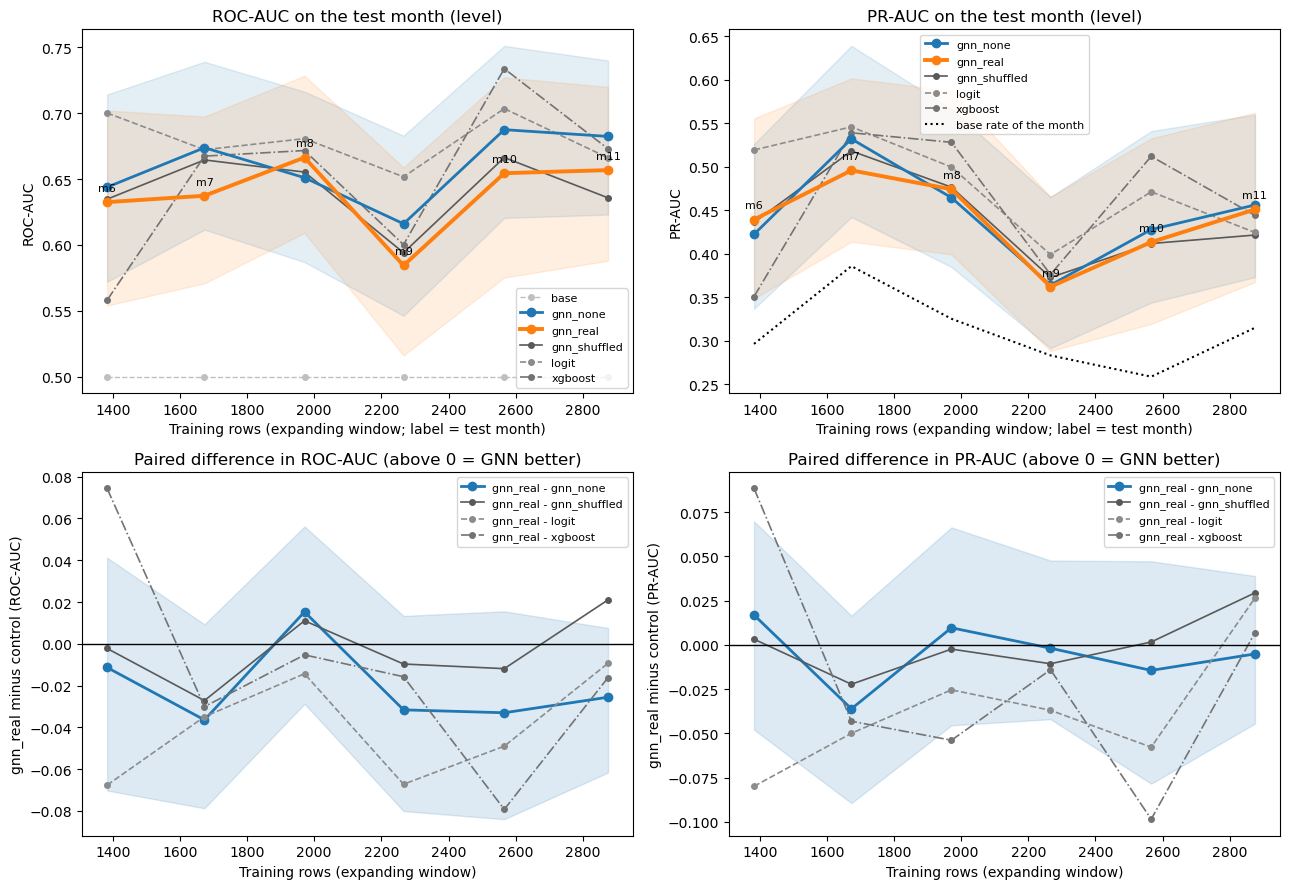


=== level_blind: test performance by fold (expanding window) ===
 fold  n_train  n_test  base_rate  roc_base  roc_gnn_none  roc_gnn_real  roc_gnn_shuffled  roc_logit  pr_base  pr_gnn_none  pr_gnn_real  pr_gnn_shuffled  pr_logit
    6     1383     290      0.297       0.5         0.571         0.561             0.563      0.601    0.297        0.361        0.371            0.383     0.416
    7     1673     298      0.386       0.5         0.601         0.499             0.525      0.585    0.386        0.467        0.386            0.399     0.485
    8     1971     295      0.325       0.5         0.599         0.588             0.570      0.631    0.325        0.436        0.416            0.445     0.465
    9     2266     300      0.283       0.5         0.544         0.561             0.583      0.576    0.283        0.328        0.381            0.413     0.352
   10     2566     309      0.259       0.5         0.610         0.590             0.589      0.633    0.259        0.

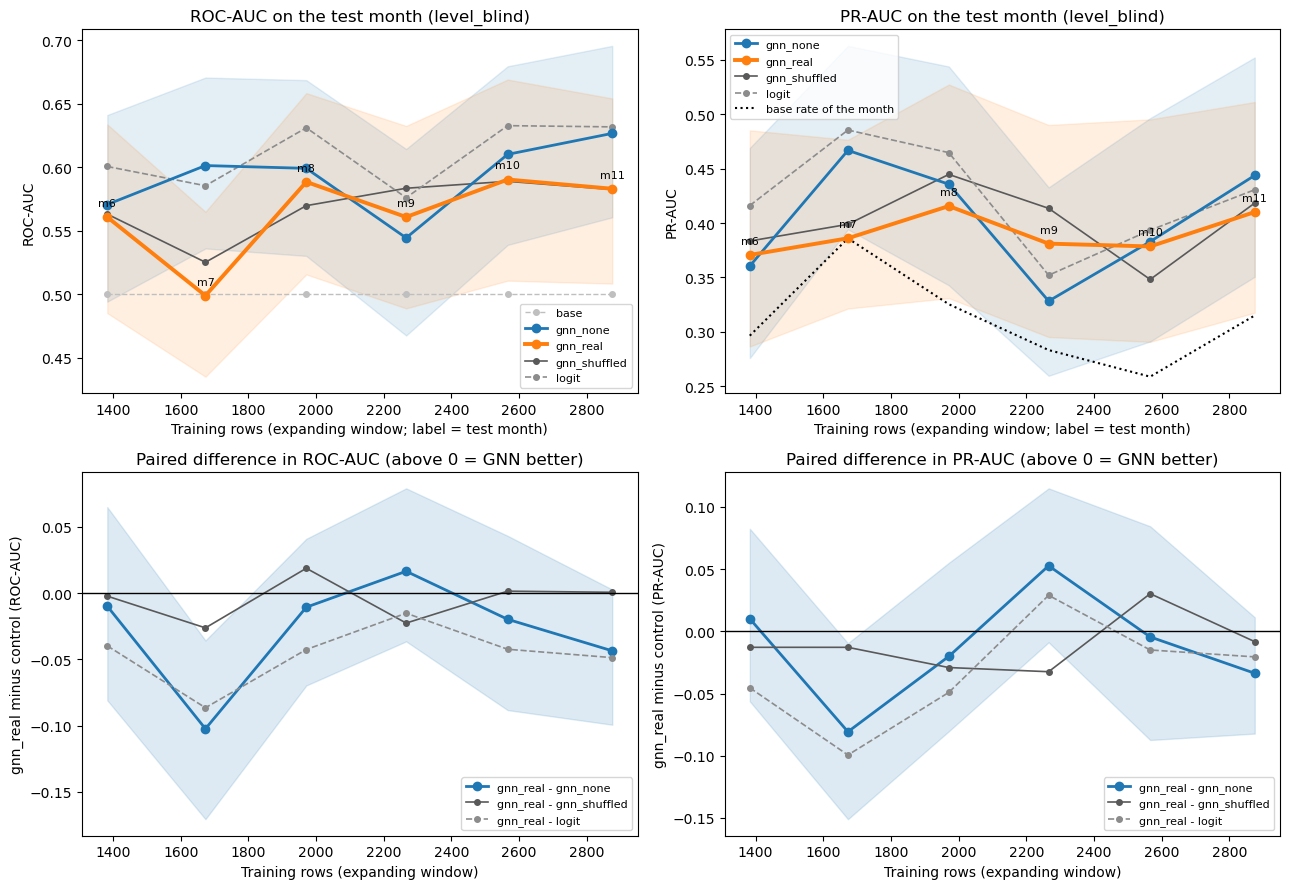

In [73]:
VARIANTS    = [v for v in ["level", "level_blind"] if v in results_store]
rng = np.random.default_rng(7)
n_train = {int(f["test_t"]): len(f["train"]) for f in folds}      # size of the training window of each fold

for VARIANT in VARIANTS:
    preds = results_store[VARIANT]

    # one row per test athlete-month, p averaged over seeds, one column per model (same as the pooled table)
    avg = preds.groupby(["model", "idx"], as_index=False).agg(y=("y", "first"), p=("p", "mean"), fold=("fold", "first"))
    T = avg.pivot(index="idx", columns="model", values="p")
    T = T.join(avg.drop_duplicates("idx").set_index("idx")[["y", "fold"]])
    MODELS   = [c for c in T.columns if c not in ("y", "fold")]
    assert "gnn_real" in MODELS, f"gnn_real not found, models available: {MODELS}"
    CONTROLS = [m for m in MODELS if m not in ("gnn_real", "base")]

    # ---- one point of the curve per fold (= per test month) ----
    rows = []
    for t, g in T.groupby("fold"):
        yy = g["y"].to_numpy().astype(int)
        P  = {m: g[m].to_numpy() for m in MODELS}
        rec = {"fold": int(t), "n_train": n_train[int(t)], "n_test": len(g), "base_rate": yy.mean()}
        for m in MODELS:
            rec[f"roc_{m}"] = roc_auc_score(yy, P[m])
            rec[f"pr_{m}"]  = average_precision_score(yy, P[m])

        # paired bootstrap: the SAME resampled rows for every model (each athlete appears once per test month)
        bs = {(m, k): [] for m in MODELS for k in ("roc", "pr")}
        for _ in range(N_BOOT_FOLD):
            pos = rng.integers(0, len(g), len(g))
            yb = yy[pos]
            if yb.min() == yb.max():
                for key in bs:
                    bs[key].append(np.nan)
                continue
            for m in MODELS:
                bs[(m, "roc")].append(roc_auc_score(yb, P[m][pos]))
                bs[(m, "pr")].append(average_precision_score(yb, P[m][pos]))
        bs = {key: np.array(v, dtype=float) for key, v in bs.items()}

        for m in MODELS:
            for k in ("roc", "pr"):
                rec[f"{k}_{m}_lo"], rec[f"{k}_{m}_hi"] = np.nanpercentile(bs[(m, k)], [2.5, 97.5])
        for m in CONTROLS:                                                   # gnn_real minus control, same resamples
            for k in ("roc", "pr"):
                d = bs[("gnn_real", k)] - bs[(m, k)]
                rec[f"d{k}_{m}"] = rec[f"{k}_gnn_real"] - rec[f"{k}_{m}"]
                rec[f"d{k}_{m}_lo"], rec[f"d{k}_{m}_hi"] = np.nanpercentile(d, [2.5, 97.5])
        rows.append(rec)

    lc = pd.DataFrame(rows).sort_values("n_train").reset_index(drop=True)

    # ---- tables ----
    print(f"\n=== {VARIANT}: test performance by fold (expanding window) ===")
    cols = ["fold", "n_train", "n_test", "base_rate"] + [f"roc_{m}" for m in MODELS] + [f"pr_{m}" for m in MODELS]
    print(lc[cols].round(3).to_string(index=False))

    diff = lc[["fold", "n_train"]].copy()
    for m in CONTROLS:
        for k in ("roc", "pr"):
            diff[f"{k.upper()}: gnn_real - {m}"] = [f"{d:+.3f} [{lo:+.3f}, {hi:+.3f}]"
                for d, lo, hi in zip(lc[f"d{k}_{m}"], lc[f"d{k}_{m}_lo"], lc[f"d{k}_{m}_hi"])]
    print(f"\n=== {VARIANT}: paired differences by fold, mean [95% CI]; a CI that excludes 0 = real difference in that month ===")
    print(diff.to_string(index=False))

    # ---- figure: only gnn_real and gnn_none are coloured, every other model is grey ----
    HIGHLIGHT   = {"gnn_real": "tab:orange", "gnn_none": "tab:blue"}
    GREY_STYLES = [("0.35", "-"), ("0.55", "--"), ("0.45", "-."), ("0.65", ":")]
    style_of, k_grey = {}, 0
    for m in MODELS:
        if m in HIGHLIGHT:
            style_of[m] = (HIGHLIGHT[m], "-", 2.8 if m == "gnn_real" else 2.0)
        elif m == "base":
            style_of[m] = ("0.75", "--", 1.0)                       # constant model: light dashed line
        else:
            col, ls = GREY_STYLES[k_grey % len(GREY_STYLES)]
            style_of[m] = (col, ls, 1.2)
            k_grey += 1

    fig, ax = plt.subplots(2, 2, figsize=(13, 9))

    for j, (k, name) in enumerate([("roc", "ROC-AUC"), ("pr", "PR-AUC")]):
        a = ax[0, j]
        for m in MODELS:
            if m == "base" and k == "pr":
                continue                                            # same as the base-rate line drawn below
            col, ls, lw = style_of[m]
            a.plot(lc["n_train"], lc[f"{k}_{m}"], marker="o", markersize=6 if m in HIGHLIGHT else 4,
                   color=col, linestyle=ls, linewidth=lw, label=m, zorder=3 if m in HIGHLIGHT else 2)
            if m in HIGHLIGHT:                                      # confidence band only for the coloured models
                a.fill_between(lc["n_train"], lc[f"{k}_{m}_lo"], lc[f"{k}_{m}_hi"], color=col, alpha=0.12)
        if k == "pr":
            a.plot(lc["n_train"], lc["base_rate"], linestyle=":", color="black", label="base rate of the month")
        for _, r in lc.iterrows():
            a.annotate(f"m{int(r['fold'])}", (r["n_train"], r[f"{k}_gnn_real"]),
                       textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8)
        a.set_title(f"{name} on the test month ({VARIANT})")
        a.set_xlabel("Training rows (expanding window; label = test month)")
        a.set_ylabel(name)
        a.legend(fontsize=8)

        a = ax[1, j]
        for m in CONTROLS:
            col, ls, lw = style_of[m]
            a.plot(lc["n_train"], lc[f"d{k}_{m}"], marker="o", markersize=6 if m in HIGHLIGHT else 4,
                   color=col, linestyle=ls, linewidth=lw, label=f"gnn_real - {m}")
            if m in HIGHLIGHT:
                a.fill_between(lc["n_train"], lc[f"d{k}_{m}_lo"], lc[f"d{k}_{m}_hi"], color=col, alpha=0.15)
        a.axhline(0, color="black", linewidth=1)
        a.set_title(f"Paired difference in {name} (above 0 = GNN better)")
        a.set_xlabel("Training rows (expanding window)")
        a.set_ylabel(f"gnn_real minus control ({name})")
        a.legend(fontsize=8)

    plt.tight_layout()
    plt.show()

## 10.9 Results (reference run)

*Numbers below come from the reference run of the full-feature variant (`level`); small differences on a new run are possible (GPU non-determinism, library versions). In that run the `shuffled` control was built by shuffling the targets of the symmetric edge list, which produced a directed graph; the control is now rewired symmetrically, so `gnn_shuffled` and its paired comparisons should be re-read from a new run. Base rate of increases: 0.311.*

| Model | ROC-AUC | PR-AUC |
|---|---|---|
| Base rate (constant) | 0.480 | 0.300 |
| GNN, no edges (`gnn_none`) | 0.627 | 0.404 |
| GNN, real edges (`gnn_real`) | 0.609 | 0.409 |
| GNN, shuffled edges (`gnn_shuffled`) | 0.612 | 0.403 |
| Logistic regression, own features (`logit`) | 0.646 | 0.439 |
| XGBoost with explicit contact variables (section 9) | 0.638 | 0.437 |

- **All models beat the base rate**, so next-month increases in running frequency are partly predictable (top-decile lift of about 1.5 to 1.7).
- **Real contacts do not help.** The GNN with the real kudos graph is **not better** than the same GNN without any edges (ROC difference -0.018, 95% CI [-0.035, -0.001]; PR-AUC difference +0.006, CI [-0.015, +0.028]) or with randomly rewired edges (ROC -0.002, CI [-0.016, +0.011]).
- **A simple model on the athlete's own history is as good as, or better than, any model using the network.** The logistic regression is significantly better than the real-edge GNN (ROC difference -0.036, CI [-0.055, -0.018]), and XGBoost, which receives explicit exposure variables, does not improve on it.
- **Uncertainty is large.** Each test month has about 300 observations (single-month ROC standard error about 0.04), so month-by-month differences should not be over-interpreted.

**Interpretation.** In this predictive set-up, the information carried by an athlete's contacts at month *t* does not add to what the athlete's own recent behaviour already tells about next month's change. This is *consistent with*, but does not prove, the absence of social influence: the data are small and observational, the outcome is a coarse ordinal category, and influence from contacts may act over longer lags or through channels not recorded here.

# 11. Synthesis, limitations and possible extensions

## 11.1 Answer to the research question

1. **Strava as infrastructure for social aggregation (Part II).** In four of the five clubs (9 to 76 athletes) kudos form **cohesive and reciprocal communities**: roughly 80% of kudos ties belong to a pair that exchanges kudos in the same month, strong ties are highly clustered and paths are short. The largest club (159 athletes) is a looser structure, with a dense core, many weakly attached or isolated members and shorter-lived ties. Aggregation exists but its intensity depends strongly on club size.
2. **Position of higher-status athletes.** The raw comparison suggests that high-status athletes have fewer bridging ties, but this is an effect of the number of ties: it disappears when athletes with a single tie are excluded and the labels are shuffled within club and degree (difference +0.034, p = 0.63). Embeddedness does not differ either (+0.058, p = 0.73). Commitment level shows only weak homophily and no relation with bridging. The tests have limited power because the low-status group is small.
3. **Diffusion (Part III).** The behaviour of contacts does **not** add predictive information on next-month increases in running frequency beyond the athlete's own history, in a leakage-free out-of-time evaluation with network controls. The structural analysis does not identify a distinct position for high-status athletes, and the predictive analysis does not find evidence of diffusion to their contacts.

## 11.2 Limitations

- **Five clubs and small samples.** Two clubs have fewer than 30 athletes, and each test month has about 300 observations; tests have limited power.
- **Operationalisation.** Kudos are a proxy for social ties and recognition; `novice` measures Strava tenure, not running experience; the outcome is an ordinal weekly category (0 to 7) with a ceiling.
- **Observational data.** Similarity between connected athletes may reflect selection into ties rather than influence; the predictive design cannot separate the two.
- **Time structure.** Monthly waves and a one-month horizon may miss slower influence processes; annual aggregation in Part II hides the timing of ties.

## 11.3 Possible extensions

Longer prediction horizons and multi-month exposure; stochastic actor-oriented models (SIENA), the natural framework for the RSiena-format data, to separate selection from influence; alternative thresholds for persistent ties and for the high/low split (terciles or continuous measures); and replication on larger clubs.